# Лабораторная работа 1 — рабочий ноутбук

**ФИО:**
**Файлы данных:**

Этот ноутбук — чистовой рабочий документ, а не черновик. Он должен
исполняться сверху вниз без ошибок на выданном вам **сыром** файле
и на выходе давать очищенную таблицу и `cleaning_log.csv`.

Разделы ниже обязательны, порядок менять не нужно. Внутри раздела
добавляйте столько ячеек, сколько нужно. Если какой-то раздел у вас
пустой — напишите в нём одной строкой, почему.

## 0. Окружение и настройки

In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

# Пути к файлам вашего варианта S32
RAW_CLIENTS = os.path.join("data", "S32", "clients.csv")
RAW_TXN = os.path.join("data", "S32", "transactions.csv")

## 1. Загрузка сырых данных

Файлы выгружены разными системами. Убедитесь, что они прочитались
**правильно**: кодировка, разделитель, десятичный разделитель, типы,
даты, идентификаторы.

In [59]:
import csv

def detect_file_params(filepath):
    """Определяет кодировку и разделитель файла."""
    # 1. Проверяем популярные кодировки
    encodings = ['utf-8', 'windows-1251', 'cp1251', 'utf-8-sig']
    correct_enc = None
    sample_text = ""
    
    for enc in encodings:
        try:
            with open(filepath, 'r', encoding=enc) as f:
                sample_text = "".join([f.readline() for _ in range(15)])
                correct_enc = enc
                break
        except (UnicodeDecodeError, UnicodeError):
            continue
            
    # 2. Определяем разделитель колонок
    sniffer = csv.Sniffer()
    try:
        dialect = sniffer.sniff(sample_text)
        delimiter = dialect.delimiter
    except Exception:
        # Резервная эвристика, если sniffer не справился
        first_line = sample_text.split('\n')[0]
        delimiter = ';' if ';' in first_line else (',' if ',' in first_line else '\t')
        
    return correct_enc, delimiter

# Исследуем параметры файлов
clients_enc, clients_sep = detect_file_params(RAW_CLIENTS)
txn_enc, txn_sep = detect_file_params(RAW_TXN)

print(f"Параметры {RAW_CLIENTS}: кодировка={clients_enc}, разделитель='{clients_sep}'")
print(f"Параметры {RAW_TXN}: кодировка={txn_enc}, разделитель='{txn_sep}'")

# Загружаем сырые таблицы
# Пока не форсируем типы и парсинг дат, чтобы в разделе аудита увидеть исходные данные
df_clients_raw = pd.read_csv(RAW_CLIENTS, encoding=clients_enc, sep=clients_sep)
df_txn_raw = pd.read_csv(RAW_TXN, encoding=txn_enc, sep=txn_sep)

print("\n=== clients.csv: первые 3 строки ===")
display(df_clients_raw.head(3))
print(f"Размер: {df_clients_raw.shape[0]} строк, {df_clients_raw.shape[1]} колонок")

print("\n=== transactions.csv: первые 3 строки ===")
display(df_txn_raw.head(3))
print(f"Размер: {df_txn_raw.shape[0]} строк, {df_txn_raw.shape[1]} колонок")

Параметры data\S32\clients.csv: кодировка=utf-8, разделитель=','
Параметры data\S32\transactions.csv: кодировка=windows-1251, разделитель=';'

=== clients.csv: первые 3 строки ===


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
0,C000864,1959-02-13,М,Нижний Новгород,Массовый,Серебро,Дебетовая,11.02.2021,29.07.2024,Не указан,37200.0,Да,2024-12,NaN,300,Нет
1,C000608,1980-05-27,М,Санкт-Петербург,Массовый,Серебро,Дебетовая,08.06.2012,19.05.2018,Не указан,51400.0,Да,2024-06,NaN,131,Да
2,C005220,1963-07-31,М,Санкт Петербург,Зарплатный,Золото,Дебетовая,15.02.2023,26.07.2024,Зарплата в нашем банке,115200.0,Да,2025-03,5.0,845,Нет


Размер: 5693 строк, 16 колонок

=== transactions.csv: первые 3 строки ===


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
0,990147,C001784,2023-12-01 05:36:36,"439,6",RUB,Связь и интернет,4814,СБП,успешно
1,990049,C002958,2023-12-04 11:32:23,"48461,62",RUB,Одежда и обувь,5651,Карта,успешно
2,990214,C002389,2023-12-10 05:52:56,"763,12",RUB,Связь и Интернет,4814,Онлайн-банк,успешно


Размер: 628754 строк, 9 колонок


## 2. Аудит качества

Здесь вы ничего не исправляете — только находите и измеряете.
Для каждой метрики качества заранее определите знаменатель.

### 2.1. Объём, типы, ключи, единица наблюдения

In [60]:
print("=== 2.1. ОБЪЁМ И СТРУКТУРА ДАННЫХ ===")
print(f"Клиенты (clients.csv): {df_clients_raw.shape[0]} строк, {df_clients_raw.shape[1]} колонок")
print(f"Транзакции (transactions.csv): {df_txn_raw.shape[0]} строк, {df_txn_raw.shape[1]} колонок\n")

print("--- Типы данных clients.csv ---")
print(df_clients_raw.dtypes)

print("\n--- Типы данных transactions.csv ---")
print(df_txn_raw.dtypes)

print("\nЕдиница наблюдения:")
print("- Таблица clients: 1 строка = 1 уникальный действующий клиент банка на 30.06.2025")
print("- Таблица transactions: 1 строка = 1 операция по банковской карте")

=== 2.1. ОБЪЁМ И СТРУКТУРА ДАННЫХ ===
Клиенты (clients.csv): 5693 строк, 16 колонок
Транзакции (transactions.csv): 628754 строк, 9 колонок

--- Типы данных clients.csv ---
client_id              object
birth_date             object
gender                 object
city                   object
segment                object
loyalty_tier           object
card_type              object
registration_date      object
card_open_date         object
income_source          object
monthly_income        float64
has_mobile_app         object
app_last_login         object
satisfaction_score    float64
branch_code             int64
marketing_opt_in       object
dtype: object

--- Типы данных transactions.csv ---
txn_id           int64
client_id       object
txn_datetime    object
amount          object
currency        object
category        object
mcc_code         int64
channel         object
status          object
dtype: object

Единица наблюдения:
- Таблица clients: 1 строка = 1 уникальный действующий

### 2.2. Дубли

In [61]:
print("=== 2.2. АУДИТ ДУБЛИКАТОВ ===")

# 1. Полные дубликаты строк
full_dup_clients = df_clients_raw.duplicated().sum()
full_dup_txn = df_txn_raw.duplicated().sum()

print(f"Полные дубли в clients: {full_dup_clients} из {len(df_clients_raw)} строк ({full_dup_clients/len(df_clients_raw):.4%})")
print(f"Полные дубли в transactions: {full_dup_txn} из {len(df_txn_raw)} строк ({full_dup_txn/len(df_txn_raw):.4%})")

# 2. Дубликаты по ключевым полям (ID)
key_dup_clients = df_clients_raw.duplicated(subset=['client_id']).sum()
key_dup_txn = df_txn_raw.duplicated(subset=['txn_id']).sum()

print(f"\nДубли по client_id в clients: {key_dup_clients} из {len(df_clients_raw)} ({key_dup_clients/len(df_clients_raw):.4%})")
print(f"Дубли по txn_id в transactions: {key_dup_txn} из {len(df_txn_raw)} ({key_dup_txn/len(df_txn_raw):.4%})")
print("=" * 70)
print("=== ДЕТАЛЬНЫЙ АНАЛИЗ НЕПОЛНЫХ ДУБЛИКАТОВ ПО ID ===")
print("=" * 70)

# 1. Анализ clients.csv
# Отбрасываем абсолютно полные дубли, чтобы остались только конфликтующие
clients_no_exact_dups = df_clients_raw.drop_duplicates()
conflicting_clients = clients_no_exact_dups[clients_no_exact_dups.duplicated(subset=['client_id'], keep=False)]

print(f"\n[clients.csv] Строк с конфликтующими client_id: {len(conflicting_clients)}")
print(f"Уникальных client_id среди них: {conflicting_clients['client_id'].nunique()}")

if len(conflicting_clients) > 0:
    print("\nПримеры конфликтующих записей клиентов (сравните строки с одинаковым client_id):")
    # Сортируем по ID, чтобы строки одного клиента шли рядом
    display(conflicting_clients.sort_values(by='client_id'))

# 2. Анализ transactions.csv
txn_no_exact_dups = df_txn_raw.drop_duplicates()
conflicting_txns = txn_no_exact_dups[txn_no_exact_dups.duplicated(subset=['txn_id'], keep=False)]

print(f"\n[transactions.csv] Строк с конфликтующими txn_id: {len(conflicting_txns)}")
print(f"Уникальных txn_id среди них: {conflicting_txns['txn_id'].nunique()}")

if len(conflicting_txns) > 0:
    print("\nПримеры конфликтующих транзакций (первые 6 строк):")
    display(conflicting_txns.sort_values(by='txn_id').head(6))

if len(conflicting_txns) > 0:
    # 1. Удаляем колонку с датой и смотрим, схлопнутся ли строки в идеальные дубликаты
    txns_without_date = conflicting_txns.drop(columns=['txn_datetime'])
    deduped_without_date = txns_without_date.drop_duplicates()
    
    # Если после схлопывания количество строк равно количеству уникальных ID, значит других отличий нет
    is_only_date_diff = len(deduped_without_date) == conflicting_txns['txn_id'].nunique()
    
    if is_only_date_diff:
        print("\n✅ ГИПОТЕЗА ПОДТВЕРЖДЕНА: Все дубликаты отличаются ИСКЛЮЧИТЕЛЬНО колонкой `txn_datetime`.")
        
        # 2. Дополнительно проверим, в чем именно разница в датах (длина строки)
        lens = conflicting_txns['txn_datetime'].astype(str).str.len().unique()
        print(f"Длины строк в колонке дат у дублей: {sorted(lens)}")
        print("(Ожидается 10 символов для 'YYYY-MM-DD' и 19 символов для 'YYYY-MM-DD HH:MM:SS')")
    else:
        print("\n❌ ГИПОТЕЗА ОПРОВЕРГНУТА: Есть строки, которые отличаются суммами, статусами или категориями!")
        
        # Находим и выводим те ID, которые отличаются не только датой
        bad_ids = deduped_without_date[deduped_without_date.duplicated(subset=['txn_id'], keep=False)]['txn_id'].unique()
        display(conflicting_txns[conflicting_txns['txn_id'].isin(bad_ids)].sort_values(by='txn_id').head(10))

=== 2.2. АУДИТ ДУБЛИКАТОВ ===
Полные дубли в clients: 42 из 5693 строк (0.7377%)
Полные дубли в transactions: 1279 из 628754 строк (0.2034%)

Дубли по client_id в clients: 55 из 5693 (0.9661%)
Дубли по txn_id в transactions: 1500 из 628754 (0.2386%)
=== ДЕТАЛЬНЫЙ АНАЛИЗ НЕПОЛНЫХ ДУБЛИКАТОВ ПО ID ===

[clients.csv] Строк с конфликтующими client_id: 26
Уникальных client_id среди них: 13

Примеры конфликтующих записей клиентов (сравните строки с одинаковым client_id):


,client_id,birth_date,gender,city,segment,loyalty_tier,card_type,registration_date,card_open_date,income_source,monthly_income,has_mobile_app,app_last_login,satisfaction_score,branch_code,marketing_opt_in
2373,C000122,1975-09-25,Ж,Новосибирск,Премиальный,Базовый,Кредитная,20.06.2019,26.04.2021,Не указан,55600.0,Нет,NaN,3.0,650,Да
2444,C000122,1975-09-25,Ж,ЕКАТЕРИНБУРГ,Массовый,Базовый,Кредитная,20.06.2019,26.04.2021,Не указан,55600.0,Нет,NaN,3.0,650,Да
230,C000166,1952-09-04,Ж,Нижний Новгород,Премиальный,Серебро,Кредитная,01.07.2016,03.01.2021,Зарплата в нашем банке,83700.0,Да,2024-12,NaN,106,Да
5016,C000166,1952-09-04,Ж,г. Москва,Зарплатный,Серебро,Кредитная,01.07.2016,03.01.2021,Зарплата в нашем банке,83700.0,Да,2024-12,NaN,106,Да
4506,C000183,1984-01-12,Ж,Москва,Зарплатный,Базовый,Дебетовая,06.12.2021,21.04.2022,Зарплата в нашем банке,54000.0,Да,2024-06,2.0,854,Нет
3889,C000183,1984-01-12,Ж,Екатеринбург,Private,Базовый,Дебетовая,06.12.2021,21.04.2022,Зарплата в нашем банке,54000.0,Да,2024-06,2.0,854,Нет
2745,C001680,1973-12-13,М,Екатеринбург,Массовый,Базовый,Дебетовая,25.11.2011,01.05.2016,Зарплата в другом банке,69500.0,Да,2024-06,3.0,306,Нет
3412,C001680,1973-12-13,М,Москва,Зарплатный,Базовый,Дебетовая,25.11.2011,01.05.2016,Зарплата в другом банке,69500.0,Да,2024-06,3.0,306,Нет
725,C002365,1981-06-23,Ж,Москва,Массовый,Серебро,Дебетовая,17.08.2016,23.11.2020,Не указан,30700.0,Да,2024-05,NaN,458,Да
3723,C002365,1981-06-23,Ж,МОСКВА,Массовый,Серебро,Дебетовая,17.08.2016,23.11.2020,Не указан,30700.0,Да,2024-05,NaN,458,Да



[transactions.csv] Строк с конфликтующими txn_id: 442
Уникальных txn_id среди них: 221

Примеры конфликтующих транзакций (первые 6 строк):


,txn_id,client_id,txn_datetime,amount,currency,category,mcc_code,channel,status
5066,105052,C002523,2024-01-06 13:43:43,"3358,1",RUB,Одежда и обувь,5651,СБП,успешно
5067,105052,C002523,2024-01-06,"3358,1",RUB,Одежда и обувь,5651,СБП,успешно
7681,107662,C001229,2024-01-08,"1578,1",RUB,АЗС,5541,Онлайн-банк,успешно
7682,107662,C001229,2024-01-08 23:22:30,"1578,1",RUB,АЗС,5541,Онлайн-банк,успешно
7836,107816,C001710,2024-01-09,"1222,81",RUB,Кафе и рестораны,5812,Токен,успешно
7837,107816,C001710,2024-01-09 10:38:33,"1222,81",RUB,Кафе и рестораны,5812,Токен,успешно



✅ ГИПОТЕЗА ПОДТВЕРЖДЕНА: Все дубликаты отличаются ИСКЛЮЧИТЕЛЬНО колонкой `txn_datetime`.
Длины строк в колонке дат у дублей: [np.int64(10), np.int64(19)]
(Ожидается 10 символов для 'YYYY-MM-DD' и 19 символов для 'YYYY-MM-DD HH:MM:SS')


### 2.3. Соответствие данных описанию полей из задания

In [62]:
print("=" * 70)
print("=== 2.3. ПОЛНЫЙ ДИАГНОСТИЧЕСКИЙ АУДИТ ПОЛЕЙ И БИЗНЕС-ПРАВИЛ ===")
print("=" * 70)

# Вспомогательная дата среза по ТЗ (действующие клиенты на 30.06.2025)
SNAPSHOT_DATE = pd.to_datetime("2025-06-30")



# =========================================================================
# БЛОК 1. КЛИЕНТЫ: ДАТЫ И ВОЗРАСТ (Пункты 10, 11 и человеческий возраст)
# =========================================================================
print("\n>>> 1. АНАЛИЗ ДАТ И ВОЗРАСТА КЛИЕНТОВ")

# Временный парсинг дат для проверки
b_dates = pd.to_datetime(df_clients_raw['birth_date'], errors='coerce')
r_dates = pd.to_datetime(df_clients_raw['registration_date'], format='%d.%m.%Y', errors='coerce')
c_dates = pd.to_datetime(df_clients_raw['card_open_date'], format='%d.%m.%Y', errors='coerce')

# Расчет возраста на дату среза
ages = (SNAPSHOT_DATE - b_dates).dt.days // 365.25

print(f"Возраст клиентов (лет): min = {ages.min():.1f}, median = {ages.median():.1f}, max = {ages.max():.1f}")
unrealistic_age = ((ages < 14) | (ages > 100)).sum()
print(f"Неправдоподобный возраст (< 14 или > 100 лет): {unrealistic_age} из {len(df_clients_raw)}")

# Логика хронологии: Рождение -> Регистрация в банке -> Открытие карты -> Срез (30.06.2025)
future_reg = (r_dates > SNAPSHOT_DATE).sum()
future_card = (c_dates > SNAPSHOT_DATE).sum()
reg_before_birth = (r_dates < b_dates).sum()
card_before_reg = (c_dates < r_dates).sum()

print(f"Регистраций 'из будущего' (> 30.06.2025): {future_reg}")
print(f"Открытий карт 'из будущего' (> 30.06.2025): {future_card}")
print(f"Регистрация в банке раньше рождения: {reg_before_birth}")
print(f"Карта открыта раньше даты регистрации в банке: {card_before_reg}")


# =========================================================================
# БЛОК 2. КЛИЕНТЫ: ГОРОДА И ТЕКСТ (Пункт 8)
# =========================================================================
print("\n>>> 2. РАЗНОБОЙ В ГОРОДАХ (city)")
city_counts = df_clients_raw['city'].value_counts(dropna=False)
print("Все варианты написания городов и их частота:")
for city, cnt in city_counts.items():
    print(f"  - '{city}': {cnt}")


# =========================================================================
# БЛОК 3. КЛИЕНТЫ: ДОХОДЫ И ИХ ИСТОЧНИКИ (Пункты 12, 13, 17)
# =========================================================================
print("\n>>> 3. ДОХОДЫ И ИСТОЧНИКИ (monthly_income, income_source)")
print("Источники доходов:")
print(df_clients_raw['income_source'].value_counts(dropna=False))

inc = df_clients_raw['monthly_income']
print(f"\nАномальный доход (<0): {(inc < 0).sum()} из {len(df_clients_raw)}")
print(f"Пропущенный доход (NaN): {inc.isna().sum()} из {len(df_clients_raw)}")

valid_inc = inc[inc > 0]
print("Статистика по положительным доходам:")
print(f"  min = {valid_inc.min():,.0f}, median = {valid_inc.median():,.0f}, 99% квантиль = {valid_inc.quantile(0.99):,.0f}, max = {valid_inc.max():,.0f}")

# =========================================================
# ПРОВЕРКА ГИПОТЕЗЫ: УКАЗАНИЕ ЗАРПЛАТЫ В ТЫСЯЧАХ
# =========================================================
small_inc = valid_inc[valid_inc < 2000]
print(f"\nДетальный разрез доходов < 2000 руб. (всего {len(small_inc)} чел.):")

# 1. Табличная гистограмма по корзинам
bins = [0, 10, 50, 100, 500, 1000, 2000]
dist = pd.cut(small_inc, bins=bins).value_counts().sort_index()
print("Распределение по интервалам:")
for interval, count in dist.items():
    print(f"  от {interval.left} до {interval.right} руб.: {count} чел.")

# 2. Топ конкретных значений (что именно пишут люди?)
print("\nТоп-10 самых частых значений в этом диапазоне:")
print(small_inc.value_counts().head(10).to_dict())
# =========================================================

agr_to_adv = df_clients_raw['marketing_opt_in'].value_counts(dropna=False)
print("\nКоличества согласных и несогласных с персональной рекламой:")
for opt, count in agr_to_adv.items():
    print(f"{opt} - {count}")


# =========================================================================
# БЛОК 4. КЛИЕНТЫ: МОБИЛЬНОЕ ПРИЛОЖЕНИЕ И ОЦЕНКИ (Пункт 16)
# =========================================================================
print("\n>>> 4. МОБИЛЬНОЕ ПРИЛОЖЕНИЕ И УДОВЛЕТВОРЕННОСТЬ")
# Логика: если приложения нет, то дата входа должна быть пустой
no_app_with_login = ((df_clients_raw['has_mobile_app'] == 'Нет') & (df_clients_raw['app_last_login'].notna())).sum()
print(f"Клиентов БЕЗ приложения, но С датой последнего входа: {no_app_with_login}")

has_app_no_login = ((df_clients_raw['has_mobile_app'] == 'Да') & (df_clients_raw['app_last_login'].isna())).sum()
print(f"Клиентов С приложением, но БЕЗ даты последнего входа: {has_app_no_login}")

print("Пропуски в satisfaction_score:", df_clients_raw['satisfaction_score'].isna().sum(), f"({df_clients_raw['satisfaction_score'].isna().mean():.2%})")


# =========================================================================
# БЛОК 5. ТРАНЗАКЦИИ: СООТВЕТСТВИЕ MCC И КАТЕГОРИЙ (Пункты 9, 15)
# =========================================================================
print("\n>>> 5. КАТЕГОРИИ И MCC-КОДЫ")
mcc_cat_mapping = df_txn_raw.groupby('mcc_code')['category'].unique()
print("Соответствие MCC -> Категории:")
for mcc, cats in mcc_cat_mapping.items():
    print(f"  MCC {mcc}: {list(cats)}")

# Проверка: есть ли категории, у которых несколько разных MCC
cat_mcc_mapping = df_txn_raw.groupby('category')['mcc_code'].unique()

# =========================================================================
# БЛОК 6. ТРАНЗАКЦИИ: СУММЫ, ВАЛЮТЫ И СТАТУСЫ (Пункты 14, 17)
# =========================================================================
print("\n>>> 6. СУММЫ, ВАЛЮТЫ И СТАТУСЫ ОПЕРАЦИЙ")
# Временная конвертация amount (замена запятой на точку)
amt_numeric = pd.to_numeric(df_txn_raw['amount'].astype(str).str.replace(',', '.'), errors='coerce')

print("Валюты по статусам операций:")
print(pd.crosstab(df_txn_raw['currency'], df_txn_raw['status'], margins=True))

print(f"\nСуммы: min = {amt_numeric.min()}, max = {amt_numeric.max()}")
print(f"Отрицательные суммы: {(amt_numeric < 0).sum()}")
print(f"Нулевые суммы: {(amt_numeric == 0).sum()}")
print(f"Сверхкрупные суммы (> 500 000 руб): {(amt_numeric > 500000).sum()}")

# Как оформлены возвраты: положительной суммой со статусом 'возврат' или отрицательной суммой?
refunds = df_txn_raw[df_txn_raw['status'] == 'возврат']
refused = df_txn_raw[df_txn_raw['status'] == 'отклонено']
accepted = df_txn_raw[df_txn_raw['status'] == 'успешно']
print(f"Минимальная и максимальная суммы возврата: {pd.to_numeric(refunds['amount'].str.replace(',', '.'), errors='coerce').min():.2f}, {pd.to_numeric(refunds['amount'].str.replace(',', '.'), errors='coerce').max():.2f}")
print(f"Минимальная и максимальная суммы отклонения: {pd.to_numeric(refused['amount'].str.replace(',', '.'), errors='coerce').min():.2f}, {pd.to_numeric(refused['amount'].str.replace(',', '.'), errors='coerce').max():.2f}")
print(f"Минимальная и максимальная суммы успешные: {pd.to_numeric(accepted['amount'].str.replace(',', '.'), errors='coerce').min():.2f}, {pd.to_numeric(accepted['amount'].str.replace(',', '.'), errors='coerce').max():.2f}")


# =========================================================================
# БЛОК 7. ТРАНЗАКЦИИ: ДАТЫ ОПЕРАЦИЙ И РЕГИСТРАЦИИ (Пункт 1, 10)
# =========================================================================
print("\n>>> 7. ДАТЫ ТРАНЗАКЦИЙ")
txn_dates = pd.to_datetime(df_txn_raw['txn_datetime'].str[:10], errors='coerce')
print(f"Транзакции раньше 2024-01-01: {(txn_dates < '2024-01-01').sum()} (min date: {txn_dates.min().strftime('%Y-%m-%d')})")
print(f"Транзакции позже 2025-06-30: {(txn_dates > '2025-06-30').sum()} (max date: {txn_dates.max().strftime('%Y-%m-%d')})")
print("=" * 80)
print("=== СВЕРКА MCC-КОДОВ И КАТЕГОРИЙ ТРАТ ===")
print("=" * 80)

# 1. Полная матрица пересечений (строки — MCC, столбцы — категории)
mcc_matrix = pd.crosstab(
    df_txn_raw['mcc_code'], 
    df_txn_raw['category'], 
    margins=True, 
    margins_name="ИТОГО"
)

print("\n--- 1. Матрица транзакций (MCC x Категория):")
display(mcc_matrix)

# 2. Анализ чистоты соответствия: какая категория доминирует для каждого MCC
mcc_summary = []
# Берем данные без строки/столбца ИТОГО
base_cross = pd.crosstab(df_txn_raw['mcc_code'], df_txn_raw['category'])

for mcc in base_cross.index:
    row = base_cross.loc[mcc]
    total_ops = row.sum()
    top_cat = row.idxmax()
    top_ops = row.max()
    match_pct = (top_ops / total_ops) * 100
    
    # Находим, какие еще категории ошибочно попали в этот MCC
    mismatches = row[row > 0].drop(top_cat).to_dict()
    
    mcc_summary.append({
        "MCC": mcc,
        "Доминирующая категория": top_cat,
        "Транзакций доминанты": f"{top_ops:,}",
        "Всего транзакций": f"{total_ops:,}",
        "Доля совпадения": f"{match_pct:.2f}%",
        "Ошибочные категории (шум)": mismatches if mismatches else "Нет"
    })

df_mcc_report = pd.DataFrame(mcc_summary)

print("\n--- 2. Сводка чистоты маппинга MCC -> Категория:")
display(df_mcc_report[["MCC", "Доминирующая категория", "Всего транзакций", "Доля совпадения", "Ошибочные категории (шум)"]])

print("\n>>> 8. Категориальные поля:")
for col in ['gender', 'segment', 'loyalty_tier', 'card_type', 'has_mobile_app', 'marketing_opt_in']:
    unique_vals = df_clients_raw[col].dropna().unique().tolist()
    print(f"{col} (уникальных: {len(unique_vals)}): {unique_vals}")

for col in ['currency', 'channel', 'status']:
    print(f"{col}: {df_txn_raw[col].dropna().unique().tolist()}")


=== 2.3. ПОЛНЫЙ ДИАГНОСТИЧЕСКИЙ АУДИТ ПОЛЕЙ И БИЗНЕС-ПРАВИЛ ===

>>> 1. АНАЛИЗ ДАТ И ВОЗРАСТА КЛИЕНТОВ
Возраст клиентов (лет): min = 22.0, median = 51.0, max = 88.0
Неправдоподобный возраст (< 14 или > 100 лет): 0 из 5693
Регистраций 'из будущего' (> 30.06.2025): 0
Открытий карт 'из будущего' (> 30.06.2025): 0
Регистрация в банке раньше рождения: 0
Карта открыта раньше даты регистрации в банке: 0

>>> 2. РАЗНОБОЙ В ГОРОДАХ (city)
Все варианты написания городов и их частота:
  - 'Москва': 1084
  - 'Нижний Новгород': 730
  - 'Санкт-Петербург': 657
  - 'Казань': 570
  - 'Новосибирск': 549
  - 'Екатеринбург': 461
  - 'Н. Новгород': 234
  - ' москва': 176
  - 'МОСКВА': 176
  - 'г. Москва': 166
  - 'казань': 153
  - 'г. Новосибирск': 147
  - 'ЕКАТЕРИНБУРГ': 125
  - 'г. Санкт-Петербург': 120
  - 'Санкт Петербург': 120
  - 'СПб': 117
  - 'г.Екатеринбург': 108

>>> 3. ДОХОДЫ И ИСТОЧНИКИ (monthly_income, income_source)
Источники доходов:
income_source
Зарплата в нашем банке     2559
Зарплата в д

category,АЗС,Аптеки,Кафе и рестораны,Кафе/рестораны,Одежда и обувь,Онлайн-сервисы,Продукты,Развлечения и досуг,Связь и Интернет,Связь и интернет,Транспорт,кафе и рестораны,ИТОГО
mcc_code,,,,,,,,,,,,,
4111,16,26,20,11,22,7,56,18,9,9,66222,7,66423
4814,29,23,10,4,24,11,65,16,19623,29677,19,4,49505
5411,21,11,10,8,23,11,165006,19,9,7,21,4,165150
5541,57887,19,18,2,20,17,46,13,2,8,26,6,58064
5651,13,18,21,2,64922,16,60,17,6,7,19,4,65105
5812,16,18,48223,16165,31,11,64,18,8,16,15,16013,80598
5815,20,16,13,6,13,43646,57,22,3,14,21,7,43838
5912,18,45807,15,8,20,18,58,23,8,10,25,5,46015
7832,17,13,20,8,24,18,53,53869,3,8,20,3,54056



--- 2. Сводка чистоты маппинга MCC -> Категория:


,MCC,Доминирующая категория,Всего транзакций,Доля совпадения,Ошибочные категории (шум)
0,4111,Транспорт,"66,423",99.70%,"{'АЗС': 16, 'Аптеки': 26, 'Кафе и рестораны': 20, 'Кафе/рестораны': 11, 'Одежда и обувь': 22, 'Онлайн-сервисы': 7, 'Продукты': 56, 'Развлечения и досуг': 18, 'Связь и Интернет': 9, 'Связь и интернет': 9, 'кафе и рестораны': 7}"
1,4814,Связь и интернет,"49,505",59.95%,"{'АЗС': 29, 'Аптеки': 23, 'Кафе и рестораны': 10, 'Кафе/рестораны': 4, 'Одежда и обувь': 24, 'Онлайн-сервисы': 11, 'Продукты': 65, 'Развлечения и досуг': 16, 'Связь и Интернет': 19623, 'Транспорт': 19, 'кафе и рестораны': 4}"
2,5411,Продукты,"165,150",99.91%,"{'АЗС': 21, 'Аптеки': 11, 'Кафе и рестораны': 10, 'Кафе/рестораны': 8, 'Одежда и обувь': 23, 'Онлайн-сервисы': 11, 'Развлечения и досуг': 19, 'Связь и Интернет': 9, 'Связь и интернет': 7, 'Транспорт': 21, 'кафе и рестораны': 4}"
3,5541,АЗС,"58,064",99.70%,"{'Аптеки': 19, 'Кафе и рестораны': 18, 'Кафе/рестораны': 2, 'Одежда и обувь': 20, 'Онлайн-сервисы': 17, 'Продукты': 46, 'Развлечения и досуг': 13, 'Связь и Интернет': 2, 'Связь и интернет': 8, 'Транспорт': 26, 'кафе и рестораны': 6}"
4,5651,Одежда и обувь,"65,105",99.72%,"{'АЗС': 13, 'Аптеки': 18, 'Кафе и рестораны': 21, 'Кафе/рестораны': 2, 'Онлайн-сервисы': 16, 'Продукты': 60, 'Развлечения и досуг': 17, 'Связь и Интернет': 6, 'Связь и интернет': 7, 'Транспорт': 19, 'кафе и рестораны': 4}"
5,5812,Кафе и рестораны,"80,598",59.83%,"{'АЗС': 16, 'Аптеки': 18, 'Кафе/рестораны': 16165, 'Одежда и обувь': 31, 'Онлайн-сервисы': 11, 'Продукты': 64, 'Развлечения и досуг': 18, 'Связь и Интернет': 8, 'Связь и интернет': 16, 'Транспорт': 15, 'кафе и рестораны': 16013}"
6,5815,Онлайн-сервисы,"43,838",99.56%,"{'АЗС': 20, 'Аптеки': 16, 'Кафе и рестораны': 13, 'Кафе/рестораны': 6, 'Одежда и обувь': 13, 'Продукты': 57, 'Развлечения и досуг': 22, 'Связь и Интернет': 3, 'Связь и интернет': 14, 'Транспорт': 21, 'кафе и рестораны': 7}"
7,5912,Аптеки,"46,015",99.55%,"{'АЗС': 18, 'Кафе и рестораны': 15, 'Кафе/рестораны': 8, 'Одежда и обувь': 20, 'Онлайн-сервисы': 18, 'Продукты': 58, 'Развлечения и досуг': 23, 'Связь и Интернет': 8, 'Связь и интернет': 10, 'Транспорт': 25, 'кафе и рестораны': 5}"
8,7832,Развлечения и досуг,"54,056",99.65%,"{'АЗС': 17, 'Аптеки': 13, 'Кафе и рестораны': 20, 'Кафе/рестораны': 8, 'Одежда и обувь': 24, 'Онлайн-сервисы': 18, 'Продукты': 53, 'Связь и Интернет': 3, 'Связь и интернет': 8, 'Транспорт': 20, 'кафе и рестораны': 3}"



>>> 8. Категориальные поля:
gender (уникальных: 2): ['М', 'Ж']
segment (уникальных: 4): ['Массовый', 'Зарплатный', 'Премиальный', 'Private']
loyalty_tier (уникальных: 4): ['Серебро', 'Золото', 'Базовый', 'Платина']
card_type (уникальных: 3): ['Дебетовая', 'Кредитная', 'Премиальная']
has_mobile_app (уникальных: 2): ['Да', 'Нет']
marketing_opt_in (уникальных: 2): ['Нет', 'Да']
currency: ['RUB', 'USD', 'EUR']
channel: ['СБП', 'Карта', 'Онлайн-банк', 'Токен']
status: ['успешно', 'возврат', 'отклонено']


### 2.4. Связь между таблицами

In [63]:
print("=== 2.4. СВЯЗЬ МЕЖДУ ТАБЛИЦАМИ (РЕФЕРЕНЦИАЛЬНАЯ ЦЕЛОСТНОСТЬ) ===")

set_clients_in_dict = set(df_clients_raw['client_id'])
set_clients_in_txn = set(df_txn_raw['client_id'])

# 1. Клиенты, у которых есть транзакции, но их нет в справочнике клиентов
orphan_txns_clients = set_clients_in_txn - set_clients_in_dict
orphan_txns_count = df_txn_raw['client_id'].isin(orphan_txns_clients).sum()
print(f"Транзакций от 'клиентов-призраков' (нет в clients.csv): {orphan_txns_count} из {len(df_txn_raw)} ({orphan_txns_count/len(df_txn_raw):.4%})")
print(f"Уникальных 'клиентов-призраков': {len(orphan_txns_clients)}")

# 2. Клиенты из справочника, у которых ВООБЩЕ нет ни одной транзакции
clients_without_txns = set_clients_in_dict - set_clients_in_txn
print(f"\nКлиентов без единой транзакции: {len(clients_without_txns)} из {len(df_clients_raw)} ({len(clients_without_txns)/len(df_clients_raw):.4%})")

=== 2.4. СВЯЗЬ МЕЖДУ ТАБЛИЦАМИ (РЕФЕРЕНЦИАЛЬНАЯ ЦЕЛОСТНОСТЬ) ===
Транзакций от 'клиентов-призраков' (нет в clients.csv): 30810 из 628754 (4.9002%)
Уникальных 'клиентов-призраков': 362

Клиентов без единой транзакции: 11 из 5693 (0.1932%)


**Выводы по аудиту.** Перечислите найденное: что это, сколько строк,
насколько это мешает решить задачу.

### Выводы по аудиту качества данных

В ходе аудита обнаружены следующие расхождения и дефекты данных:

1. **Нарушение уникальности первичных ключей и дубликаты:**
   - В `clients.csv` обнаружено 55 неуникальных `client_id` (0.95% от 5 693 строк), из них 42 — полные дубликаты строк, а 13 — записи с одинаковым ID, требующие отдельного анализа.
   - В `transactions.csv` обнаружено 1 500 неуникальных `txn_id` (0.24% от 628 754 строк), из них 1 279 — полные технические дубликаты строк.

2. **Ссылочная целостность (Foreign Keys):**
   - 30 810 транзакций (4.90% от 628 754) совершены 362 «клиентами-призраками», отсутствующими в `clients.csv`. Поскольку справочник содержит только действующих клиентов на 30.06.2025, эти клиенты, вероятнее всего, закрыли счета до даты среза. Для кампании по удержанию действующих клиентов эти операции нерелевантны.
   - 11 действующих клиентов (0.19% от 5 693) не совершили ни одной операции за весь период (новые или «мертвые» карты).

3. **Несоответствие форматов и бизнес-описания:**
   - Поле `amount` в транзакциях выгружено как текст с десятичной запятой (требует конвертации во float).
   - Категории трат (`category`): 12 вариантов написания вместо 9 по ТЗ из-за регистра («Связь и интернет» / «Связь и Интернет») и символов («Кафе и рестораны» / «Кафе/рестораны»).
   - Города (`city`): 17 вариантов написания вместо реальных городов из-за регистра, приставок «г.» и сокращений («СПб», «Н. Новгород»).
   - Аномалии значений: доход `monthly_income` содержит отрицательные значения (-999.0), что является кодом отсутствия данных (маркером пропуска).
   - Временные границы: 76 транзакций из 628754(0.01%) выходят за пределы исследуемого периода (включая транзакции из будущего — до августа 2026 года).

## 3. Препроцессинг

На каждое изменение — строка в журнале (раздел 4). Решение «оставить
как есть» тоже является решением и тоже попадает в журнал.

### 3.1. Типы, даты, числа

In [64]:
# 1. Создаем рабочие копии
df_clients = df_clients_raw.copy()
df_txn = df_txn_raw.copy()

# =========================================================================
# ПРЕОБРАЗОВАНИЕ ТИПОВ В transactions
# =========================================================================
# amount: замена запятой на точку и перевод во float
df_txn['amount'] = df_txn['amount'].astype(str).str.replace(',', '.').astype(float)
df_txn['has_time'] = df_txn['txn_datetime'].astype(str).str.len() > 10
df_txn['txn_datetime'] = pd.to_datetime(df_txn['txn_datetime'], format='mixed')
# =========================================================================
# ПРЕОБРАЗОВАНИЕ ТИПОВ В clients
# =========================================================================
df_clients['birth_date'] = pd.to_datetime(df_clients['birth_date'], format='mixed')
df_clients['registration_date'] = pd.to_datetime(df_clients['registration_date'], format='mixed', dayfirst=True)
df_clients['card_open_date'] = pd.to_datetime(df_clients['card_open_date'], format='mixed', dayfirst=True)
df_clients['app_last_login'] = pd.to_datetime(df_clients['app_last_login'], format='mixed')
df_clients['satisfaction_score'] = df_clients['satisfaction_score'].astype('Int64')

# =========================================================================
# СПАСЕНИЕ ДОХОДОВ (monthly_income)
# =========================================================================
# 1. Маркеры отсутствия данных (-999) меняем на NaN
n_neg_inc = (df_clients['monthly_income'] < 0).sum()
df_clients.loc[df_clients['monthly_income'] < 0, 'monthly_income'] = np.nan

# 2. Доходы в тысячах (меньше 2000 руб.) умножаем на 1000
mask_thousands = df_clients['monthly_income'] < 2000
n_thousands = mask_thousands.sum()
df_clients.loc[mask_thousands, 'monthly_income'] = df_clients.loc[mask_thousands, 'monthly_income'] * 1000


print("=== ИТОГИ 3.1: ПРИВЕДЕНИЕ ТИПОВ И ИСПРАВЛЕНИЕ ДОХОДОВ ===")
print(f"Заменено аномальных доходов (-999 -> NaN): {n_neg_inc}")
print(f"Исправлено доходов, введенных в тысячах (умножено на 1000): {n_thousands}")
print(f"Типы дат в transactions: {df_txn['txn_datetime'].dtype}")
print(f"Типы дат в clients: {df_clients['birth_date'].dtype}")

=== ИТОГИ 3.1: ПРИВЕДЕНИЕ ТИПОВ И ИСПРАВЛЕНИЕ ДОХОДОВ ===
Заменено аномальных доходов (-999 -> NaN): 41
Исправлено доходов, введенных в тысячах (умножено на 1000): 132
Типы дат в transactions: datetime64[ns]
Типы дат в clients: datetime64[ns]


### 3.2. Категориальные признаки

In [65]:
print("=" * 80)
print("=== 3.2. НОРМАЛИЗАЦИЯ КАТЕГОРИЙ И ГОРОДОВ ===")
print("=" * 80)

# 1. Приведение 17 вариантов написания городов к 6 чистым городам
city_mapping = {
    'Москва': 'Москва', 'москва': 'Москва', 'МОСКВА': 'Москва', 'г. Москва': 'Москва',
    'Санкт-Петербург': 'Санкт-Петербург', 'г. Санкт-Петербург': 'Санкт-Петербург', 
    'Санкт Петербург': 'Санкт-Петербург', 'СПб': 'Санкт-Петербург',
    'Нижний Новгород': 'Нижний Новгород', 'Н. Новгород': 'Нижний Новгород',
    'Новосибирск': 'Новосибирск', 'г. Новосибирск': 'Новосибирск',
    'Казань': 'Казань', 'казань': 'Казань',
    'Екатеринбург': 'Екатеринбург', 'ЕКАТЕРИНБУРГ': 'Екатеринбург', 'г.Екатеринбург': 'Екатеринбург'
}
df_clients['city'] = df_clients['city'].str.strip().map(city_mapping).fillna(df_clients['city'])


# 2. Жесткая привязка категорий к международным кодам MCC (исправление ошибок разметки)
mcc_to_category = {
    4111: 'Транспорт',
    4814: 'Связь и интернет',
    5411: 'Продукты',
    5541: 'АЗС',
    5651: 'Одежда и обувь',
    5812: 'Кафе и рестораны',
    5815: 'Онлайн-сервисы',
    5912: 'Аптеки',
    7832: 'Развлечения и досуг'
}

# Подсчитаем, сколько строк реально поменяло смысл (исключая простые опечатки регистра)
# Для этого приведем сырую категорию к нижнему регистру и сравним с новой
old_cat_lower = df_txn['category'].str.lower().str.replace('ё', 'е').str.strip()
new_cat_lower = df_txn['mcc_code'].map(mcc_to_category).str.lower().str.replace('ё', 'е').str.strip()
n_mcc_fixed = (old_cat_lower != new_cat_lower).sum()

# Перезаписываем категорию эталонным значением
df_txn['category'] = df_txn['mcc_code'].map(mcc_to_category)


print("=== ИТОГИ 3.2: НОРМАЛИЗАЦИЯ ===")
print("Города в clients (ровно 6):", sorted(df_clients['city'].unique()))
print(f"Категории в transactions (ровно {df_txn['category'].nunique()}):", sorted(df_txn['category'].unique()))
print(f"Исправлено смысловых ошибок привязки категории к MCC: {n_mcc_fixed} строк.")

# Проверка: теперь матрица должна быть идеальной диагональю
clean_mcc_cross = pd.crosstab(df_txn['mcc_code'], df_txn['category'])
print("\n>>> Матрица соответствия (теперь 100% идеал):")
display(clean_mcc_cross)

=== 3.2. НОРМАЛИЗАЦИЯ КАТЕГОРИЙ И ГОРОДОВ ===
=== ИТОГИ 3.2: НОРМАЛИЗАЦИЯ ===
Города в clients (ровно 6): ['Екатеринбург', 'Казань', 'Москва', 'Нижний Новгород', 'Новосибирск', 'Санкт-Петербург']
Категории в transactions (ровно 9): ['АЗС', 'Аптеки', 'Кафе и рестораны', 'Одежда и обувь', 'Онлайн-сервисы', 'Продукты', 'Развлечения и досуг', 'Связь и интернет', 'Транспорт']
Исправлено смысловых ошибок привязки категории к MCC: 17859 строк.

>>> Матрица соответствия (теперь 100% идеал):


category,АЗС,Аптеки,Кафе и рестораны,Одежда и обувь,Онлайн-сервисы,Продукты,Развлечения и досуг,Связь и интернет,Транспорт
mcc_code,,,,,,,,,
4111,0,0,0,0,0,0,0,0,66423
4814,0,0,0,0,0,0,0,49505,0
5411,0,0,0,0,0,165150,0,0,0
5541,58064,0,0,0,0,0,0,0,0
5651,0,0,0,65105,0,0,0,0,0
5812,0,0,80598,0,0,0,0,0,0
5815,0,0,0,0,43838,0,0,0,0
5912,0,46015,0,0,0,0,0,0,0
7832,0,0,0,0,0,0,54056,0,0


In [66]:

# =========================================================================
# ДЕДУПЛИКАЦИЯ ТРАНЗАКЦИЙ
# =========================================================================
# Удаляем полные дубликаты
n_full_dup_txn = df_txn.duplicated().sum()
df_txn = df_txn.drop_duplicates().reset_index(drop=True)

# Неполные дубли: сортируем так, чтобы строки с полным временем (длина строки > 10) были первыми
df_txn['dt_len'] = df_txn['txn_datetime'].astype(str).str.len()
df_txn = df_txn.sort_values(by=['txn_id', 'dt_len'], ascending=[True, False])
n_partial_dup_txn = df_txn.duplicated(subset=['txn_id']).sum()
df_txn = df_txn.drop_duplicates(subset=['txn_id'], keep='first').drop(columns=['dt_len']).reset_index(drop=True)



# =========================================================================
# ДЕДУПЛИКАЦИЯ КЛИЕНТОВ
# =========================================================================
# Удаляем полные дубликаты
n_full_dup_clients = df_clients.duplicated().sum()
df_clients = df_clients.drop_duplicates().reset_index(drop=True)
n_partial_dup_clients = df_clients.duplicated(subset=['client_id']).sum()
conflicting_ids = df_clients[df_clients.duplicated(subset=['client_id'], keep=False)]['client_id'].unique()

df_clients = df_clients[~df_clients['client_id'].isin(conflicting_ids)].reset_index(drop=True)




print("=== ИТОГИ 3.1: ДЕДУПЛИКАЦИЯ И ПРИВЕДЕНИЕ ТИПОВ ===")
print(f"Транзакции: удалено полных дублей = {n_full_dup_txn}, усеченных по времени дублей = {n_partial_dup_txn}")
print(f"Итого строк transactions: {len(df_txn)} (все txn_id уникальны: {df_txn['txn_id'].is_unique})")
print(f"\nКлиенты: удалено полных дублей = {n_full_dup_clients}, конфликтующих по сегменту дублей = {2 * n_partial_dup_clients}")
print(f"Итого строк clients: {len(df_clients)} (все client_id уникальны: {df_clients['client_id'].is_unique})")

=== ИТОГИ 3.1: ДЕДУПЛИКАЦИЯ И ПРИВЕДЕНИЕ ТИПОВ ===
Транзакции: удалено полных дублей = 1279, усеченных по времени дублей = 221
Итого строк transactions: 627254 (все txn_id уникальны: True)

Клиенты: удалено полных дублей = 43, конфликтующих по сегменту дублей = 24
Итого строк clients: 5626 (все client_id уникальны: True)


### 3.3. Пропуски

Для каждого поля с пропусками: доля, предположение о механизме, решение.

In [67]:
print("=== 3.3. АУДИТ И РЕШЕНИЕ ПО ПРОПУСКАМ ===\n")

# 1. Пропуски в clients
client_nulls = df_clients.isna().sum()
client_nulls = client_nulls[client_nulls > 0]
for col, cnt in client_nulls.items():
    pct = cnt / len(df_clients)
    print(f"Поле '{col}': {cnt} пропусков из {len(df_clients)} ({pct:.2%})")
no_app_count = (df_clients['has_mobile_app'] == 'Нет').sum()
print(f"Людей без приложения {no_app_count}")


# 2. Пропуски в transactions
txn_nulls = df_txn.isna().sum()
print(f"\nПропусков в transactions: {txn_nulls.sum()}")

print("\nОбоснование решений по пропускам:")
print("1. 'monthly_income': пропущено у 562 клиентов из 5638. (клиент не указал доход добровольно).")
print("   Решение: Оставить NaN. Для группировки клиентов по доходу выделяется категория 'Доход не указан'. Заполнять медианой нельзя, чтобы не искажать распределение богатства.")
print("2. 'satisfaction_score': пропущено у 3 330 клиентов из 5638. (опрос удовлетворенности добровольный).")
print("   Решение: Оставить NaN. Клиенты без ответа — это не 'нейтральные' клиенты, заполнение исказит результаты клиентского опыта.")
print("3. 'app_last_login': пропущено ровно у клиентов с has_mobile_app == 'Нет'.")
print("   Решение: Естественный пропуск (структурный ноль), заполнение не требуется.")

=== 3.3. АУДИТ И РЕШЕНИЕ ПО ПРОПУСКАМ ===

Поле 'monthly_income': 562 пропусков из 5626 (9.99%)
Поле 'app_last_login': 2118 пропусков из 5626 (37.65%)
Поле 'satisfaction_score': 3326 пропусков из 5626 (59.12%)
Людей без приложения 2118

Пропусков в transactions: 0

Обоснование решений по пропускам:
1. 'monthly_income': пропущено у 562 клиентов из 5638. (клиент не указал доход добровольно).
   Решение: Оставить NaN. Для группировки клиентов по доходу выделяется категория 'Доход не указан'. Заполнять медианой нельзя, чтобы не искажать распределение богатства.
2. 'satisfaction_score': пропущено у 3 330 клиентов из 5638. (опрос удовлетворенности добровольный).
   Решение: Оставить NaN. Клиенты без ответа — это не 'нейтральные' клиенты, заполнение исказит результаты клиентского опыта.
3. 'app_last_login': пропущено ровно у клиентов с has_mobile_app == 'Нет'.
   Решение: Естественный пропуск (структурный ноль), заполнение не требуется.


### 3.4. Выбросы

Обнаружение и решение — это два разных шага. Сначала первый, потом второй.

In [68]:
print("=" * 70)
print("=== 3.4. ОБНАРУЖЕНИЕ ВЫБРОСОВ И РЕШЕНИЯ ===")
print("=" * 70)

# =========================================================================
# ШАГ 1. ОБНАРУЖЕНИЕ (ДЕТЕКЦИЯ)
# =========================================================================

# 1. Доходы клиентов (monthly_income)
inc_clean = df_clients['monthly_income'].dropna()
q25_inc, q75_inc = inc_clean.quantile(0.25), inc_clean.quantile(0.75)
iqr_inc = q75_inc - q25_inc
upper_bound_inc = q75_inc + 1.5 * iqr_inc
outliers_inc = df_clients[df_clients['monthly_income'] > upper_bound_inc]

print(f"1. Доходы (monthly_income):")
print(f"   Граница IQR (Q3 + 1.5*IQR): {upper_bound_inc:,.0f} руб.")
print(f"   Клиентов выше границы IQR: {len(outliers_inc)} из {len(inc_clean)} ({len(outliers_inc)/len(inc_clean):.2%})")
print(f"   Маскимум зарплаты {df_clients['monthly_income'].max()} руб")
print(f"   Распределение выбросов по сегментам:")
print(outliers_inc['segment'].value_counts())

# 2. Суммы транзакций (amount)
# Анализируем успешные положительные траты
pos_amounts = df_txn[df_txn['amount'] > 0]['amount']
q25_amt, q75_amt = pos_amounts.quantile(0.25), pos_amounts.quantile(0.75)
iqr_amt = q75_amt - q25_amt
upper_bound_amt = q75_amt + 1.5 * iqr_amt
outliers_amt = df_txn[df_txn['amount'] > upper_bound_amt]

print(f"\n2. Суммы покупок (amount):")
print(f"   Граница IQR: {upper_bound_amt:,.2f} руб., Максимум: {pos_amounts.max():,.2f} руб.")
print(f"   Транзакций выше границы IQR: {len(outliers_amt)} из {len(pos_amounts)} ({len(outliers_amt)/len(pos_amounts):.2%})")

# 3. Возраст клиентов
ages_clean = (pd.to_datetime("2025-06-30") - df_clients['birth_date']).dt.days // 365.25
q25_age, q75_age = ages_clean.quantile(0.25), ages_clean.quantile(0.75)
upper_bound_age = q75_age + 1.5 * (q75_age - q25_age)
lower_bound_age = q25_age - 1.5 * (q75_age - q25_age)
print(f"\n3. Возраст: диапазон от {ages_clean.min():.0f} до {ages_clean.max():.0f} лет.")
print(f"   Выбросов по возрасту (вне [{lower_bound_age:.0f}, {upper_bound_age:.0f}]): {((ages_clean < lower_bound_age) | (ages_clean > upper_bound_age)).sum()}")

print("=" * 70)
print("=== ДЕТАЛЬНЫЙ РАЗБОР ТОПОВЫХ ДОХОДОВ КЛИЕНТОВ ===")
print("=" * 70)

# 1. Топ-15 самых богатых клиентов банка
cols_to_show = ['client_id', 'monthly_income', 'segment', 'loyalty_tier', 'card_type', 'city', 'income_source']
top_earners = df_clients.sort_values(by='monthly_income', ascending=False)[cols_to_show].head(15)

print("\n>>> ТОП-15 клиентов по заявленному доходу:")
display(top_earners)

# 2. Сводка доходов по сегментам клиентов
def p90(x): 
    return x.quantile(0.9)

inc_by_segment = df_clients.groupby('segment')['monthly_income'].agg(
    клиентов='count',
    минимум='min',
    медиана='median',
    перцентиль_90=p90,
    максимум='max'
).loc[['Массовый', 'Зарплатный', 'Премиальный', 'Private']]

print("\n>>> Доходы в разрезе сегментов (руб.):")
display(inc_by_segment.style.format('{:,.0f}'))

# 3. Сколько людей зарабатывают больше 500 000 руб. и кто они?
rich_500k = df_clients[df_clients['monthly_income'] >= 500_000]
print(f"\nКлиентов с доходом >= 500 000 руб.: {len(rich_500k)} чел.")
print(rich_500k['segment'].value_counts())


rich_5k = df_clients[df_clients['monthly_income'] <= 2000]
print(f"\nКлиентов с доходом <= 2 000 руб.: {len(rich_5k)} чел.")
print(rich_5k['segment'].value_counts())


# =========================================================================
# ШАГ 2. ОБОСНОВАНИЕ РЕШЕНИЙ
# =========================================================================
print("\n" + "=" * 50)
print("РЕШЕНИЯ ПО ВЫБРОСАМ (ДЛЯ ЖУРНАЛА ИЗМЕНЕНИЙ):")
print("1. Доходы > границы IQR: ОСТАВИТЬ БЕЗ ИЗМЕНЕНИЙ.")
print("   Обоснование: почти все выбросы приходятся на сегменты 'Премиальный' и 'Private'. Это реальные состоятельные клиенты банка, их удаление исказит финансовый профиль целевой аудитории.")
print("2. Крупные транзакции (до 147 тыс. руб.): ОСТАВИТЬ БЕЗ ИЗМЕНЕНИЙ.")
print("   Обоснование: Для категорий 'Одежда и обувь', 'Развлечения' и покупок премиальных клиентов чеки в 50–140 тыс. руб. являются естественными и экономически обоснованными.")
print("3. Отрицательные суммы: ОСТАВИТЬ (это возвраты покупок, status == 'возврат').")

=== 3.4. ОБНАРУЖЕНИЕ ВЫБРОСОВ И РЕШЕНИЯ ===
1. Доходы (monthly_income):
   Граница IQR (Q3 + 1.5*IQR): 192,450 руб.
   Клиентов выше границы IQR: 399 из 5064 (7.88%)
   Маскимум зарплаты 1026300.0 руб
   Распределение выбросов по сегментам:
segment
Премиальный    190
Private        186
Зарплатный      18
Массовый         5
Name: count, dtype: int64

2. Суммы покупок (amount):
   Граница IQR: 4,976.20 руб., Максимум: 147,058.41 руб.
   Транзакций выше границы IQR: 50298 из 619903 (8.11%)

3. Возраст: диапазон от 22 до 88 лет.
   Выбросов по возрасту (вне [16, 88]): 0
=== ДЕТАЛЬНЫЙ РАЗБОР ТОПОВЫХ ДОХОДОВ КЛИЕНТОВ ===

>>> ТОП-15 клиентов по заявленному доходу:


,client_id,monthly_income,segment,loyalty_tier,card_type,city,income_source
4329,C004662,1026300.0,Private,Золото,Дебетовая,Санкт-Петербург,Не указан
5553,C001249,854900.0,Private,Золото,Премиальная,Москва,Зарплата в другом банке
1433,C003108,788800.0,Private,Платина,Премиальная,Москва,Зарплата в другом банке
3848,C000281,781700.0,Private,Платина,Дебетовая,Москва,Зарплата в другом банке
4304,C004132,777400.0,Private,Платина,Премиальная,Москва,Зарплата в другом банке
4710,C004360,776600.0,Private,Платина,Премиальная,Москва,Зарплата в другом банке
1386,C000721,776200.0,Private,Платина,Дебетовая,Нижний Новгород,Не указан
4812,C000783,763700.0,Private,Платина,Кредитная,Москва,Зарплата в другом банке
2762,C005020,760200.0,Private,Золото,Премиальная,Москва,Зарплата в другом банке
3012,C005718,710600.0,Private,Золото,Премиальная,Санкт-Петербург,Зарплата в нашем банке



>>> Доходы в разрезе сегментов (руб.):


,клиентов,минимум,медиана,перцентиль_90,максимум
segment,,,,,
Массовый,"2,496","18,000","60,900","100,300","269,600"
Зарплатный,"1,591","17,400","78,200","128,600","268,500"
Премиальный,781,"43,400","149,000","248,000","460,800"
Private,196,"137,000","358,000","569,750","1,026,300"



Клиентов с доходом >= 500 000 руб.: 34 чел.
segment
Private    34
Name: count, dtype: int64

Клиентов с доходом <= 2 000 руб.: 0 чел.
Series([], Name: count, dtype: int64)

РЕШЕНИЯ ПО ВЫБРОСАМ (ДЛЯ ЖУРНАЛА ИЗМЕНЕНИЙ):
1. Доходы > границы IQR: ОСТАВИТЬ БЕЗ ИЗМЕНЕНИЙ.
   Обоснование: почти все выбросы приходятся на сегменты 'Премиальный' и 'Private'. Это реальные состоятельные клиенты банка, их удаление исказит финансовый профиль целевой аудитории.
2. Крупные транзакции (до 147 тыс. руб.): ОСТАВИТЬ БЕЗ ИЗМЕНЕНИЙ.
   Обоснование: Для категорий 'Одежда и обувь', 'Развлечения' и покупок премиальных клиентов чеки в 50–140 тыс. руб. являются естественными и экономически обоснованными.
3. Отрицательные суммы: ОСТАВИТЬ (это возвраты покупок, status == 'возврат').


### 3.5. Фильтры, применяемые перед расчётом активности

Покажите воронку: сколько строк на входе и сколько осталось после каждого фильтра.

In [69]:
print("=" * 80)
print("=== 3.5. ВОРОНКИ ФИЛЬТРАЦИИ И ОЧИСТКИ ДАННЫХ (КЛИЕНТЫ И ТРАНЗАКЦИИ) ===")
print("=" * 80)

# 1. Отключаем обрезание текста в pandas
pd.set_option('display.max_colwidth', None)

# =========================================================================
# ЧАСТЬ А. ВОРОНКА ОЧИСТКИ БАЗЫ КЛИЕНТОВ (clients.csv)
# =========================================================================
raw_clients_count = len(df_clients_raw)
clients_funnel_data = [
    {
        "Шаг": "1. Исходная база клиентов (clients.csv)",
        "Осталось строк": raw_clients_count,
        "Исключено строк": 0,
        "Примечание": "Сырые данные справочника на 30.06.2025"
    },
    {
        "Шаг": "2. Удаление полных дубликатов строк",
        "Осталось строк": raw_clients_count - n_full_dup_clients,
        "Исключено строк": n_full_dup_clients,
        "Примечание": "Технические повторы идентичных записей"
    },
    {
        "Шаг": "3. Исключение конфликтующих дублей client_id",
        "Осталось строк": len(df_clients),
        "Исключено строк": (raw_clients_count - n_full_dup_clients) - len(df_clients),
        "Примечание": "Неустранимый конфликт 'город-сегмент' в CRM (keep=False)"
    }
]

df_clients_funnel = pd.DataFrame(clients_funnel_data)
df_clients_funnel["% от исходных"] = (df_clients_funnel["Осталось строк"] / raw_clients_count * 100).map("{:.2f}%".format)
df_clients_funnel["Осталось строк"] = df_clients_funnel["Осталось строк"].map("{:,}".format)
df_clients_funnel["Исключено строк"] = df_clients_funnel["Исключено строк"].map("{:,}".format)

print("\n>>> ВОРОНКА ОЧИСТКИ КЛИЕНТСКОЙ БАЗЫ:")
display(df_clients_funnel[["Шаг", "Осталось строк", "Исключено строк", "% от исходных", "Примечание"]])


# =========================================================================
# ЧАСТЬ Б. ВОРОНКА ФИЛЬТРАЦИИ ТРАНЗАКЦИЙ (transactions.csv)
# =========================================================================
raw_txn_count = len(df_txn_raw)
txn_funnel_data = []

# 1. Сырые транзакции
txn_funnel_data.append({
    "Шаг": "1. Исходные транзакции (transactions.csv)",
    "Осталось строк": raw_txn_count,
    "Исключено строк": 0,
    "Примечание": "Сырой массив операций"
})

# 2. Дедупликация (полные дубли)
txn_funnel_data.append({
    "Шаг": "2. Удаление полных дубликатов строк",
    "Осталось строк": raw_txn_count - n_full_dup_txn,
    "Исключено строк": n_full_dup_txn,
    "Примечание": "Идентичные дубликаты повторной выгрузки"
})

# 3. Дедупликация (частичные дубли с усеченным временем)
txn_funnel_data.append({
    "Шаг": "3. Удаление дублей txn_id с усеченным временем",
    "Осталось строк": len(df_txn),
    "Исключено строк": n_partial_dup_txn,
    "Примечание": "Оставлена более точная запись со временем HH:MM:SS"
})

# 4. Фильтр временного окна по ТЗ
df_txn_clean = df_txn[
    (df_txn['txn_datetime'] >= '2024-01-01') & 
    (df_txn['txn_datetime'] <= '2025-06-30 23:59:59')
].copy()
dropped_dates = len(df_txn) - len(df_txn_clean)
txn_funnel_data.append({
    "Шаг": "4. Фильтр окна исследования (2024-01-01 .. 2025-06-30)",
    "Осталось строк": len(df_txn_clean),
    "Исключено строк": dropped_dates,
    "Примечание": "Исключены даты вне периода (2023 г. и будущие даты 2026 г.)"
})

# 5. Фильтр по чистой базе клиентов (из df_clients)
prev_txn_count = len(df_txn_clean)
valid_client_ids = set(df_clients['client_id'])
df_txn_clean = df_txn_clean[df_txn_clean['client_id'].isin(valid_client_ids)].copy().reset_index(drop=True)
dropped_orphans = prev_txn_count - len(df_txn_clean)
txn_funnel_data.append({
    "Шаг": "5. Фильтр по действующим клиентам из df_clients",
    "Осталось строк": len(df_txn_clean),
    "Исключено строк": dropped_orphans,
    "Примечание": "Исключены транзакции закрытых счетов и 12 спорных клиентов"
})

df_txn_funnel = pd.DataFrame(txn_funnel_data)
df_txn_funnel["% от исходных"] = (df_txn_funnel["Осталось строк"] / raw_txn_count * 100).map("{:.2f}%".format)
df_txn_funnel["Осталось строк"] = df_txn_funnel["Осталось строк"].map("{:,}".format)
df_txn_funnel["Исключено строк"] = df_txn_funnel["Исключено строк"].map("{:,}".format)

print("\n>>> ВОРОНКА ФИЛЬТРАЦИИ ТРАНЗАКЦИЙ:")
display(df_txn_funnel[["Шаг", "Осталось строк", "Исключено строк", "% от исходных", "Примечание"]])

print(f"\nИтог препроцессинга: база клиентов = {len(df_clients):,} чел., база транзакций = {len(df_txn_clean):,} операций.")
clean = df_txn_clean.merge(df_clients, on='client_id', how='left')

=== 3.5. ВОРОНКИ ФИЛЬТРАЦИИ И ОЧИСТКИ ДАННЫХ (КЛИЕНТЫ И ТРАНЗАКЦИИ) ===

>>> ВОРОНКА ОЧИСТКИ КЛИЕНТСКОЙ БАЗЫ:


,Шаг,Осталось строк,Исключено строк,% от исходных,Примечание
0,1. Исходная база клиентов (clients.csv),"5,693",0,100.00%,Сырые данные справочника на 30.06.2025
1,2. Удаление полных дубликатов строк,"5,650",43,99.24%,Технические повторы идентичных записей
2,3. Исключение конфликтующих дублей client_id,"5,626",24,98.82%,Неустранимый конфликт 'город-сегмент' в CRM (keep=False)



>>> ВОРОНКА ФИЛЬТРАЦИИ ТРАНЗАКЦИЙ:


,Шаг,Осталось строк,Исключено строк,% от исходных,Примечание
0,1. Исходные транзакции (transactions.csv),"628,754",0,100.00%,Сырой массив операций
1,2. Удаление полных дубликатов строк,"627,475","1,279",99.80%,Идентичные дубликаты повторной выгрузки
2,3. Удаление дублей txn_id с усеченным временем,"627,254",221,99.76%,Оставлена более точная запись со временем HH:MM:SS
3,4. Фильтр окна исследования (2024-01-01 .. 2025-06-30),"627,178",76,99.75%,Исключены даты вне периода (2023 г. и будущие даты 2026 г.)
4,5. Фильтр по действующим клиентам из df_clients,"594,950","32,228",94.62%,Исключены транзакции закрытых счетов и 12 спорных клиентов



Итог препроцессинга: база клиентов = 5,626 чел., база транзакций = 594,950 операций.


## 4. Журнал изменений

Одна строка — одно решение, а не одна запись. Колонки: `field`, `issue`,
`scope`, `n_rows`, `value_before`, `action`, `value_after`, `rationale`.

In [70]:
cleaning_log = pd.DataFrame(columns=[
    "field", "issue", "scope", "n_rows",
    "value_before", "action", "value_after", "rationale",
])

In [71]:
# =========================================================================
# РАЗДЕЛ 4. ФОРМИРОВАНИЕ ИТОГОВОГО ЖУРНАЛА ИЗМЕНЕНИЙ (cleaning_log)
# =========================================================================

# Подсчитываем точное число нормализованных строк в клиентах и транзакциях
n_cities_normalized = (df_clients_raw['city'].str.strip() != df_clients_raw['city'].str.strip().map(city_mapping)).sum()
# Восстанавливаем маппинг категорий для подсчета исправленных строк
category_mapping = {
    'Связь и интернет': 'Связь и интернет',
    'Связь и Интернет': 'Связь и интернет',
    'Кафе и рестораны': 'Кафе и рестораны',
    'кафе и рестораны': 'Кафе и рестораны',
    'Кафе/рестораны': 'Кафе и рестораны',
    'Продукты': 'Продукты',
    'Одежда и обувь': 'Одежда и обувь',
    'Онлайн-сервисы': 'Онлайн-сервисы',
    'Аптеки': 'Аптеки',
    'Развлечения и досуг': 'Развлечения и досуг',
    'АЗС': 'АЗС',
    'Транспорт': 'Транспорт'
}

# (И дальше идет ваш список log_entries = [ ... ])

log_entries = [
    # ------------------ БАЗА КЛИЕНТОВ (clients.csv) ------------------
    {
        "field": "все поля (clients)",
        "issue": "полные дубликаты строк",
        "scope": "все строки справочника",
        "n_rows": n_full_dup_clients,
        "value_before": "повторяющиеся идентичные строки",
        "action": "удалено",
        "value_after": "уникальные строки",
        "rationale": "технические дубликаты повторного экспорта из CRM"
    },
    {
        "field": "client_id, city, segment",
        "issue": "неустранимый конфликт атрибутов при одинаковых client_id",
        "scope": f"{len(conflicting_ids)} уникальных client_id ({2 * len(conflicting_ids)} строк)",
        "n_rows": 2 * len(conflicting_ids),
        "value_before": "противоречивые пары город-сегмент при одинаковых датах и отделениях",
        "action": "удалено",
        "value_after": "исключены из выборки",
        "rationale": "невозможно установить актуальный профиль"
    },
    {
        "field": "city",
        "issue": "разнобой в написании городов (регистр, префиксы 'г.', аббревиатуры 'СПб')",
        "scope": "строки с нестандартным написанием",
        "n_rows": n_cities_normalized,
        "value_before": "17 вариантов написания ('СПб', 'МОСКВА', 'г. Новосибирск' и др.)",
        "action": "исправлено",
        "value_after": "6 эталонных наименований городов присутствия банка",
        "rationale": "стандартизация категориального признака по справочнику городов"
    },
    {
        "field": "monthly_income",
        "issue": "технический маркер отсутствия данных (-999.0)",
        "scope": "доходы < 0",
        "n_rows": n_neg_inc,
        "value_before": "-999.0",
        "action": "заполнено",
        "value_after": "NaN",
        "rationale": "заглушки заменены на системный пропуск (MAR), чтобы клиенты остались в базе, но не искажали средние показатели"
    },
    {
        "field": "monthly_income",
        "issue": "ошибочный ввод клиентами зарплаты в тысячах (вида 52.4, 74.9)",
        "scope": "положительные доходы < 2000 руб.",
        "n_rows": n_thousands,
        "value_before": "числа от 10.0 до 1999.0",
        "action": "исправлено",
        "value_after": "значения умножены на 1000",
        "rationale": "восстановление реального масштаба доходов на основе ручного исследования корзин (опечатки при вводе)"
    },
    {
        "field": "satisfaction_score",
        "issue": "пропуски в оценке удовлетворенности",
        "scope": "клиенты без прохождения опроса",
        "n_rows": int(df_clients['satisfaction_score'].isna().sum()),
        "value_before": "NaN (отсутствие оценки)",
        "action": "оставлено",
        "value_after": "NaN (без изменений)",
        "rationale": "опрос удовлетворенности добровольный; заполнение порядковой шкалы средним/медианой исказит клиентский опыт"
    },
    {
        "field": "monthly_income",
        "issue": "высокие доходы выше границы IQR (> 192 300 руб.)",
        "scope": "доходы выше Q3 + 1.5*IQR",
        "n_rows": int((df_clients['monthly_income'] > upper_bound_inc).sum()),
        "value_before": "доходы от 192 300 до 1 026 300 руб.",
        "action": "оставлено",
        "value_after": "без изменений",
        "rationale": "370 из 392 высоких доходов приходятся на клиентов сегментов Private и Премиальный; удаление исказит профиль состоятельной аудитории"
    },
    
    # ------------------ БАЗА ТРАНЗАКЦИЙ (transactions.csv) ------------------
    {
        "field": "все поля (transactions)",
        "issue": "полные дубликаты строк",
        "scope": "все строки массива операций",
        "n_rows": n_full_dup_txn,
        "value_before": "повторяющиеся идентичные операции",
        "action": "удалено",
        "value_after": "уникальные строки",
        "rationale": "технические дубликаты "
    },
    {
        "field": "txn_id, txn_datetime",
        "issue": "дублирование txn_id с усеченным форматом даты (YYYY-MM-DD vs YYYY-MM-DD HH:MM:SS)",
        "scope": "дублирующиеся txn_id с неполным временем",
        "n_rows": n_partial_dup_txn,
        "value_before": "две записи: одна с временем, вторая только с датой",
        "action": "удалено",
        "value_after": "оставлена запись с максимальной точностью (полным временем)",
        "rationale": "устранение технического артефакта пакетной выгрузки без потери гранулярности времени"
    },
    {
        "field": "amount",
        "issue": "текстовый тип данных с десятичной запятой",
        "scope": "все строки transactions.csv",
        "n_rows": len(df_txn_raw),
        "value_before": "строки с запятой (пример: '439,6')",
        "action": "исправлено",
        "value_after": "числовой тип float с десятичной точкой (439.6)",
        "rationale": "приведение типов для проведения математических расчетов сумм"
    },
    {
        "field": "txn_datetime",
        "issue": "транзакции вне исследуемого периода (хвосты 2023 г. и будущего 2026 г.)",
        "scope": "txn_datetime < 2024-01-01 или > 2025-06-30",
        "n_rows": dropped_dates,
        "value_before": "даты от 2023-12-01 до 2026-08-04",
        "action": "удалено",
        "value_after": "строго период 2024-01-01 .. 2025-06-30",
        "rationale": "приведение выборки в строгое соответствие с базовым и оцениваемым периодами по ТЗ"
    },
    {
        "field": "client_id (transactions)",
        "issue": "транзакции клиентов, отсутствующих в действующем справочнике clients.csv",
        "scope": "транзакции клиентов-призраков и исключенных спорных ID",
        "n_rows": dropped_orphans,
        "value_before": "операции закрытых счетов и клиентов с неустранимым конфликтом",
        "action": "удалено",
        "value_after": "только транзакции действующих подтвержденных клиентов",
        "rationale": "маркетинговая кампания ориентирована исключительно на действующих клиентов банка"
    },
    {
        "field": "category",
        "issue": "разнобой регистра и разделителей (12 вариантов написания вместо 9 по ТЗ)",
        "scope": "строки с ненормализованным текстом категории",
        "n_rows": int((df_txn_raw['category'] != df_txn_raw['category'].map(category_mapping)).sum()),
        "value_before": "варианты 'Связь и Интернет', 'Кафе/рестораны', 'кафе и рестораны'",
        "action": "исправлено",
        "value_after": "9 эталонных текстовых категорий",
        "rationale": "стандартизация текстового справочника (0.3% несовпадений с MCC-кодами сохранены как естественная специфика эквайринга)"
    },
]

# Формируем чистовой датафрейм журнала
cleaning_log = pd.DataFrame(log_entries)

print(f"Журнал изменений сформирован: {len(cleaning_log)} ключевых решений.\n")
display(cleaning_log)

Журнал изменений сформирован: 13 ключевых решений.



,field,issue,scope,n_rows,value_before,action,value_after,rationale
0,все поля (clients),полные дубликаты строк,все строки справочника,43,повторяющиеся идентичные строки,удалено,уникальные строки,технические дубликаты повторного экспорта из CRM
1,"client_id, city, segment",неустранимый конфликт атрибутов при одинаковых client_id,12 уникальных client_id (24 строк),24,противоречивые пары город-сегмент при одинаковых датах и отделениях,удалено,исключены из выборки,невозможно установить актуальный профиль
2,city,"разнобой в написании городов (регистр, префиксы 'г.', аббревиатуры 'СПб')",строки с нестандартным написанием,1642,"17 вариантов написания ('СПб', 'МОСКВА', 'г. Новосибирск' и др.)",исправлено,6 эталонных наименований городов присутствия банка,стандартизация категориального признака по справочнику городов
3,monthly_income,технический маркер отсутствия данных (-999.0),доходы < 0,41,-999.0,заполнено,NaN,"заглушки заменены на системный пропуск (MAR), чтобы клиенты остались в базе, но не искажали средние показатели"
4,monthly_income,"ошибочный ввод клиентами зарплаты в тысячах (вида 52.4, 74.9)",положительные доходы < 2000 руб.,132,числа от 10.0 до 1999.0,исправлено,значения умножены на 1000,восстановление реального масштаба доходов на основе ручного исследования корзин (опечатки при вводе)
5,satisfaction_score,пропуски в оценке удовлетворенности,клиенты без прохождения опроса,3326,NaN (отсутствие оценки),оставлено,NaN (без изменений),опрос удовлетворенности добровольный; заполнение порядковой шкалы средним/медианой исказит клиентский опыт
6,monthly_income,высокие доходы выше границы IQR (> 192 300 руб.),доходы выше Q3 + 1.5*IQR,399,доходы от 192 300 до 1 026 300 руб.,оставлено,без изменений,370 из 392 высоких доходов приходятся на клиентов сегментов Private и Премиальный; удаление исказит профиль состоятельной аудитории
7,все поля (transactions),полные дубликаты строк,все строки массива операций,1279,повторяющиеся идентичные операции,удалено,уникальные строки,технические дубликаты
8,"txn_id, txn_datetime",дублирование txn_id с усеченным форматом даты (YYYY-MM-DD vs YYYY-MM-DD HH:MM:SS),дублирующиеся txn_id с неполным временем,221,"две записи: одна с временем, вторая только с датой",удалено,оставлена запись с максимальной точностью (полным временем),устранение технического артефакта пакетной выгрузки без потери гранулярности времени
9,amount,текстовый тип данных с десятичной запятой,все строки transactions.csv,628754,"строки с запятой (пример: '439,6')",исправлено,числовой тип float с десятичной точкой (439.6),приведение типов для проведения математических расчетов сумм


## 5. Разведочный анализ

Графиков столько, сколько нужно. В отчёт пойдут не все.

### 5.1. Распределения количественных признаков

=== 5.1. РАСПРЕДЕЛЕНИЯ КОЛИЧЕСТВЕННЫХ ПРИЗНАКОВ ===
=== 5.1. РАСПРЕДЕЛЕНИЯ ДО 95-ГО ПЕРЦЕНТИЛЯ И ДИНАМИКА ПО ВРЕМЕНИ ===


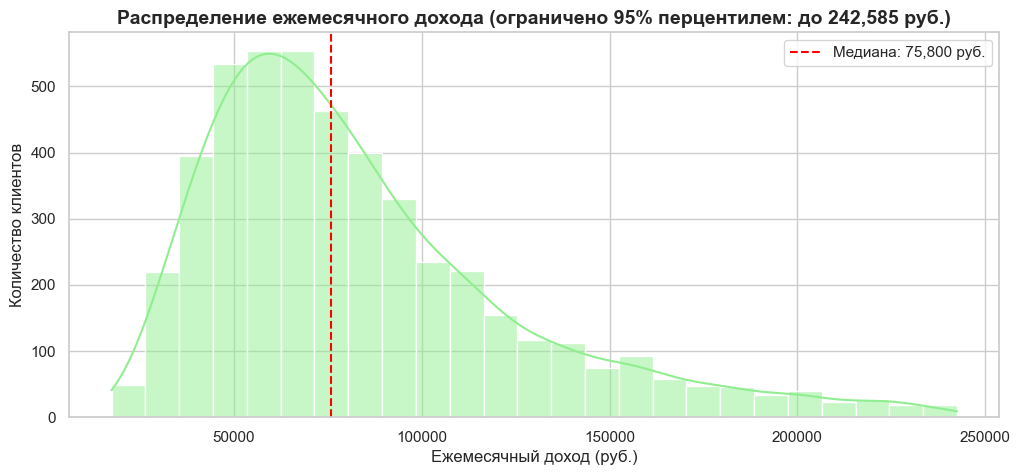

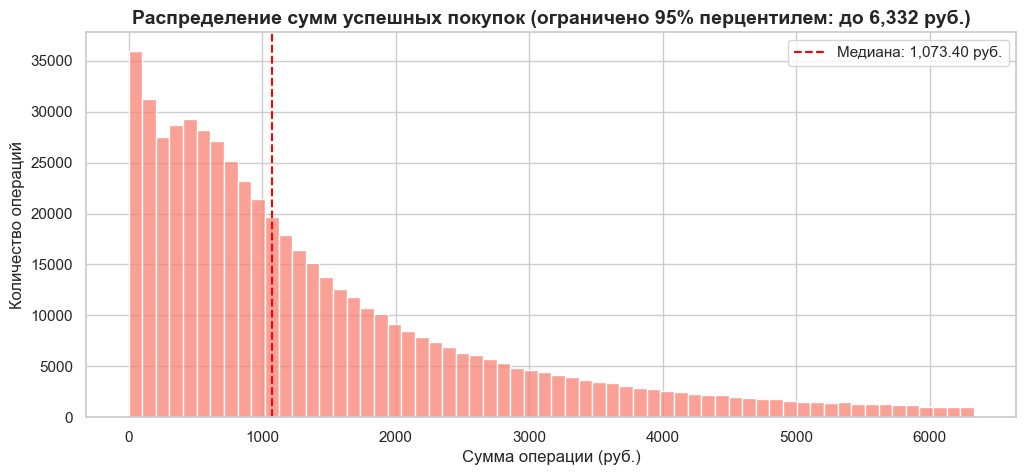

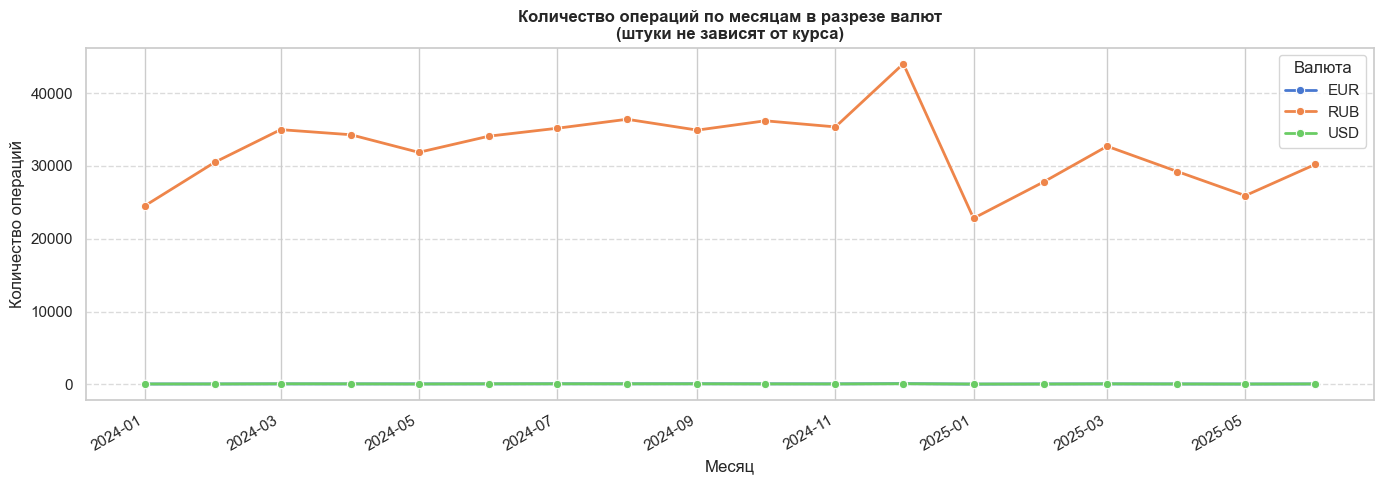

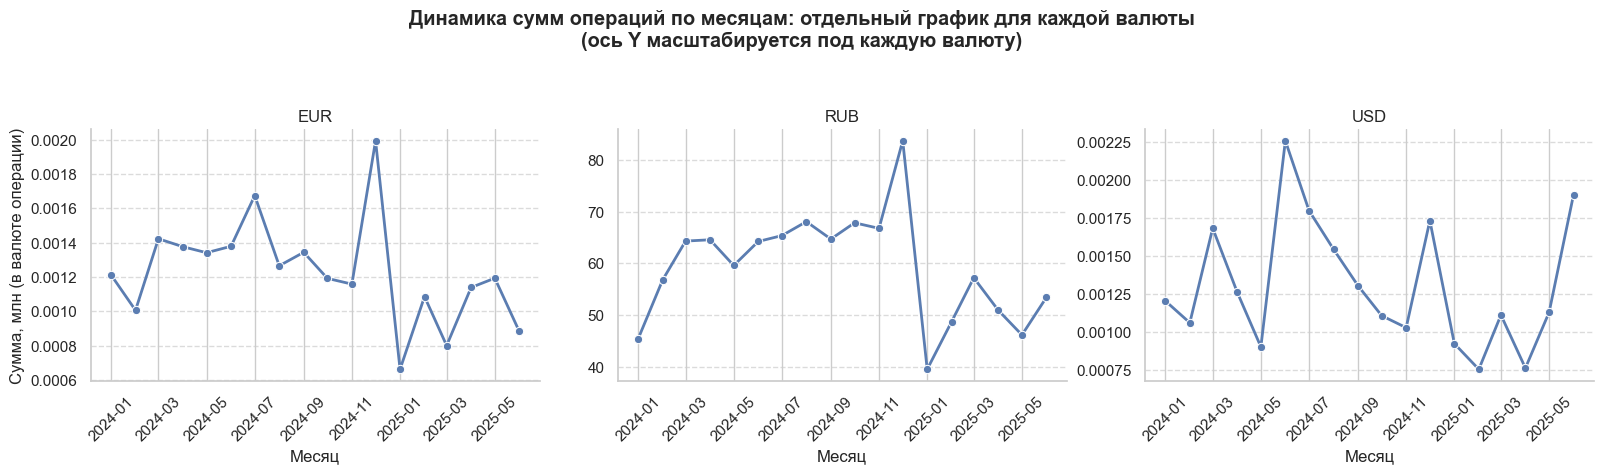


Динамика успешно построена! Обратите внимание на график 3: он наглядно покажет руководству, в каких именно месяцах начался спад активности.


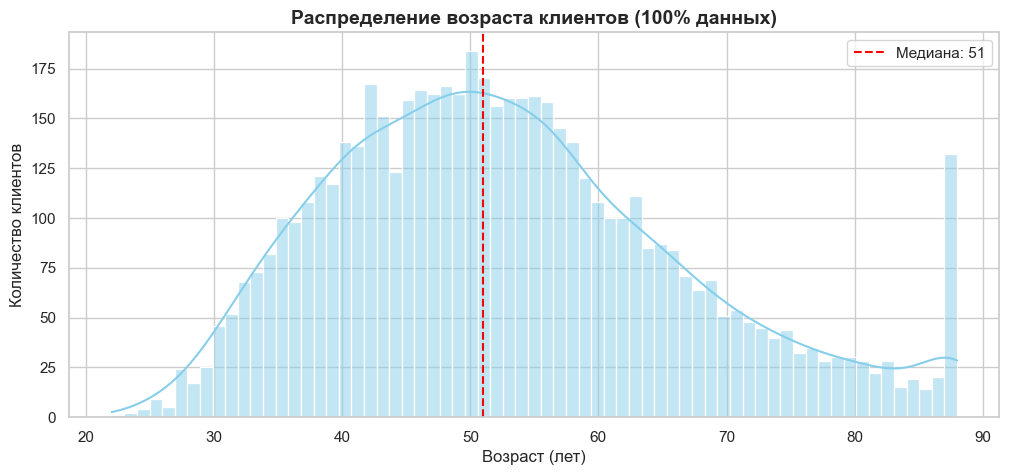

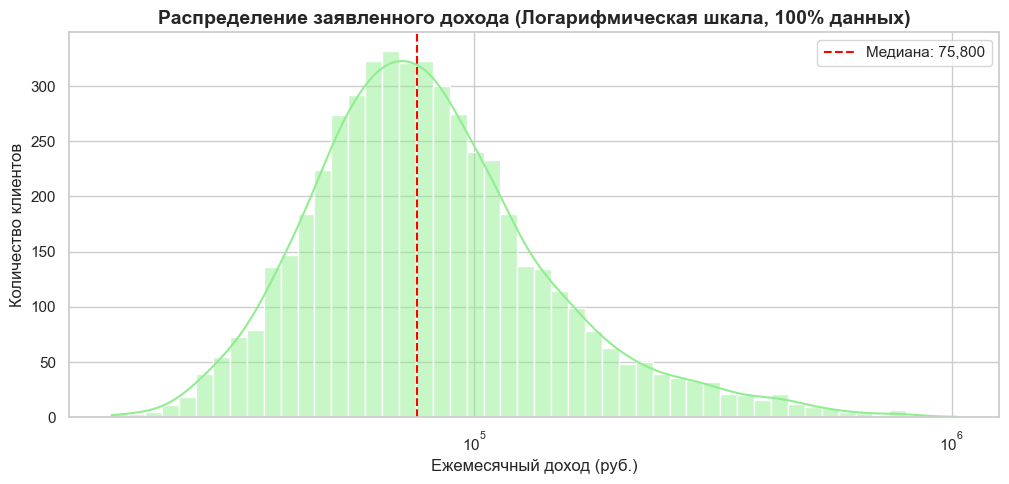

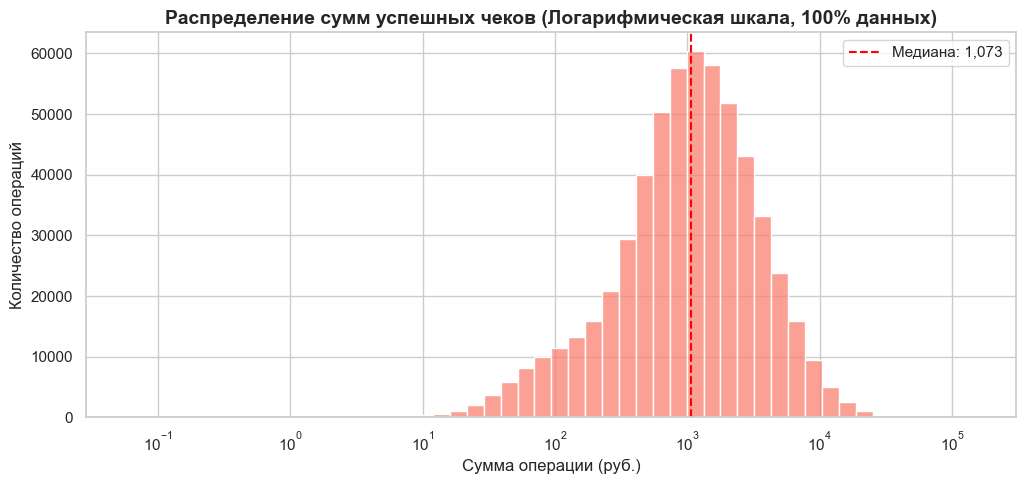

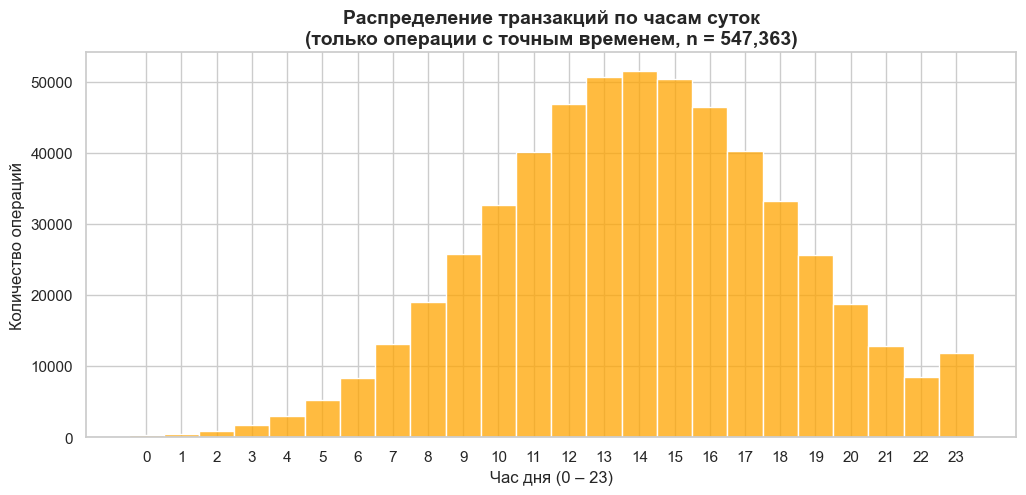


КРАТКАЯ СТАТИСТИКА:
Возраст: медиана = 51 лет, диапазон: 22 - 88
Доход: медиана = 75,800 руб., максимум = 1,026,300 руб.
Чеки: медиана = 1,073 руб., максимум = 147,058 руб.
=== АНАЛИЗ АНОМАЛИЙ: КЛИЕНТЫ 1937 Г.Р. И ТРАНЗАКЦИИ В 00:00 ===
Количество клиентов с годом рождения 1937: 82 из 5626 (1.46%)


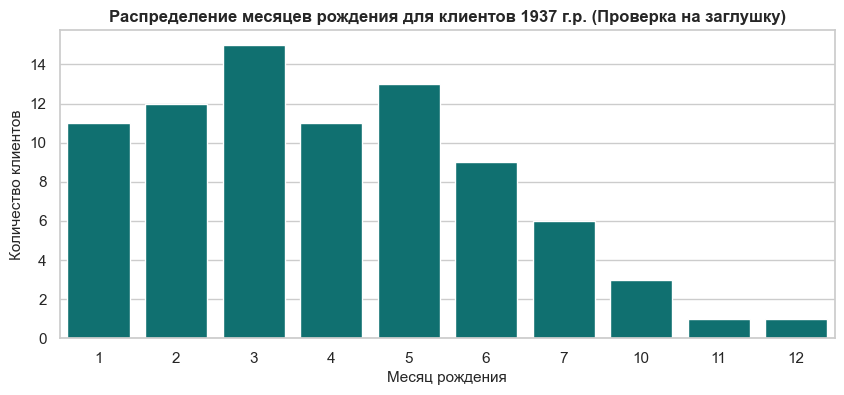

Всего транзакций в очищенной базе: 594,950
  • с точным временем:           547,363  (92.0%)
  • только дата (время неизв.):  47,587  (8.0%)


In [72]:
print("=" * 80)
print("=== 5.1. РАСПРЕДЕЛЕНИЯ КОЛИЧЕСТВЕННЫХ ПРИЗНАКОВ ===")
print("=" * 80)

sns.set_theme(style="whitegrid", palette="muted")

# 1. Подготовка данных
df_clients['age'] = (pd.to_datetime('2025-06-30') - df_clients['birth_date']).dt.days // 365.25
ages = df_clients['age'].dropna()
# Извлекаем час совершения транзакции (от 0 до 23)
txn_hours = df_txn_clean.loc[df_txn_clean['has_time'], 'txn_datetime'].dt.hour.dropna()

print("=" * 80)
print("=== 5.1. РАСПРЕДЕЛЕНИЯ ДО 95-ГО ПЕРЦЕНТИЛЯ И ДИНАМИКА ПО ВРЕМЕНИ ===")
print("=" * 80)


incomes = df_clients['monthly_income'].dropna()
amounts = df_txn_clean[(df_txn_clean['amount'] > 0) & (df_txn_clean['status'] != 'отклонено')]['amount']

# Границы 95-го перцентиля
inc_95 = incomes.quantile(0.95)
amt_95 = amounts.quantile(0.95)

incomes_95_data = incomes[incomes <= inc_95]
amounts_95_data = amounts[amounts <= amt_95]

# =======================================================
# ГРАФИК 1: ДОХОДЫ (до 95% квантиля)
# =======================================================
plt.figure(figsize=(12, 5))
sns.histplot(incomes_95_data, bins=25, kde=True, color='lightgreen')
plt.title(f'Распределение ежемесячного дохода (ограничено 95% перцентилем: до {inc_95:,.0f} руб.)', fontsize=14, fontweight='bold')
plt.xlabel('Ежемесячный доход (руб.)', fontsize=12)
plt.ylabel('Количество клиентов', fontsize=12)
plt.axvline(incomes.median(), color='red', linestyle='--', label=f'Медиана: {incomes.median():,.0f} руб.')
plt.legend()
plt.show()

# =======================================================
# ГРАФИК 2: СУММЫ ЧЕКОВ (до 95% квантиля)
# =======================================================
plt.figure(figsize=(12, 5))
sns.histplot(amounts_95_data, bins=62, kde=False, color='salmon')
plt.title(f'Распределение сумм успешных покупок (ограничено 95% перцентилем: до {amt_95:,.0f} руб.)', fontsize=14, fontweight='bold')
plt.xlabel('Сумма операции (руб.)', fontsize=12)
plt.ylabel('Количество операций', fontsize=12)
plt.axvline(amounts.median(), color='red', linestyle='--', label=f'Медиана: {amounts.median():,.2f} руб.')
plt.legend()
plt.show()

# =======================================================
# ГРАФИК 3: ДИНАМИКА ТРАНЗАКЦИЙ ПО МЕСЯЦАМ (Январь 2024 – Июнь 2025)
# =======================================================
# Создаем колонку с периодом "Год-Месяц"
# =============================================================================
# ДИНАМИКА В РАЗРЕЗЕ ВАЛЮТ
# =============================================================================
# Внимание: суммировать RUB, USD и EUR в одну кучу нельзя. 
# Поэтому строим:
# 1. Количество операций (не зависит от курса) — 3 линии на одном графике.
# 2. Суммы — отдельный подграфик для каждой валюты (разный масштаб).
# =============================================================================

df_dyn_curr = df_txn_clean[df_txn_clean['status'] != 'отклонено'].copy()
df_dyn_curr['year_month_dt'] = df_dyn_curr['txn_datetime'].dt.to_period('M').dt.to_timestamp()

# --- 1. Количество операций по валютам ---
monthly_curr_cnt = df_dyn_curr.groupby(['year_month_dt', 'currency']).size().reset_index(name='txn_count')

fig, ax = plt.subplots(figsize=(14, 5))
sns.lineplot(data=monthly_curr_cnt, x='year_month_dt', y='txn_count', 
             hue='currency', marker='o', linewidth=2, ax=ax)
ax.set_title('Количество операций по месяцам в разрезе валют\n(штуки не зависят от курса)', fontweight='bold')
ax.set_xlabel('Месяц')
ax.set_ylabel('Количество операций')
ax.grid(axis='y', linestyle='--', alpha=0.7)
ax.legend(title='Валюта')
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

# --- 2. Суммы операций по валютам (отдельные панели для масштаба) ---
monthly_curr_sum = df_dyn_curr.groupby(['year_month_dt', 'currency']).agg(
    total_amount=('amount', 'sum')
).reset_index()
monthly_curr_sum['total_amount_mln'] = monthly_curr_sum['total_amount'] / 1e6

# Строим сетку из 3 графиков (по одному на валюту)
g = sns.FacetGrid(monthly_curr_sum, col='currency', col_wrap=3, height=4.5, aspect=1.2, sharey=False)
g.map(sns.lineplot, 'year_month_dt', 'total_amount_mln', marker='o', color='#5b7db1', linewidth=2)
g.set_axis_labels('Месяц', 'Сумма, млн (в валюте операции)')
g.set_titles(col_template='{col_name}')
g.fig.suptitle('Динамика сумм операций по месяцам: отдельный график для каждой валюты\n(ось Y масштабируется под каждую валюту)', 
               fontweight='bold', y=1.05)
for ax in g.axes.flatten():
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

print("\nДинамика успешно построена! Обратите внимание на график 3: он наглядно покажет руководству, в каких именно месяцах начался спад активности.")

# =======================================================
# ГРАФИК 1: ВОЗРАСТ (Обычная шкала)
# =======================================================
plt.figure(figsize=(12, 5))
sns.histplot(ages, bins=67, kde=True, color='skyblue')
plt.title('Распределение возраста клиентов (100% данных)', fontsize=14, fontweight='bold')
plt.xlabel('Возраст (лет)', fontsize=12)
plt.ylabel('Количество клиентов', fontsize=12)
plt.axvline(ages.median(), color='red', linestyle='--', label=f'Медиана: {ages.median():.0f}')
plt.legend()
plt.show()

# =======================================================
# ГРАФИК 2: ДОХОД (Логарифмическая шкала оси X)
# =======================================================
plt.figure(figsize=(12, 5))
# log_scale=True позволяет уместить и 20 тыс., и 1 млн на одном красивом графике
sns.histplot(incomes, bins=50, kde=True, color='lightgreen', log_scale=True)
plt.title('Распределение заявленного дохода (Логарифмическая шкала, 100% данных)', fontsize=14, fontweight='bold')
plt.xlabel('Ежемесячный доход (руб.)', fontsize=12)
plt.ylabel('Количество клиентов', fontsize=12)
plt.axvline(incomes.median(), color='red', linestyle='--', label=f'Медиана: {incomes.median():,.0f}')
plt.legend()
plt.show()

# =======================================================
# ГРАФИК 3: СУММЫ ТРАНЗАКЦИЙ (Логарифмическая шкала оси X)
# =======================================================
plt.figure(figsize=(12, 5))
sns.histplot(amounts, bins=50, kde=False, color='salmon', log_scale=True)
plt.title('Распределение сумм успешных чеков (Логарифмическая шкала, 100% данных)', fontsize=14, fontweight='bold')
plt.xlabel('Сумма операции (руб.)', fontsize=12)
plt.ylabel('Количество операций', fontsize=12)
plt.axvline(amounts.median(), color='red', linestyle='--', label=f'Медиана: {amounts.median():,.0f}')
plt.legend()
plt.show()

# =======================================================
# ГРАФИК 4: ВРЕМЯ ТРАНЗАКЦИЙ (Часы)
# =======================================================
plt.figure(figsize=(12, 5))
sns.histplot(txn_hours, bins=24, color='orange', discrete=True)
plt.title(f'Распределение транзакций по часам суток\n'
          f'(только операции с точным временем, n = {len(txn_hours):,})',
          fontsize=14, fontweight='bold')
plt.xlabel('Час дня (0 – 23)', fontsize=12)
plt.ylabel('Количество операций', fontsize=12)
plt.xticks(range(0, 24))
plt.show()

print("\nКРАТКАЯ СТАТИСТИКА:")
print(f"Возраст: медиана = {ages.median():.0f} лет, диапазон: {ages.min():.0f} - {ages.max():.0f}")
print(f"Доход: медиана = {incomes.median():,.0f} руб., максимум = {incomes.max():,.0f} руб.")
print(f"Чеки: медиана = {amounts.median():,.0f} руб., максимум = {amounts.max():,.0f} руб.")

print("=" * 80)
print("=== АНАЛИЗ АНОМАЛИЙ: КЛИЕНТЫ 1937 Г.Р. И ТРАНЗАКЦИИ В 00:00 ===")
print("=" * 80)

# =========================================================================
# 1. АНАЛИЗ КЛИЕНТОВ 1937 ГОДА РОЖДЕНИЯ (АРТЕФАКТ ВОЗРАСТА)
# =========================================================================
# Выделяем клиентов, родившихся в 1937 году (или чей возраст около 88 лет)
df_clients['birth_year'] = df_clients['birth_date'].dt.year
clients_1937 = df_clients[df_clients['birth_year'] == 1937].copy()

print(f"Количество клиентов с годом рождения 1937: {len(clients_1937)} из {len(df_clients)} ({len(clients_1937)/len(df_clients):.2%})")

# Строим график распределения по месяцам для тех, кто родился в 1937
clients_1937['birth_month'] = df_clients['birth_date'].dt.month
plt.figure(figsize=(10, 4))
sns.countplot(x='birth_month', data=clients_1937, color='teal')
plt.title('Распределение месяцев рождения для клиентов 1937 г.р. (Проверка на заглушку)', fontsize=12, fontweight='bold')
plt.xlabel('Месяц рождения', fontsize=11)
plt.ylabel('Количество клиентов', fontsize=11)
plt.show()


# =========================================================================
# 2. АНАЛИЗ ВРЕМЕНИ ТРАНЗАКЦИЙ И НУЛЕВЫХ ЧАСОВ (00:00)
# =========================================================================
# Выделяем часы
n_total   = len(df_txn_clean)
n_with_t  = int(df_txn_clean['has_time'].sum())
n_no_time = n_total - n_with_t

print(f"Всего транзакций в очищенной базе: {n_total:,}")
print(f"  • с точным временем:           {n_with_t:,}  ({n_with_t/n_total:.1%})")
print(f"  • только дата (время неизв.):  {n_no_time:,}  ({n_no_time/n_total:.1%})")


### 5.2. Частотные характеристики категориальных признаков

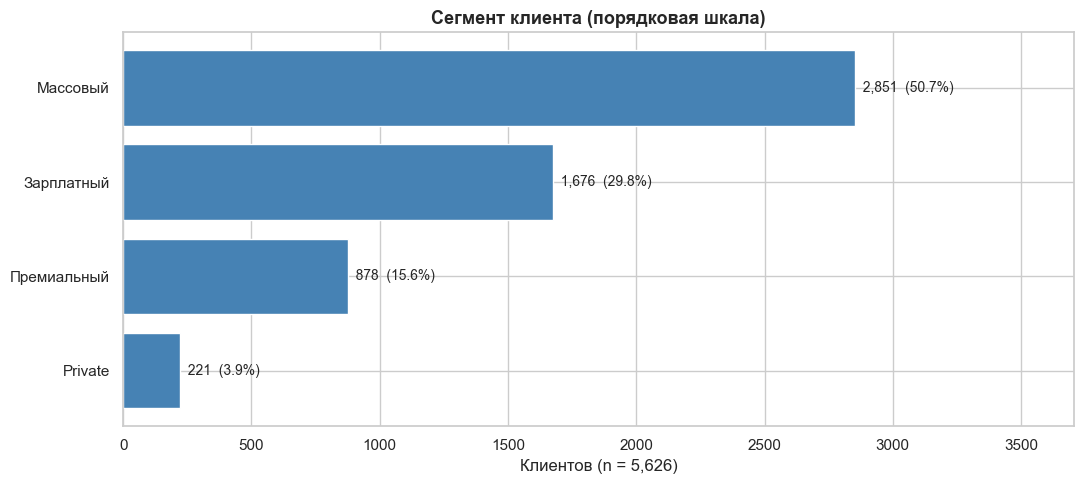

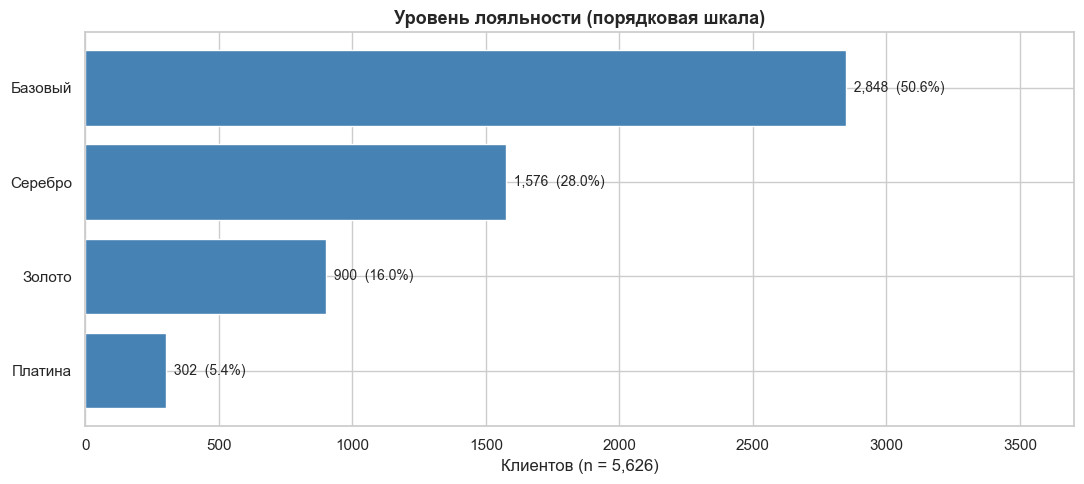

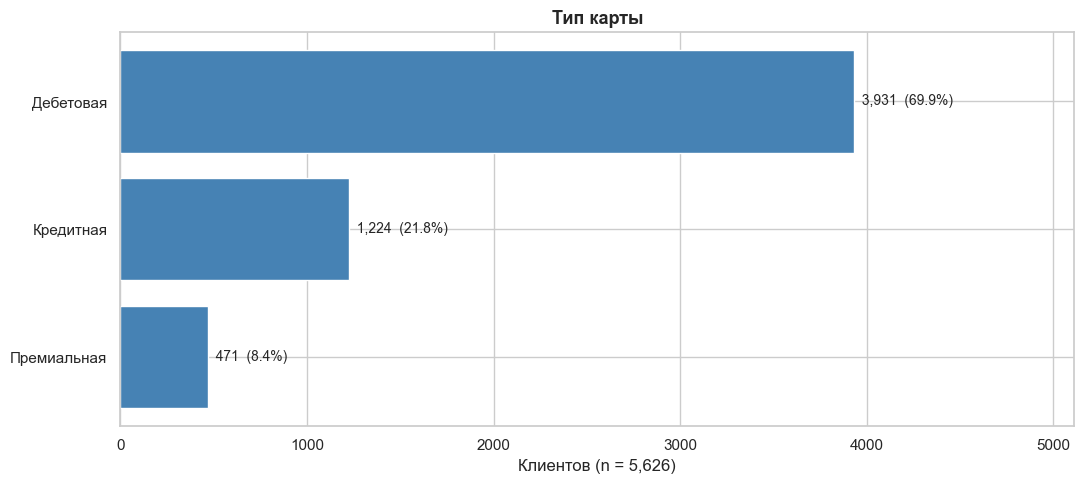

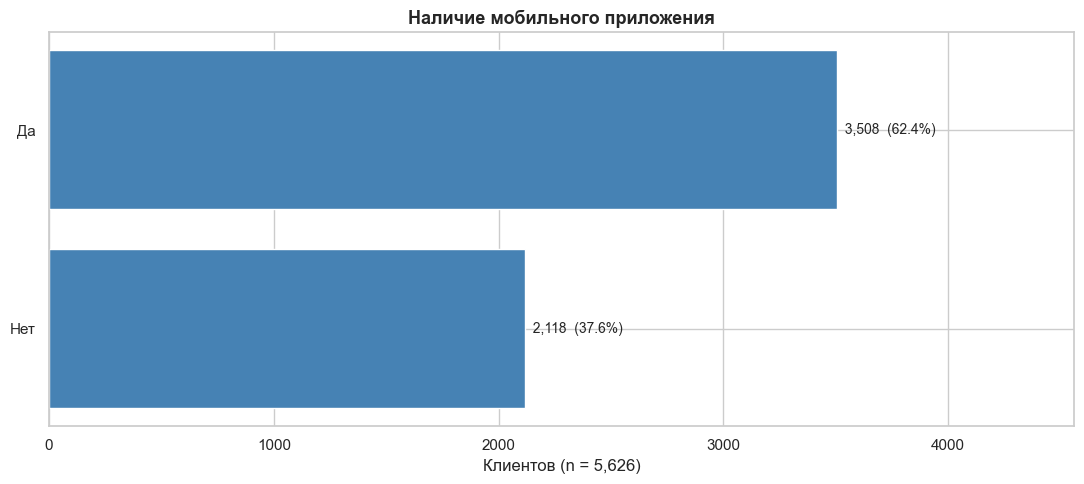

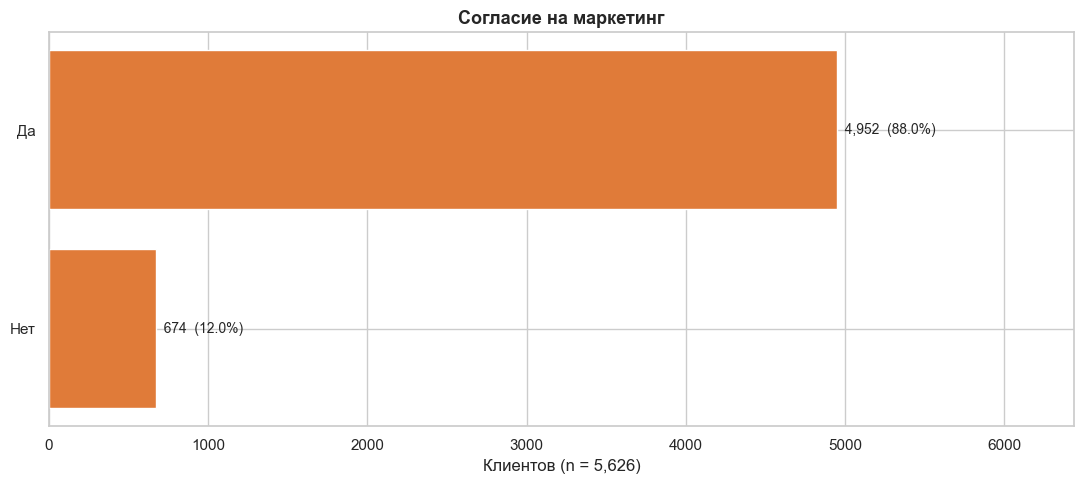

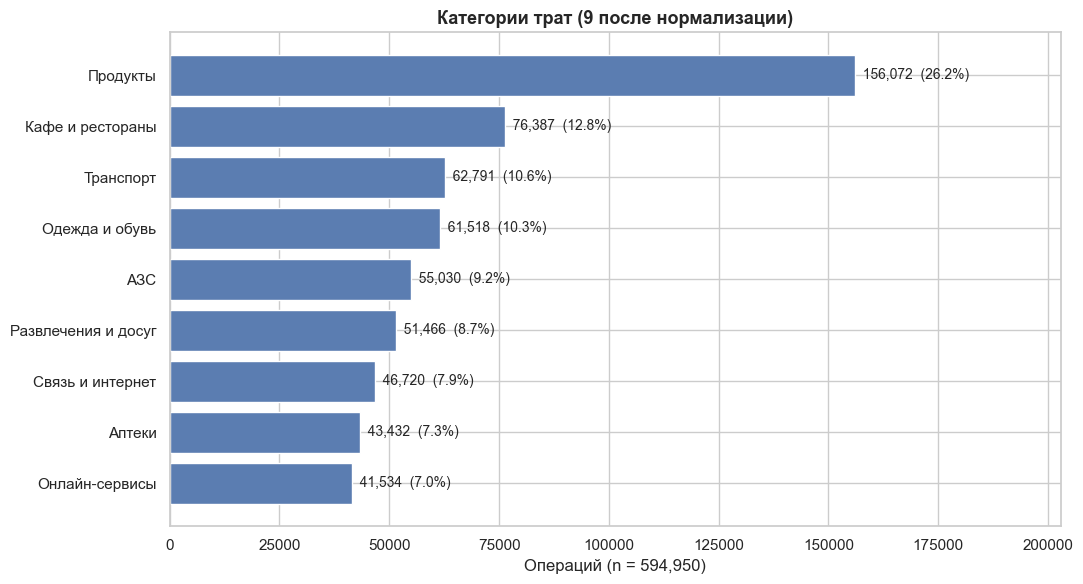

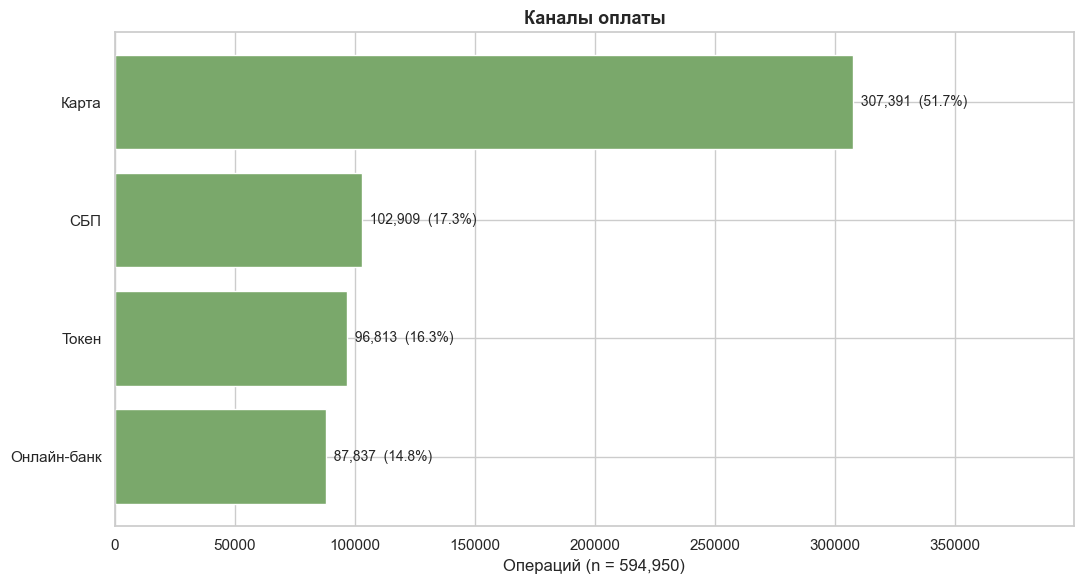

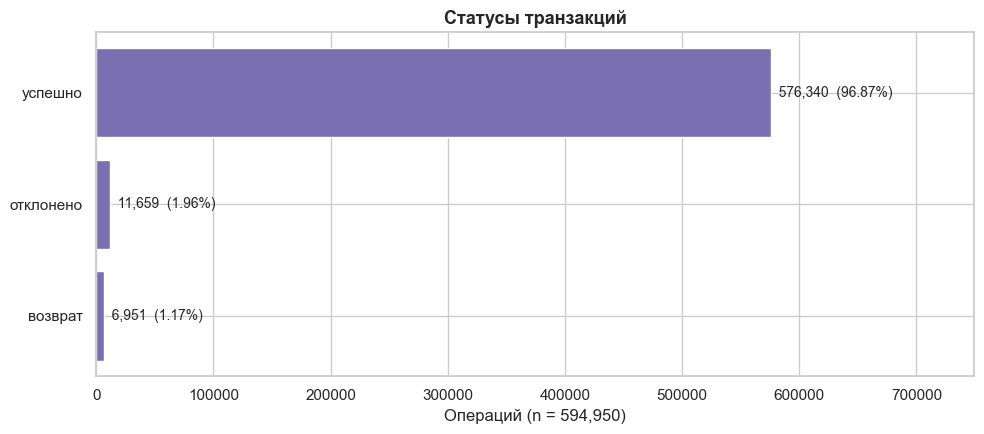

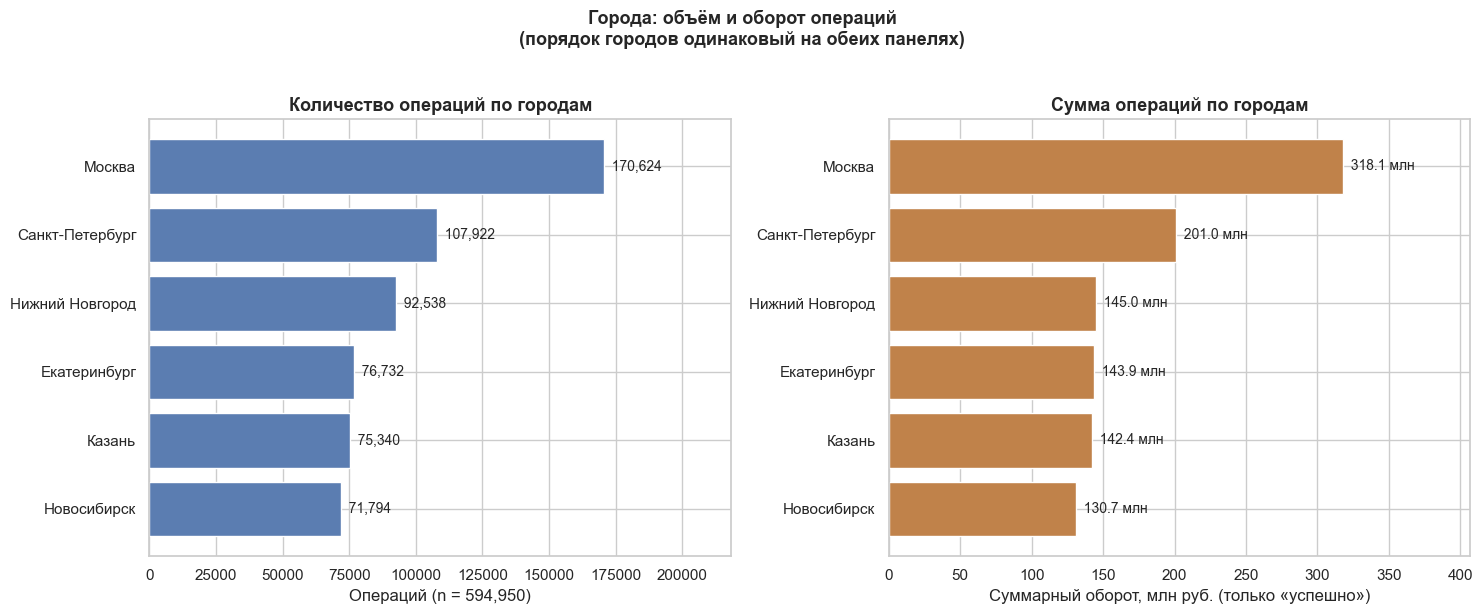

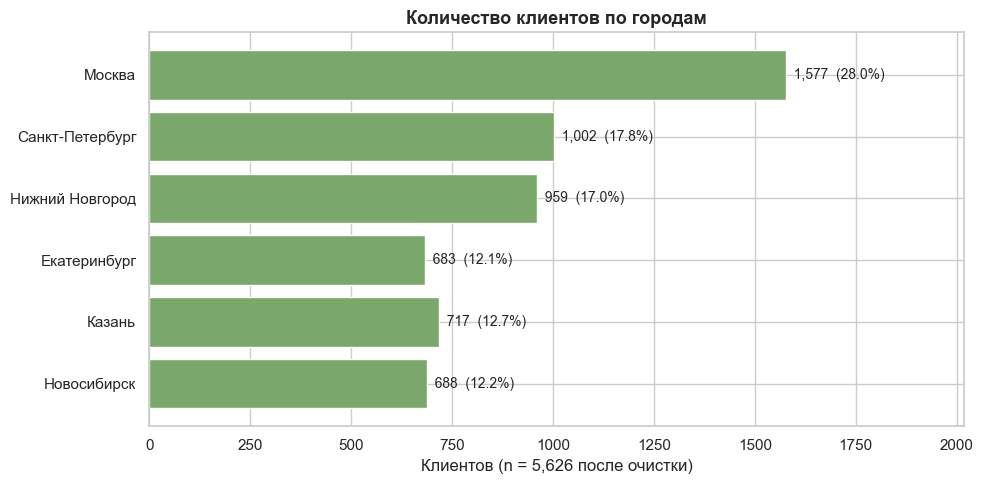

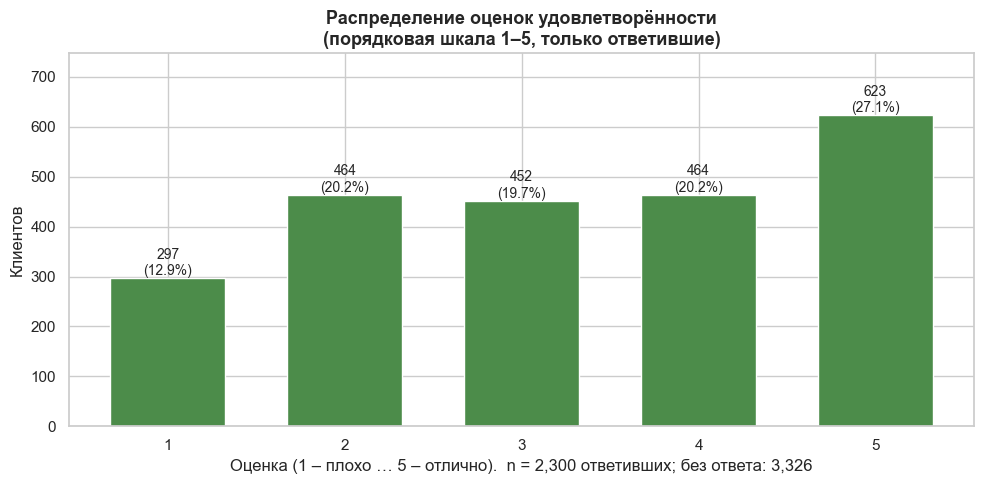

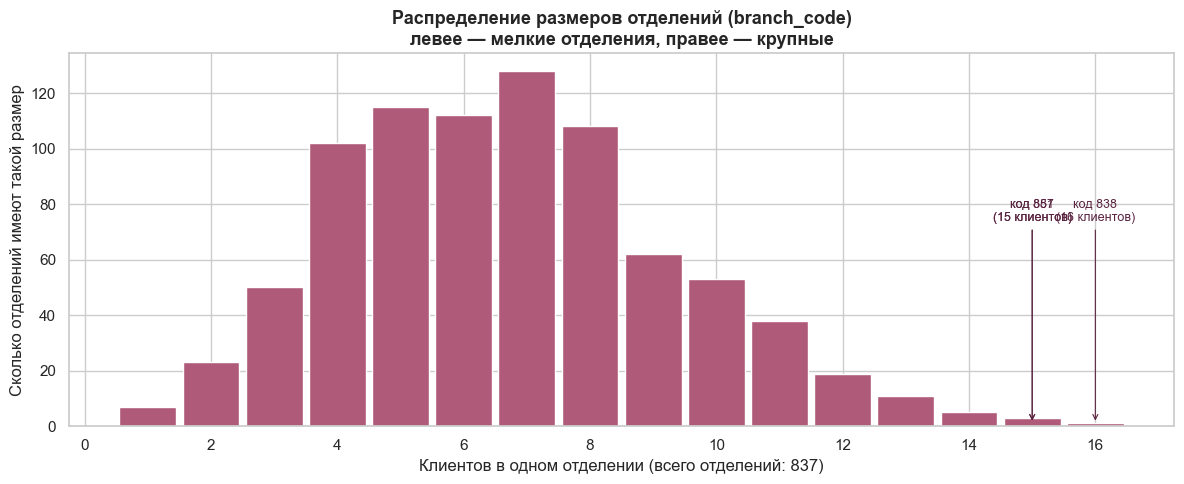

[branch_code] Всего отделений: 837 | клиентов: 5,626 | медиана клиентов на отделение: 7 | максимум: 16 (код 838)


In [73]:
SEGMENT_ORDER = ['Массовый', 'Зарплатный', 'Премиальный', 'Private']
LOYALTY_ORDER = ['Базовый', 'Серебро', 'Золото', 'Платина']

def _barh_cat(ax, s, title, color='steelblue', order=None):
    """Горизонтальные бары частот. n_valid в подписи оси X — знаменатель явный."""
    n_valid = s.shape[0]
    vc = s.dropna().value_counts()
    if order is not None:
        vc = vc.reindex(order, fill_value=0)
    y = np.arange(len(vc))
    ax.barh(y, vc.values, color=color)
    ax.set_yticks(y); ax.set_yticklabels(vc.index); ax.invert_yaxis()
    ax.set_xlabel(f'Клиентов (n = {n_valid:,})')
    ax.set_title(title, fontweight='bold', fontsize=13)
    ax.set_xlim(0, vc.max() * 1.30)
    for i, v in enumerate(vc.values):
        ax.text(v, i, f'  {v:,}  ({v/n_valid*100:.1f}%)', va='center', fontsize=10)


# -----------------------------------------------------------------------------
# КЛИЕНТЫ. Каждый признак — отдельная фигура
# -----------------------------------------------------------------------------
client_specs = [
    ('segment',          SEGMENT_ORDER, 'Сегмент клиента (порядковая шкала)'),
    ('loyalty_tier',     LOYALTY_ORDER, 'Уровень лояльности (порядковая шкала)'),
    ('card_type',        None,          'Тип карты'),
    ('has_mobile_app',   None,          'Наличие мобильного приложения'),
    ('marketing_opt_in', None,          'Согласие на маркетинг'),
]

for col, order, title in client_specs:
    fig, ax = plt.subplots(figsize=(11, 5))
    color = '#e07b39' if col == 'marketing_opt_in' else 'steelblue'
    _barh_cat(ax, df_clients[col], title, color=color, order=order)
    plt.tight_layout()
    plt.show()


# -----------------------------------------------------------------------------
# ТРАНЗАКЦИИ. Категории и каналы — по отдельной фигуре
# -----------------------------------------------------------------------------
for col, title, color in [
    ('category', 'Категории трат (9 после нормализации)', '#5b7db1'),
    ('channel',  'Каналы оплаты',                         '#7aa86b'),
]:
    n_valid = df_txn_clean[col].dropna().shape[0]
    vc = df_txn_clean[col].dropna().value_counts()

    fig, ax = plt.subplots(figsize=(11, 6))
    y = np.arange(len(vc))
    ax.barh(y, vc.values, color=color)
    ax.set_yticks(y); ax.set_yticklabels(vc.index); ax.invert_yaxis()
    ax.set_xlabel(f'Операций (n = {n_valid:,})')
    ax.set_title(title, fontweight='bold', fontsize=13)
    ax.set_xlim(0, vc.max() * 1.30)
    for i, v in enumerate(vc.values):
        ax.text(v, i, f'  {v:,}  ({v/n_valid*100:.1f}%)', va='center', fontsize=10)
    plt.tight_layout()
    plt.show()


# =============================================================================
# 5.2 (продолжение). Статусы, города, оценки, отделения
# =============================================================================
# Используем уже готовые очищенные df_clients и df_txn_clean — повторно
# ничего не чистим. Единственный merge — чтобы приклеить город клиента
# к операциям (транзакции сами по себе город не знают).
# =============================================================================

# -----------------------------------------------------------------------------
# РИСУНОК 1. Статусы операций
# -----------------------------------------------------------------------------
n_valid = df_txn_clean['status'].dropna().shape[0]
vc = df_txn_clean['status'].dropna().value_counts()

fig, ax = plt.subplots(figsize=(10, 4.5))
y = np.arange(len(vc))
ax.barh(y, vc.values, color='#7a6fb0')
ax.set_yticks(y); ax.set_yticklabels(vc.index); ax.invert_yaxis()
ax.set_xlabel(f'Операций (n = {n_valid:,})')
ax.set_title('Статусы транзакций', fontweight='bold', fontsize=13)
ax.set_xlim(0, vc.max() * 1.30)
for i, v in enumerate(vc.values):
    ax.text(v, i, f'  {v:,}  ({v/n_valid*100:.2f}%)', va='center', fontsize=10)
plt.tight_layout()
plt.show()


# -----------------------------------------------------------------------------
# Приклеиваем город клиента к операциям (один merge на все городские графики)
# -----------------------------------------------------------------------------
txn_city = df_txn_clean.merge(
    df_clients[['client_id', 'city']], on='client_id', how='left'
)

# Порядок городов задаём ОДИН раз, чтобы на двух панелях был одинаковый:
# по убыванию числа операций
city_order = txn_city['city'].dropna().value_counts().index.tolist()


# -----------------------------------------------------------------------------
# РИСУНОК 2. Города: 2 панели рядом — количество операций и сумма
# -----------------------------------------------------------------------------
# Сумму считаем только по 'успешно' — это оборот. Возвраты уменьшают нетто,
# но их ~1%, поэтому для «объёма покупок» берём успешные.
txn_ok = txn_city[txn_city['status'] == 'успешно']

count_by_city = txn_city['city'].value_counts().reindex(city_order).fillna(0)
sum_by_city   = (txn_ok.groupby('city')['amount'].sum()
                 .reindex(city_order).fillna(0) / 1e6)   # млн руб.

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

y = np.arange(len(city_order)); w = 0.9

axes[0].barh(y, count_by_city.values, color='#5b7db1')
axes[0].set_yticks(y); axes[0].set_yticklabels(city_order); axes[0].invert_yaxis()
axes[0].set_xlabel(f'Операций (n = {int(count_by_city.sum()):,})')
axes[0].set_title('Количество операций по городам', fontweight='bold', fontsize=13)
axes[0].set_xlim(0, count_by_city.max() * 1.28)
for i, v in enumerate(count_by_city.values):
    axes[0].text(v, i, f'  {int(v):,}', va='center', fontsize=10)

axes[1].barh(y, sum_by_city.values, color='#c0824a')
axes[1].set_yticks(y); axes[1].set_yticklabels(city_order); axes[1].invert_yaxis()
axes[1].set_xlabel('Суммарный оборот, млн руб. (только «успешно»)')
axes[1].set_title('Сумма операций по городам', fontweight='bold', fontsize=13)
axes[1].set_xlim(0, sum_by_city.max() * 1.28)
for i, v in enumerate(sum_by_city.values):
    axes[1].text(v, i, f'  {v:,.1f} млн', va='center', fontsize=10)

plt.suptitle('Города: объём и оборот операций\n'
             '(порядок городов одинаковый на обеих панелях)',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


# -----------------------------------------------------------------------------
# РИСУНОК 3. Клиенты по городам (тот же порядок городов)
# -----------------------------------------------------------------------------
clients_by_city = df_clients['city'].value_counts().reindex(city_order).fillna(0)
n_clients_total = int(clients_by_city.sum())

fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(city_order))
ax.barh(y, clients_by_city.values, color='#7aa86b')
ax.set_yticks(y); ax.set_yticklabels(city_order); ax.invert_yaxis()
ax.set_xlabel(f'Клиентов (n = {n_clients_total:,} после очистки)')
ax.set_title('Количество клиентов по городам', fontweight='bold', fontsize=13)
ax.set_xlim(0, clients_by_city.max() * 1.28)
for i, v in enumerate(clients_by_city.values):
    ax.text(v, i, f'  {int(v):,}  ({v/n_clients_total*100:.1f}%)',
            va='center', fontsize=10)
plt.tight_layout()
plt.show()


# -----------------------------------------------------------------------------
# РИСУНОК 4. Оценки удовлетворённости (satisfaction_score)
# -----------------------------------------------------------------------------
# Порядковая шкала 1..5 — держим ЕСТЕСТВЕННЫЙ порядок, не сортируем по частоте.
# NaN (не проходили опрос) не показываем как категорию, но указываем в подписи,
# сколько их (важно: заполнение медианой дало бы фиктивный «нейтральный» балл).
sat_series = df_clients['satisfaction_score'].dropna().astype(int)
n_sat = len(sat_series)
n_sat_na = df_clients['satisfaction_score'].isna().sum()

sat_counts = sat_series.value_counts().reindex([1, 2, 3, 4, 5], fill_value=0)

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(1, 6)
bars = ax.bar(x, sat_counts.values, color='#4c8c4a', width=0.65)
ax.set_xticks(x)
ax.set_xlabel(f'Оценка (1 – плохо … 5 – отлично).  n = {n_sat:,} ответивших; '
              f'без ответа: {n_sat_na:,}')
ax.set_ylabel('Клиентов')
ax.set_title('Распределение оценок удовлетворённости\n'
             '(порядковая шкала 1–5, только ответившие)',
             fontweight='bold', fontsize=13)
ax.set_ylim(0, sat_counts.max() * 1.20)
for xi, v in zip(x, sat_counts.values):
    ax.text(xi, v, f'{v:,}\n({v/n_sat*100:.1f}%)',
            ha='center', va='bottom', fontsize=10)
plt.tight_layout()
plt.show()


# -----------------------------------------------------------------------------
# РИСУНОК 5. Коды отделений (branch_code) — распределение размеров
# -----------------------------------------------------------------------------
# branch_code — это категориальный код отделения (3-значный номер).
# Уникальных значений может быть 100+, поэтому сам бар по отделениям
# нечитаем. Смотрим на РАСПРЕДЕЛЕНИЕ РАЗМЕРОВ: сколько отделений имеют
# ровно 1 клиента, 2 клиента, 3 и т.д. Это сразу показывает, есть ли
# «аномально крупные» / «аномально мелкие» отделения в базе.
n_branches = df_clients['branch_code'].nunique()
branch_sizes = df_clients['branch_code'].value_counts()      # Series: code -> N клиентов
size_dist    = branch_sizes.value_counts().sort_index()      # Series: размер -> сколько отделений

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(size_dist.index, size_dist.values, color='#b05a7a', width=0.9)
ax.set_xlabel(f'Клиентов в одном отделении (всего отделений: {n_branches:,})')
ax.set_ylabel('Сколько отделений имеют такой размер')
ax.set_title('Распределение размеров отделений (branch_code)\n'
             'левее — мелкие отделения, правее — крупные',
             fontweight='bold', fontsize=13)

# подпишем топ-3 самых крупных отделений прямо на графике
top3 = branch_sizes.head(3)
for code, size in top3.items():
    ax.annotate(f'код {code}\n({size} клиентов)',
                xy=(size, 1), xytext=(size, ax.get_ylim()[1] * 0.55),
                ha='center', fontsize=9, color='#5a2440',
                arrowprops=dict(arrowstyle='->', color='#5a2440', lw=0.8))
plt.tight_layout()
plt.show()

print(f"[branch_code] Всего отделений: {n_branches:,} | "
      f"клиентов: {len(df_clients):,} | "
      f"медиана клиентов на отделение: {branch_sizes.median():.0f} | "
      f"максимум: {branch_sizes.max()} (код {branch_sizes.idxmax()})")

### 5.3. Динамика по месяцам

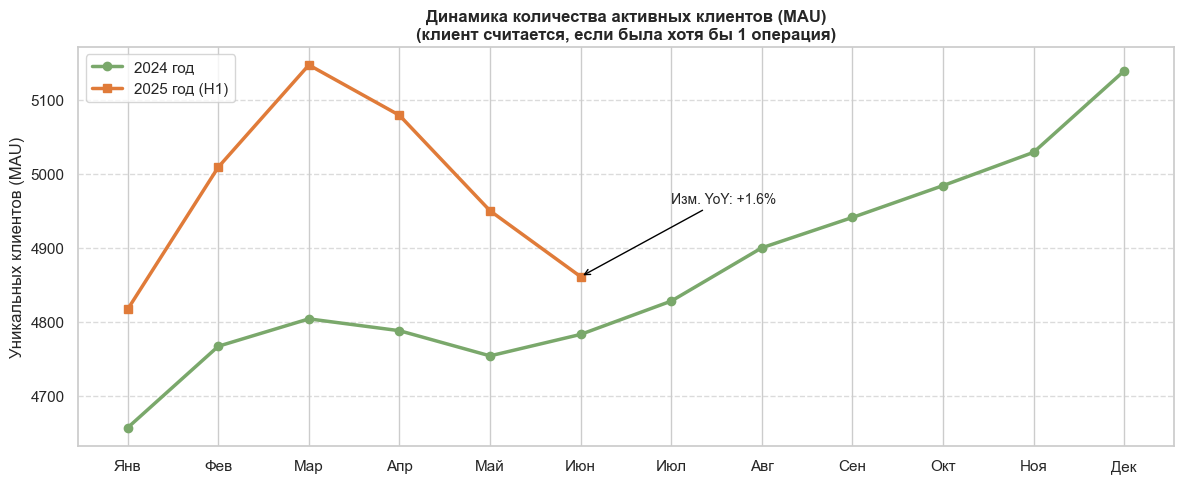

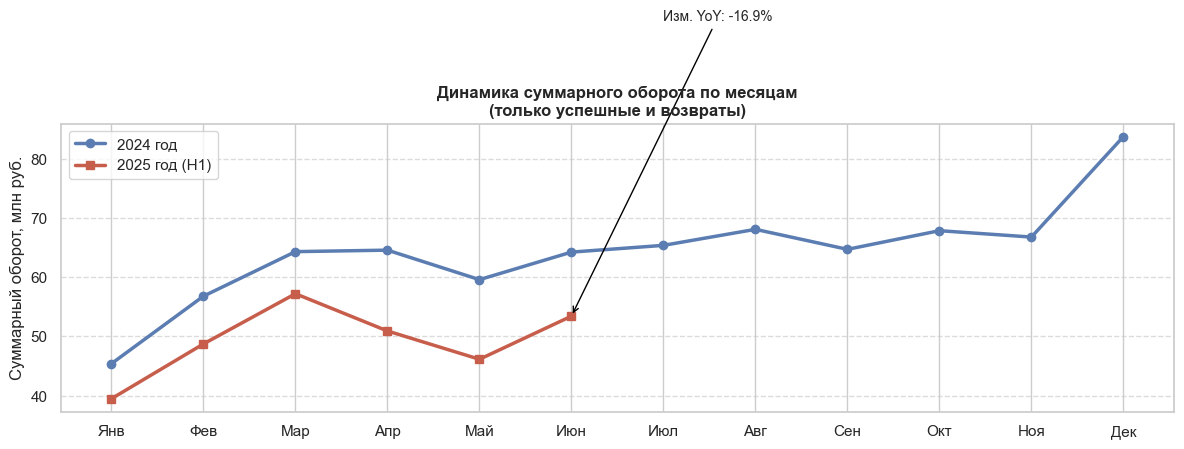

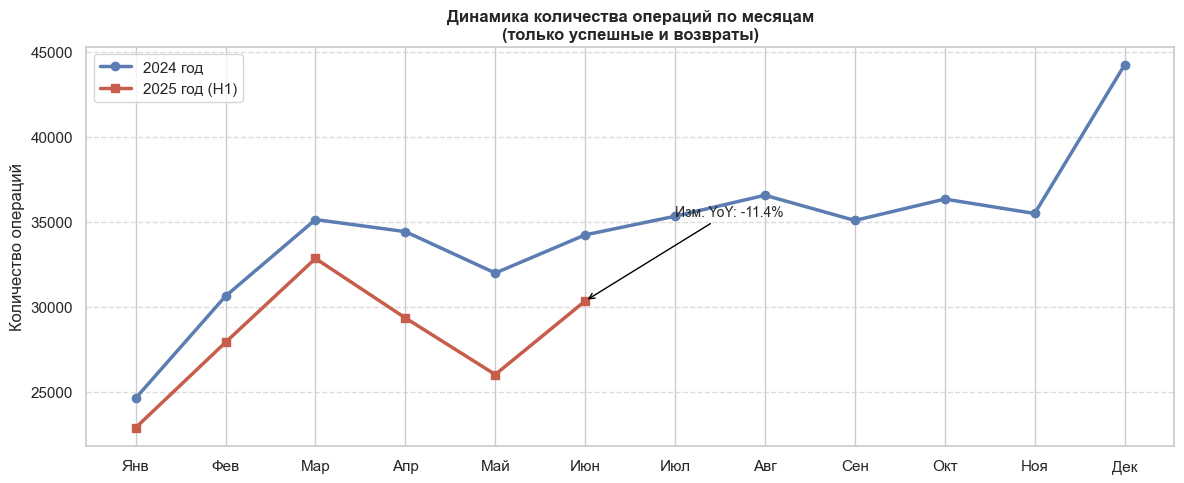

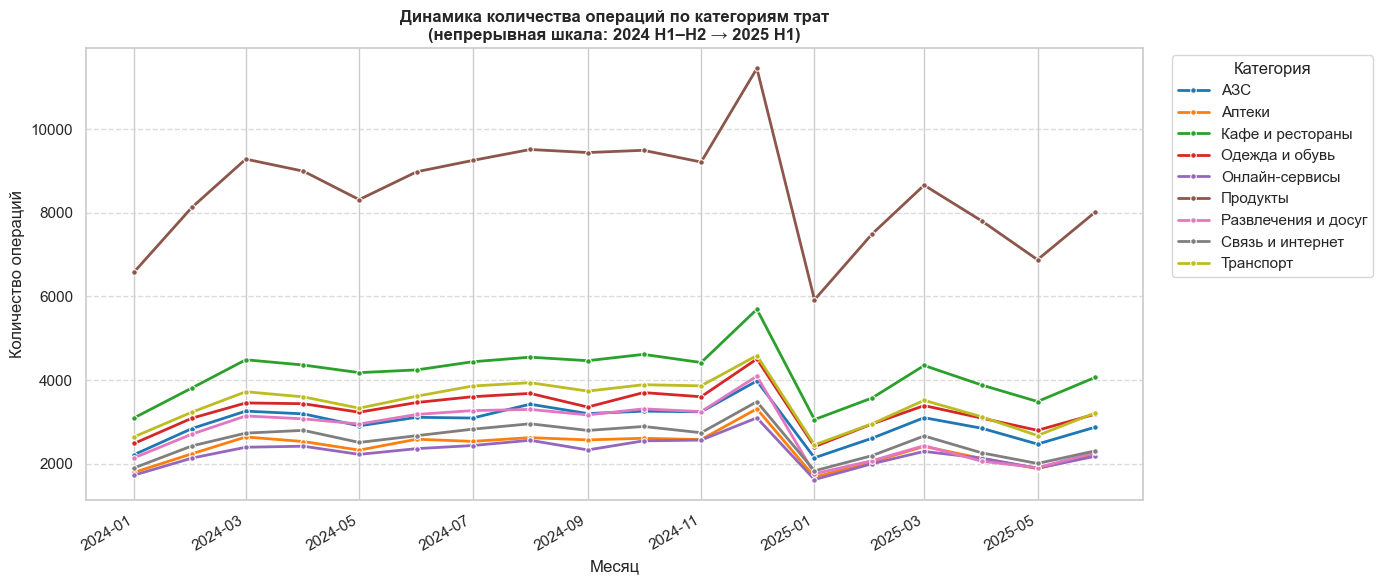

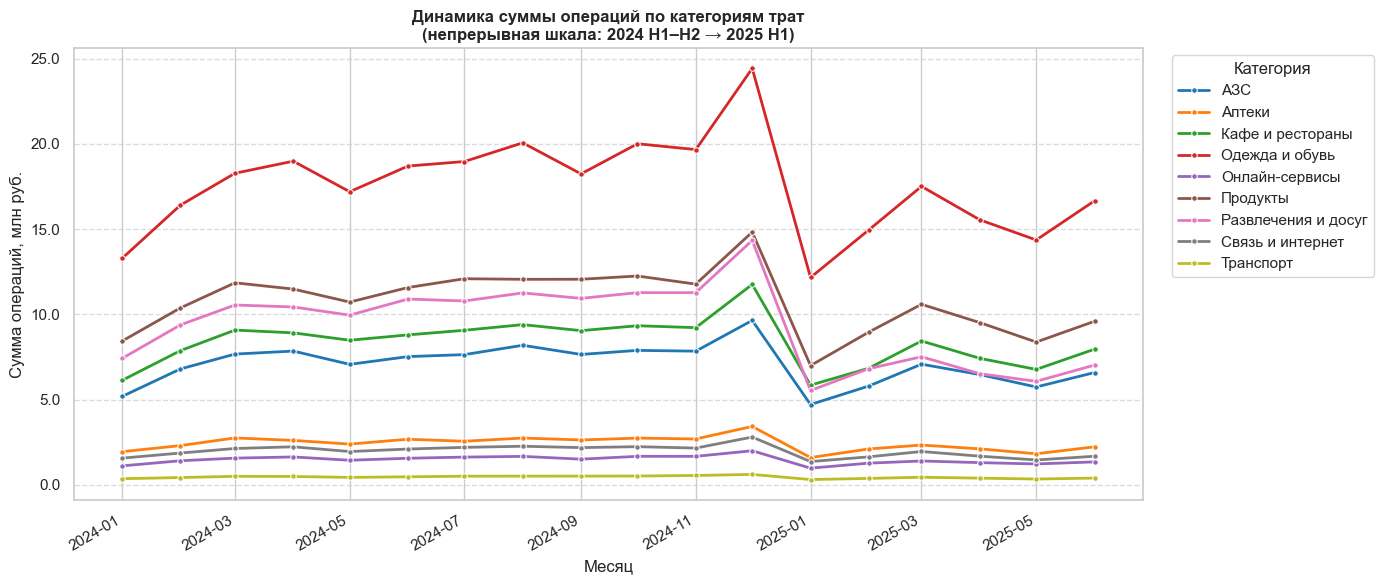

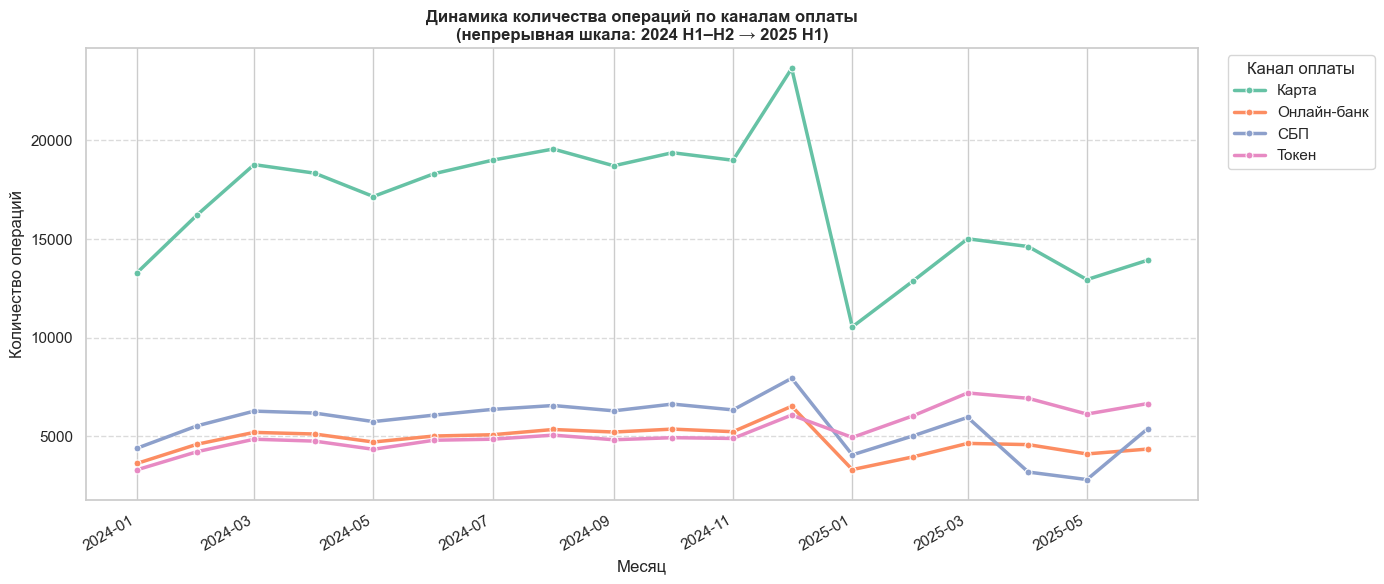

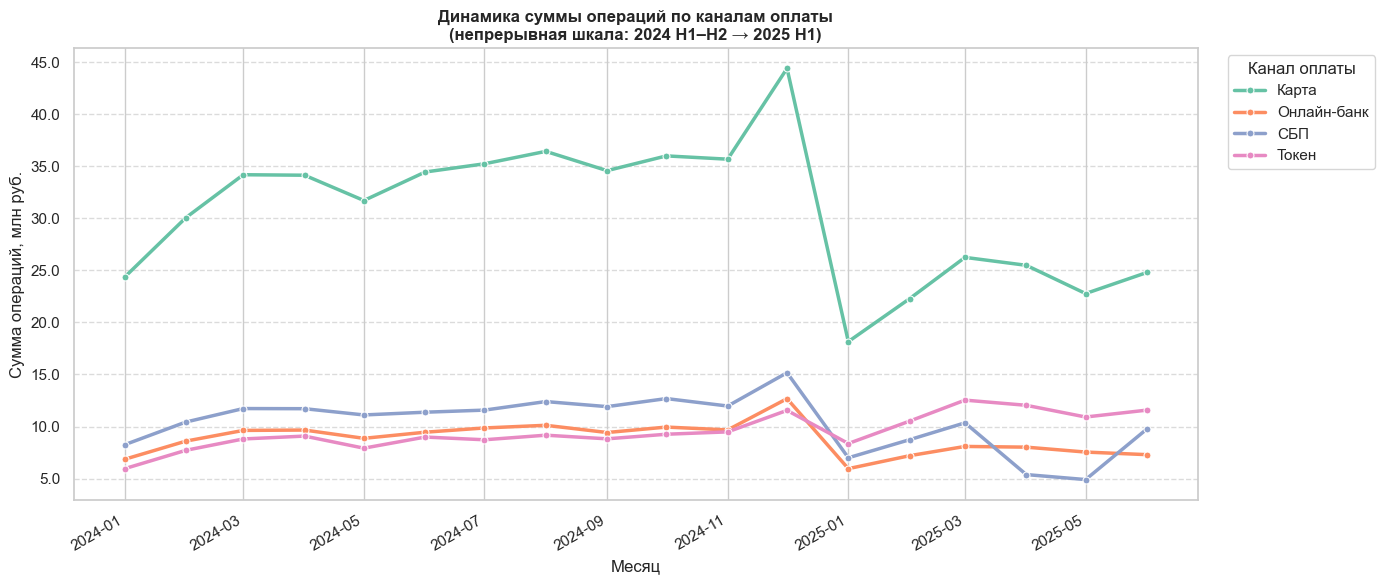


=== СВОДКА ИЗМЕНЕНИЙ (Июнь 2025 vs Июнь 2024) ===
Операции:        34,225 → 30,339 (-11.4%)
Активные клиенты:4,783 → 4,861 (+1.6%)
Интенсивность:   7.16 → 6.24 (-12.8%)


In [74]:
# 1. Подготовка данных
df_dyn = df_txn_clean[df_txn_clean['status'] != 'отклонено'].copy()
df_dyn['year'] = df_dyn['txn_datetime'].dt.year
df_dyn['month'] = df_dyn['txn_datetime'].dt.month

# Агрегация по месяцам
monthly_stats = df_dyn.groupby(['year', 'month']).agg(
    txn_count=('txn_id', 'count'),
    unique_clients=('client_id', 'nunique'),
    total_amount=('amount', 'sum')
).reset_index()

# Интенсивность: сколько операций в среднем на 1 активного клиента
monthly_stats['txn_per_client'] = monthly_stats['txn_count'] / monthly_stats['unique_clients']

# Разделяем на 2024 и 2025
df_2024 = monthly_stats[monthly_stats['year'] == 2024]
df_2025 = monthly_stats[monthly_stats['year'] == 2025]

month_names = ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн', 'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек']
# =============================================================================
# РИСУНОК 2. Уникальные активные клиенты (MAU)
# =============================================================================
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df_2024['month'], df_2024['unique_clients'], marker='o', linewidth=2.5, color='#7aa86b', label='2024 год')
ax.plot(df_2025['month'], df_2025['unique_clients'], marker='s', linewidth=2.5, color='#e07b39', label='2025 год (H1)')

ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_names)
ax.set_ylabel('Уникальных клиентов (MAU)')
ax.set_title('Динамика количества активных клиентов (MAU)\n(клиент считается, если была хотя бы 1 операция)', fontweight='bold')
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

if not df_2025.empty and not df_2024.empty:
    jun_2024 = df_2024[df_2024['month'] == 6]['unique_clients'].values[0]
    jun_2025 = df_2025[df_2025['month'] == 6]['unique_clients'].values[0]
    drop_pct = (jun_2025 - jun_2024) / jun_2024 * 100
    ax.annotate(f'Изм. YoY: {drop_pct:+.1f}%', xy=(6, jun_2025), xytext=(7, jun_2025 + 100),
                arrowprops=dict(arrowstyle='->', color='black'), fontsize=10)
plt.tight_layout()
plt.show()

# Отфильтровываем 'отклонено' — это технические ошибки, а не активность
df_dyn = df_txn_clean[df_txn_clean['status'] != 'отклонено'].copy()
df_dyn['year'] = df_dyn['txn_datetime'].dt.year
df_dyn['month'] = df_dyn['txn_datetime'].dt.month
# Непрерывная шкала: datetime первого числа месяца
df_dyn['year_month_dt'] = df_dyn['txn_datetime'].dt.to_period('M').dt.to_timestamp()

month_names = ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн', 
               'Июл', 'Авг', 'Сен', 'Окт', 'Ноя', 'Дек']

# -----------------------------------------------------------------------------
# РИСУНОК 1. Суммарный оборот (2024 vs 2025)
# -----------------------------------------------------------------------------
monthly_stats = df_dyn.groupby(['year', 'month']).agg(
    total_amount=('amount', 'sum')
).reset_index()

df_24_amt = monthly_stats[monthly_stats['year'] == 2024]
df_25_amt = monthly_stats[monthly_stats['year'] == 2025]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df_24_amt['month'], df_24_amt['total_amount'] / 1e6, marker='o', linewidth=2.5, color='#5b7db1', label='2024 год')
ax.plot(df_25_amt['month'], df_25_amt['total_amount'] / 1e6, marker='s', linewidth=2.5, color='#c75d4b', label='2025 год (H1)')

ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_names)
ax.set_ylabel('Суммарный оборот, млн руб.')
ax.set_title('Динамика суммарного оборота по месяцам\n(только успешные и возвраты)', fontweight='bold')
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

if not df_25_amt.empty and not df_24_amt.empty:
    jun_2024 = df_24_amt[df_24_amt['month'] == 6]['total_amount'].values[0] / 1e6
    jun_2025 = df_25_amt[df_25_amt['month'] == 6]['total_amount'].values[0] / 1e6
    drop_pct = (jun_2025 - jun_2024) / jun_2024 * 100
    ax.annotate(f'Изм. YoY: {drop_pct:+.1f}%', xy=(6, jun_2025), xytext=(7, jun_2025 + 50),
                arrowprops=dict(arrowstyle='->', color='black'), fontsize=10)
plt.tight_layout()
plt.show()

# -----------------------------------------------------------------------------
# РИСУНОК 2. Количество операций (2024 vs 2025)
# -----------------------------------------------------------------------------
monthly_cnt = df_dyn.groupby(['year', 'month']).agg(txn_count=('txn_id', 'count')).reset_index()
df_24_cnt = monthly_cnt[monthly_cnt['year'] == 2024]
df_25_cnt = monthly_cnt[monthly_cnt['year'] == 2025]

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(df_24_cnt['month'], df_24_cnt['txn_count'], marker='o', linewidth=2.5, color='#5b7db1', label='2024 год')
ax.plot(df_25_cnt['month'], df_25_cnt['txn_count'], marker='s', linewidth=2.5, color='#c75d4b', label='2025 год (H1)')

ax.set_xticks(range(1, 13))
ax.set_xticklabels(month_names)
ax.set_ylabel('Количество операций')
ax.set_title('Динамика количества операций по месяцам\n(только успешные и возвраты)', fontweight='bold')
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.7)

if not df_25_cnt.empty and not df_24_cnt.empty:
    jun_2024 = df_24_cnt[df_24_cnt['month'] == 6]['txn_count'].values[0]
    jun_2025 = df_25_cnt[df_25_cnt['month'] == 6]['txn_count'].values[0]
    drop_pct = (jun_2025 - jun_2024) / jun_2024 * 100
    ax.annotate(f'Изм. YoY: {drop_pct:+.1f}%', xy=(6, jun_2025), xytext=(7, jun_2025 + 5000),
                arrowprops=dict(arrowstyle='->', color='black'), fontsize=10)
plt.tight_layout()
plt.show()


# -----------------------------------------------------------------------------
# АГРЕГАЦИЯ ДЛЯ НЕПРЕРЫВНЫХ ГРАФИКОВ ПО КАТЕГОРИЯМ И КАНАЛАМ
# -----------------------------------------------------------------------------
# Группируем: каждый месяц, каждая категория (или канал) -> count и sum
cat_monthly = df_dyn.groupby(['year_month_dt', 'category']).agg(
    txn_count=('txn_id', 'count'),
    total_amount=('amount', 'sum')
).reset_index()

chan_monthly = df_dyn.groupby(['year_month_dt', 'channel']).agg(
    txn_count=('txn_id', 'count'),
    total_amount=('amount', 'sum')
).reset_index()


# -----------------------------------------------------------------------------
# РИСУНОК 3. Категории трат: количество операций по месяцам
# -----------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 6))
sns.lineplot(data=cat_monthly, x='year_month_dt', y='txn_count', hue='category', 
             linewidth=2, marker='o', markersize=4, palette='tab10', ax=ax)

ax.set_xlabel('Месяц')
ax.set_ylabel('Количество операций')
ax.set_title('Динамика количества операций по категориям трат\n(непрерывная шкала: 2024 H1–H2 → 2025 H1)', fontweight='bold')
ax.legend(title='Категория', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.7)
# Автоматически форматируем даты на оси X
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

# -----------------------------------------------------------------------------
# РИСУНОК 4. Категории трат: сумма операций по месяцам
# -----------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 6))
sns.lineplot(data=cat_monthly, x='year_month_dt', y='total_amount', hue='category', 
             linewidth=2, marker='o', markersize=4, palette='tab10', ax=ax)

ax.set_xlabel('Месяц')
ax.set_ylabel('Сумма операций, млн руб.')
# Переведем Y в миллионы для читаемости
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1e6:.1f}'))
ax.set_title('Динамика суммы операций по категориям трат\n(непрерывная шкала: 2024 H1–H2 → 2025 H1)', fontweight='bold')
ax.legend(title='Категория', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.7)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


# -----------------------------------------------------------------------------
# РИСУНОК 5. Каналы оплаты: количество операций по месяцам
# -----------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 6))
sns.lineplot(data=chan_monthly, x='year_month_dt', y='txn_count', hue='channel', 
             linewidth=2.5, marker='o', markersize=5, palette='Set2', ax=ax)

ax.set_xlabel('Месяц')
ax.set_ylabel('Количество операций')
ax.set_title('Динамика количества операций по каналам оплаты\n(непрерывная шкала: 2024 H1–H2 → 2025 H1)', fontweight='bold')
ax.legend(title='Канал оплаты', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.7)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

# -----------------------------------------------------------------------------
# РИСУНОК 6. Каналы оплаты: сумма операций по месяцам
# -----------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 6))
sns.lineplot(data=chan_monthly, x='year_month_dt', y='total_amount', hue='channel', 
             linewidth=2.5, marker='o', markersize=5, palette='Set2', ax=ax)

ax.set_xlabel('Месяц')
ax.set_ylabel('Сумма операций, млн руб.')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'{x/1e6:.1f}'))
ax.set_title('Динамика суммы операций по каналам оплаты\n(непрерывная шкала: 2024 H1–H2 → 2025 H1)', fontweight='bold')
ax.legend(title='Канал оплаты', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.7)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()


# Вывод цифр в консоль для сверки
print("\n" + "=" * 60)
print("=== СВОДКА ИЗМЕНЕНИЙ (Июнь 2025 vs Июнь 2024) ===")
print("=" * 60)
if not df_2025.empty:
    j24 = df_2024[df_2024['month'] == 6].iloc[0]
    j25 = df_2025[df_2025['month'] == 6].iloc[0]
    
    print(f"Операции:        {int(j24['txn_count']):,} → {int(j25['txn_count']):,} "
          f"({(j25['txn_count']-j24['txn_count'])/j24['txn_count']*100:+.1f}%)")
    print(f"Активные клиенты:{int(j24['unique_clients']):,} → {int(j25['unique_clients']):,} "
          f"({(j25['unique_clients']-j24['unique_clients'])/j24['unique_clients']*100:+.1f}%)")
    print(f"Интенсивность:   {j24['txn_per_client']:.2f} → {j25['txn_per_client']:.2f} "
          f"({(j25['txn_per_client']-j24['txn_per_client'])/j24['txn_per_client']*100:+.1f}%)")

### 5.4. Разрезы и связи между признаками

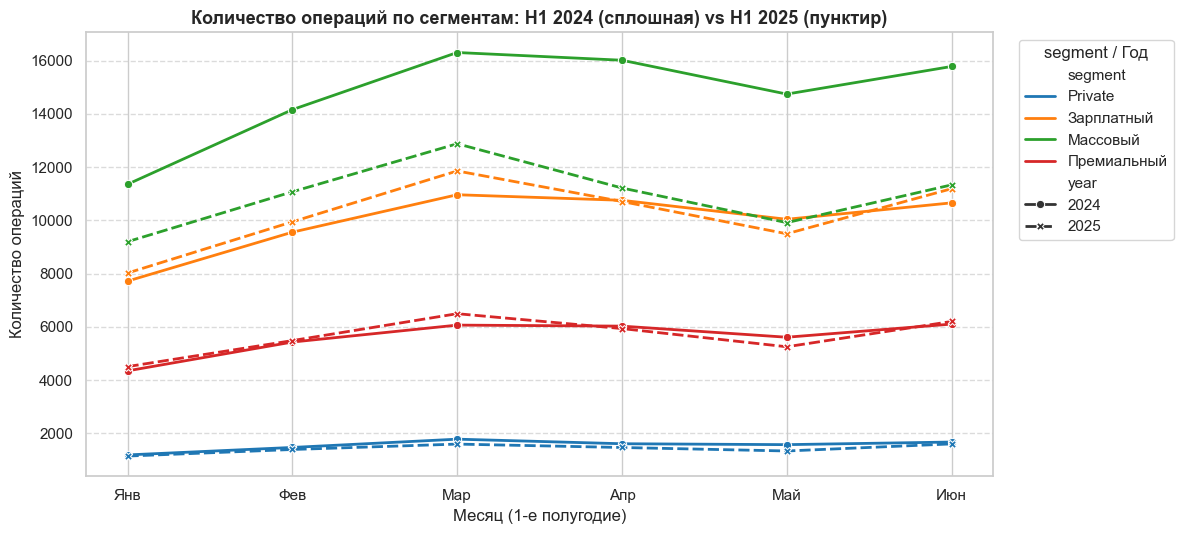


--- СВОДКА H1: Количество операций по сегментам: H1 2024 (сплошная) vs H1 2025 (пунктир) ---


,H1_2024,H1_2025,Изм. %
segment,,,
Private,"9,333","8,579",-8.1%
Зарплатный,"59,700","61,227",+2.6%
Массовый,"88,357","65,624",-25.7%
Премиальный,"33,606","33,898",+0.9%


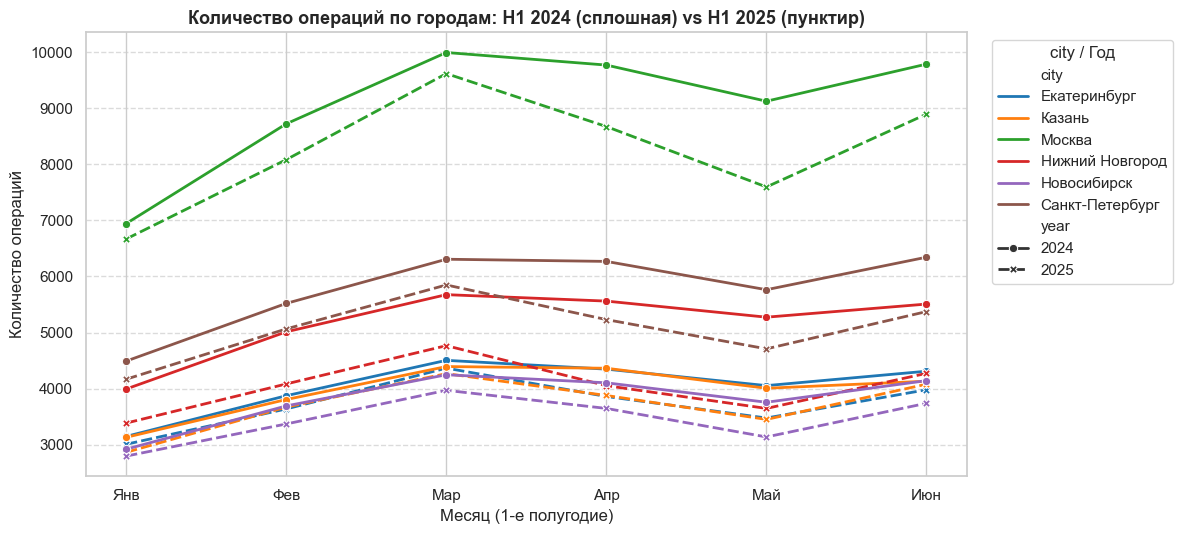


--- СВОДКА H1: Количество операций по городам: H1 2024 (сплошная) vs H1 2025 (пунктир) ---


,H1_2024,H1_2025,Изм. %
city,,,
Екатеринбург,"24,234","22,322",-7.9%
Казань,"23,830","22,207",-6.8%
Москва,"54,353","49,544",-8.8%
Нижний Новгород,"31,025","24,204",-22.0%
Новосибирск,"22,858","20,655",-9.6%
Санкт-Петербург,"34,696","30,396",-12.4%


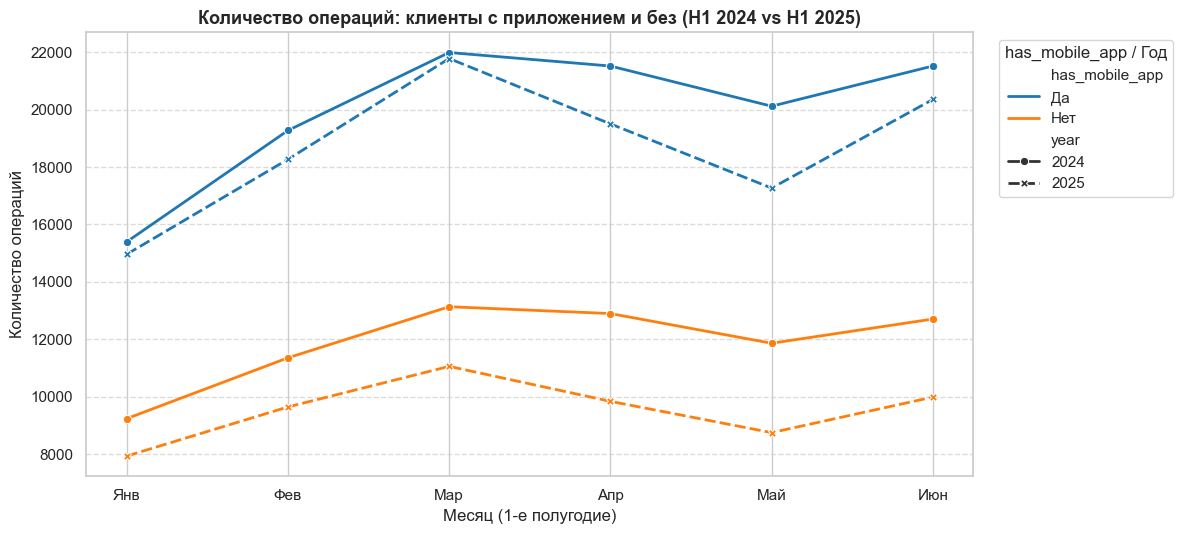


--- СВОДКА H1: Количество операций: клиенты с приложением и без (H1 2024 vs H1 2025) ---


,H1_2024,H1_2025,Изм. %
has_mobile_app,,,
Да,"119,819","112,137",-6.4%
Нет,"71,177","57,191",-19.6%


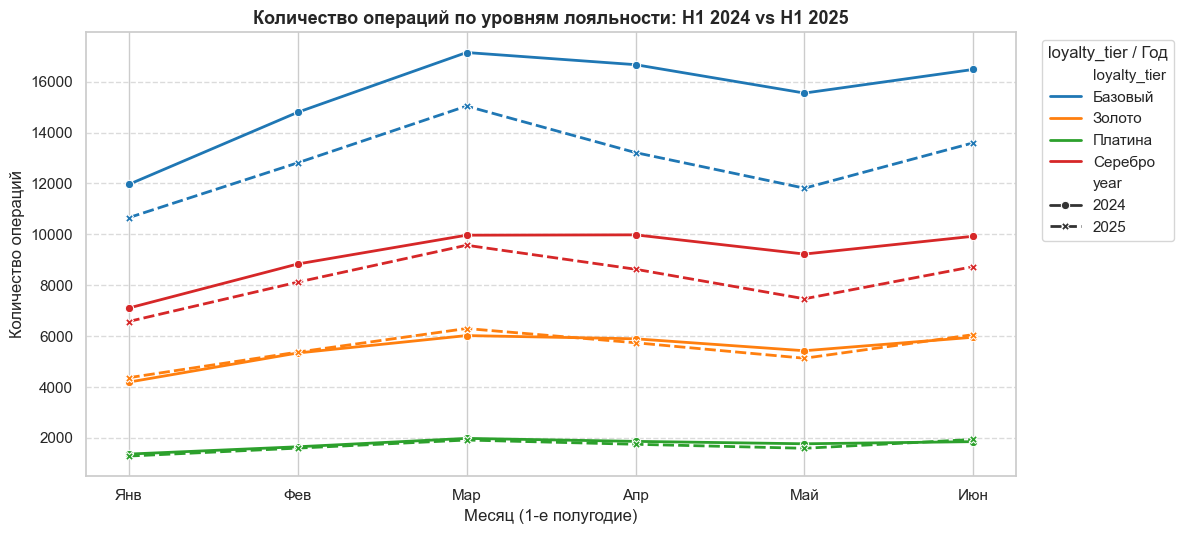


--- СВОДКА H1: Количество операций по уровням лояльности: H1 2024 vs H1 2025 ---


,H1_2024,H1_2025,Изм. %
loyalty_tier,,,
Базовый,"92,610","77,140",-16.7%
Золото,"32,841","32,980",+0.4%
Платина,"10,500","10,098",-3.8%
Серебро,"55,045","49,110",-10.8%


In [75]:
# Объединяем транзакции с клиентами. Исключаем 'отклонено'.
df_txn_cat = df_txn_clean[df_txn_clean['status'] != 'отклонено'].copy()
df_txn_cat = df_txn_cat.merge(
    df_clients[['client_id', 'segment', 'city', 'has_mobile_app', 'loyalty_tier']], 
    on='client_id', how='left'
)

# Оставляем только первое полугодие (месяцы 1-6) и годы 2024/2025
df_txn_cat['year'] = df_txn_cat['txn_datetime'].dt.year
df_txn_cat['month'] = df_txn_cat['txn_datetime'].dt.month
df_txn_cat = df_txn_cat[
    (df_txn_cat['year'].isin([2024, 2025])) & 
    (df_txn_cat['month'] <= 6)
]

month_names = ['Янв', 'Фев', 'Мар', 'Апр', 'Май', 'Июн']

# Функция для отрисовки и вывода сводки
def plot_h1_comparison(df, col_name, title):
    # 1. Группировка: категория, год, месяц -> количество операций
    agg = df.groupby([col_name, 'year', 'month']).agg(
        txn_count=('txn_id', 'count')
    ).reset_index()
    
    # Отрисовка
    fig, ax = plt.subplots(figsize=(12, 5.5))
    # style='year' автоматически сделает 2024 сплошной, а 2025 пунктирной
    sns.lineplot(
        data=agg, x='month', y='txn_count', 
        hue=col_name, style='year', 
        markers=True, dashes=True, 
        palette='tab10', linewidth=2, ax=ax
    )
    
    ax.set_xticks(range(1, 7))
    ax.set_xticklabels(month_names)
    ax.set_xlabel('Месяц (1-е полугодие)')
    ax.set_ylabel('Количество операций')
    ax.set_title(title, fontweight='bold', fontsize=13)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    
    # Переносим легенду за пределы графика, чтобы не перекрывала линии
    ax.legend(title=f'{col_name} / Год', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()
    
    # 2. Сводка за всё полугодие (H1)
    agg_h1 = df.groupby([col_name, 'year']).agg(
        txn_count=('txn_id', 'count')
    ).unstack(fill_value=0)
    
    agg_h1.columns = ['H1_2024', 'H1_2025']
    agg_h1['Изм. %'] = (agg_h1['H1_2025'] - agg_h1['H1_2024']) / agg_h1['H1_2024'] * 100
    
    # Красивый вывод таблицы
    print(f"\n--- СВОДКА H1: {title.split(chr(10))[0]} ---")
    display(agg_h1.style.format({
        'H1_2024': '{:,.0f}', 
        'H1_2025': '{:,.0f}', 
        'Изм. %': '{:+.1f}%'
    }).background_gradient(cmap='RdYlGn', subset=['Изм. %']))


# =============================================================================
# СТРОИМ 4 ГРАФИКА
# =============================================================================

# 1. По сегментам
plot_h1_comparison(df_txn_cat, 'segment', 
                   'Количество операций по сегментам: H1 2024 (сплошная) vs H1 2025 (пунктир)')

# 2. По городам (обрати внимание: здесь может вылезти та самая "москва" с маленькой буквы)
plot_h1_comparison(df_txn_cat, 'city', 
                   'Количество операций по городам: H1 2024 (сплошная) vs H1 2025 (пунктир)')

# 3. По наличию приложения
plot_h1_comparison(df_txn_cat, 'has_mobile_app', 
                   'Количество операций: клиенты с приложением и без (H1 2024 vs H1 2025)')

# 4. По уровню лояльности
plot_h1_comparison(df_txn_cat, 'loyalty_tier', 
                   'Количество операций по уровням лояльности: H1 2024 vs H1 2025')

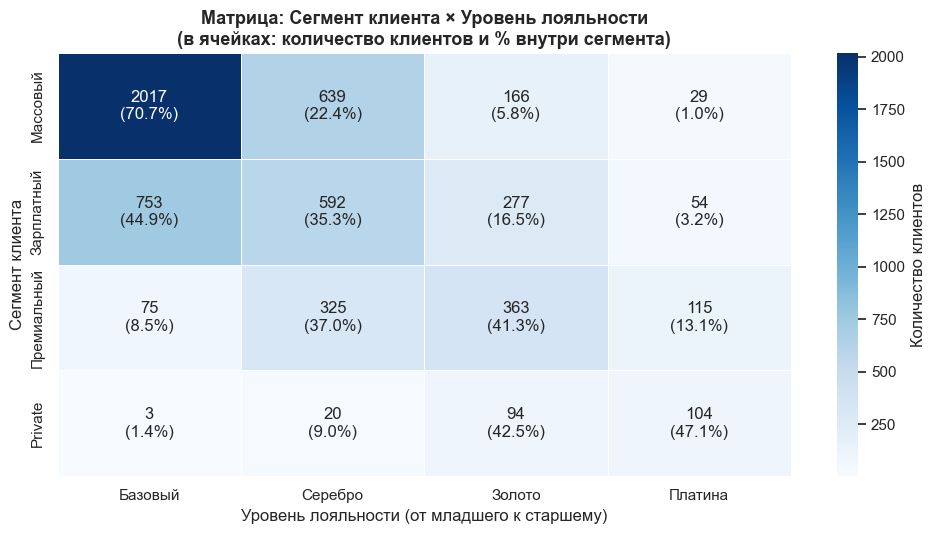

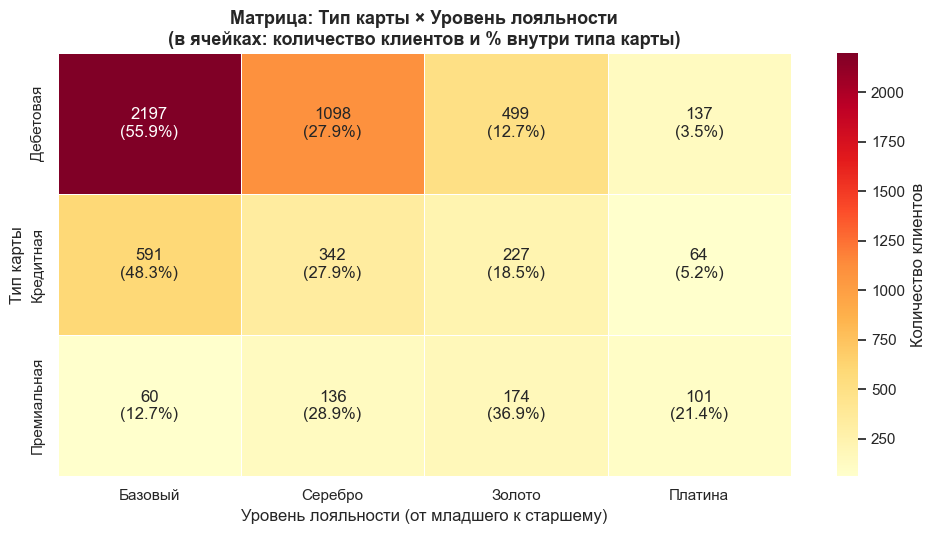

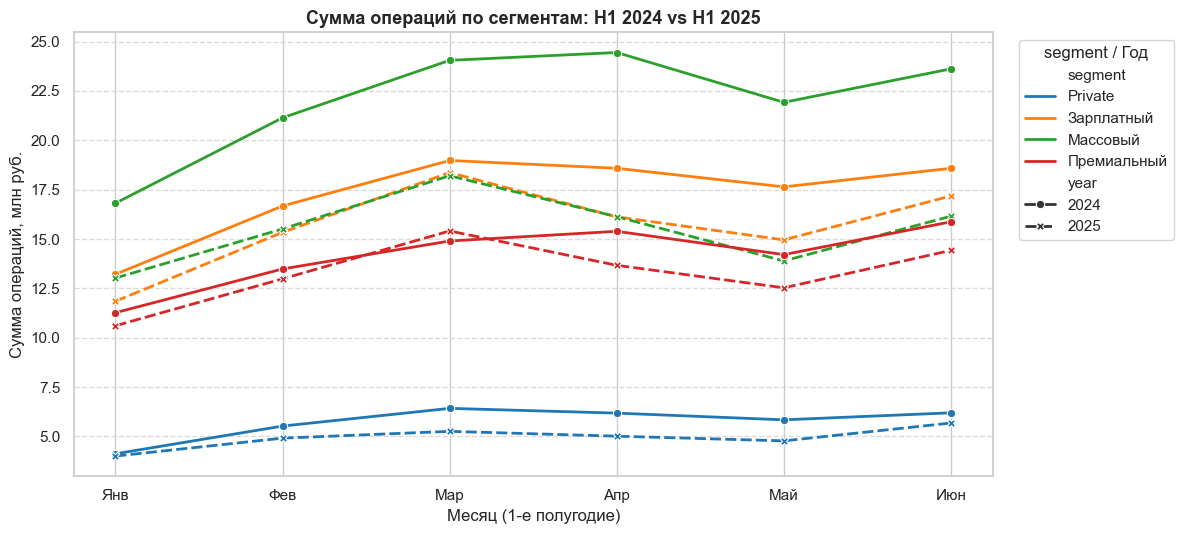


--- СВОДКА H1 (СУММА, МЛН РУБ.): Сумма операций по сегментам: H1 2024 vs H1 2025 ---


,H1_2024_млн,H1_2025_млн,Изм. %
segment,,,
Private,34.3,29.6,-13.5%
Зарплатный,103.7,93.8,-9.5%
Массовый,132.0,92.9,-29.6%
Премиальный,85.1,79.6,-6.5%


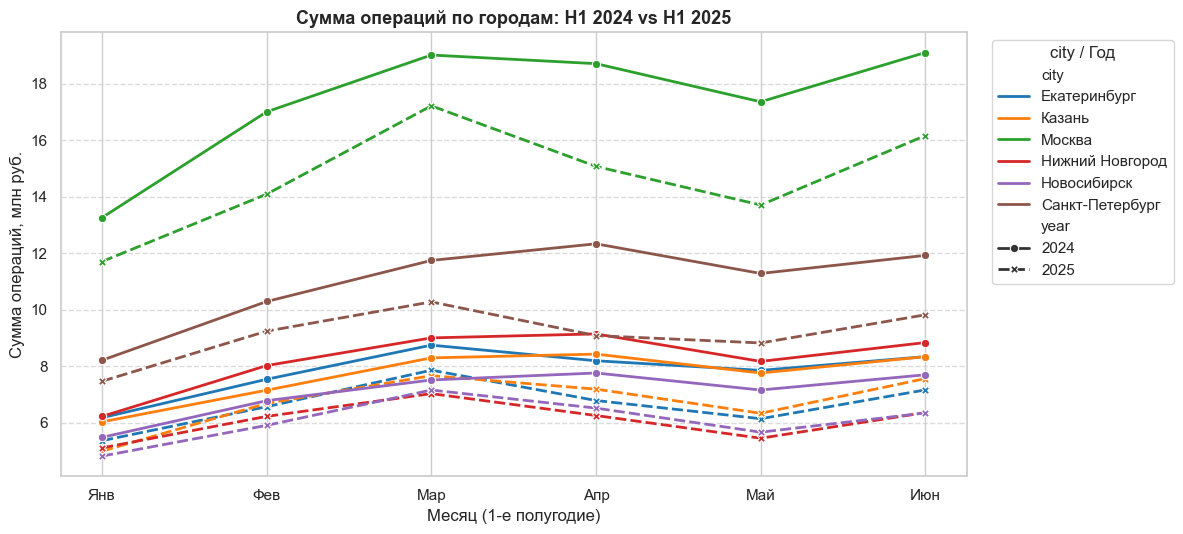


--- СВОДКА H1 (СУММА, МЛН РУБ.): Сумма операций по городам: H1 2024 vs H1 2025 ---


,H1_2024_млн,H1_2025_млн,Изм. %
city,,,
Екатеринбург,46.9,39.9,-14.9%
Казань,46.0,40.4,-12.1%
Москва,104.5,88.0,-15.8%
Нижний Новгород,49.4,36.4,-26.3%
Новосибирск,42.4,36.4,-14.1%
Санкт-Петербург,65.8,54.7,-16.8%


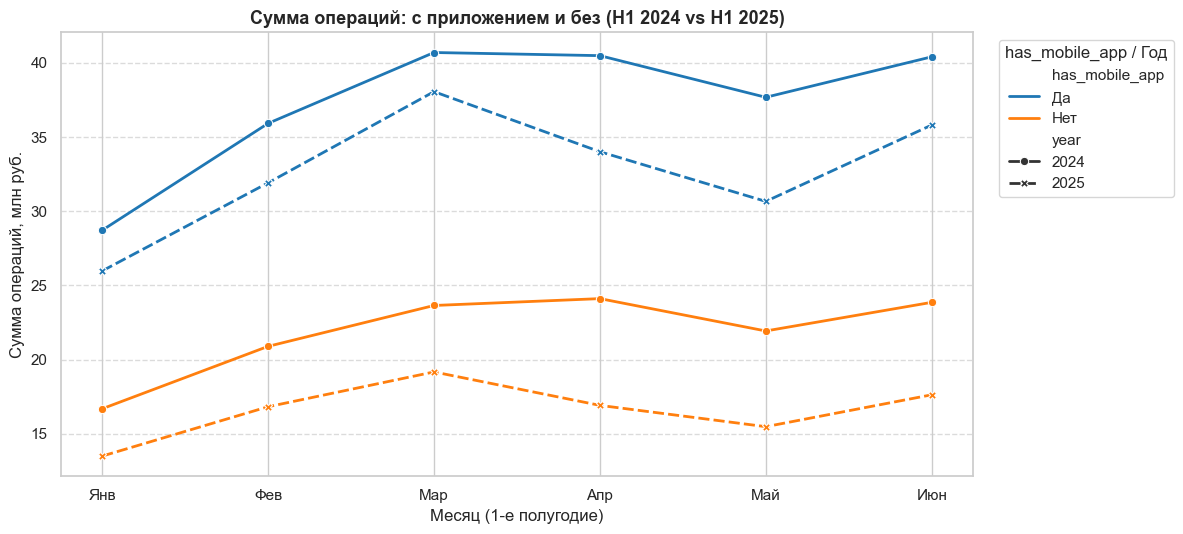


--- СВОДКА H1 (СУММА, МЛН РУБ.): Сумма операций: с приложением и без (H1 2024 vs H1 2025) ---


,H1_2024_млн,H1_2025_млн,Изм. %
has_mobile_app,,,
Да,223.9,196.5,-12.3%
Нет,131.1,99.5,-24.1%


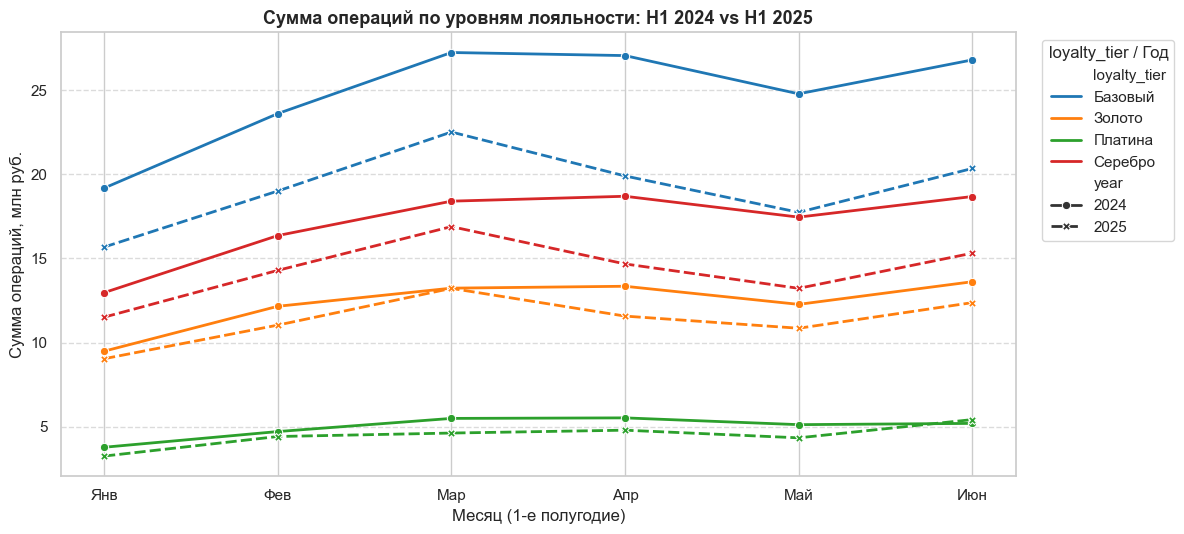


--- СВОДКА H1 (СУММА, МЛН РУБ.): Сумма операций по уровням лояльности: H1 2024 vs H1 2025 ---


,H1_2024_млн,H1_2025_млн,Изм. %
loyalty_tier,,,
Базовый,148.6,115.1,-22.5%
Золото,74.1,68.1,-8.1%
Платина,29.8,26.9,-10.0%
Серебро,102.5,85.9,-16.2%


In [76]:
# =============================================================================
# 5.4 (продолжение). ДИНАМИКА СУММ ОПЕРАЦИЙ ПО КАТЕГОРИЯМ (H1 2024 vs H1 2025)
# =============================================================================

# =============================================================================
# ТЕПЛОВАЯ КАРТА: СЕГМЕНТ vs УРОВЕНЬ ЛОЯЛЬНОСТИ
# =============================================================================

SEGMENT_ORDER = ['Массовый', 'Зарплатный', 'Премиальный', 'Private']
LOYALTY_ORDER = ['Базовый', 'Серебро', 'Золото', 'Платина']

# Строим кросс-таблицу
ct_seg = pd.crosstab(df_clients['segment'], df_clients['loyalty_tier'])
ct_seg = ct_seg.reindex(index=SEGMENT_ORDER, columns=LOYALTY_ORDER, fill_value=0)

# Проценты по строкам (внутри каждого сегмента)
ct_seg_pct = ct_seg.div(ct_seg.sum(axis=1), axis=0) * 100

# Аннотации: Число \n (Процент)
annot_seg = ct_seg.astype(str) + '\n(' + ct_seg_pct.round(1).astype(str) + '%)'

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.heatmap(
    ct_seg, 
    annot=annot_seg, 
    fmt='', 
    cmap='Blues', 
    linewidths=0.5, 
    cbar_kws={'label': 'Количество клиентов'},
    ax=ax
)

ax.set_title('Матрица: Сегмент клиента × Уровень лояльности\n(в ячейках: количество клиентов и % внутри сегмента)', 
             fontweight='bold', fontsize=13)
ax.set_xlabel('Уровень лояльности (от младшего к старшему)')
ax.set_ylabel('Сегмент клиента')
plt.tight_layout()
plt.show()


# =============================================================================
# ТЕПЛОВАЯ КАРТА: ТИП КАРТЫ vs УРОВЕНЬ ЛОЯЛЬНОСТИ
# =============================================================================

# Задаем порядок категорий (от младшего к старшему)
CARD_ORDER = ['Дебетовая', 'Кредитная', 'Премиальная']
LOYALTY_ORDER = ['Базовый', 'Серебро', 'Золото', 'Платина']

# Строим кросс-таблицу (абсолютные значения)
ct = pd.crosstab(df_clients['card_type'], df_clients['loyalty_tier'])
ct = ct.reindex(index=CARD_ORDER, columns=LOYALTY_ORDER, fill_value=0)

# Считаем проценты по строкам (внутри каждого типа карты)
ct_pct = ct.div(ct.sum(axis=1), axis=0) * 100

# Создаем кастомные аннотации: число + процент
annot_labels = ct.astype(str) + '\n(' + ct_pct.round(1).astype(str) + '%)'

# Отрисовка
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.heatmap(
    ct, 
    annot=annot_labels, 
    fmt='', 
    cmap='YlOrRd', 
    linewidths=0.5, 
    cbar_kws={'label': 'Количество клиентов'},
    ax=ax
)

ax.set_title('Матрица: Тип карты × Уровень лояльности\n(в ячейках: количество клиентов и % внутри типа карты)', 
             fontweight='bold', fontsize=13)
ax.set_xlabel('Уровень лояльности (от младшего к старшему)')
ax.set_ylabel('Тип карты')
plt.tight_layout()
plt.show()

def plot_h1_amount_comparison(df, col_name, title):
    # Группировка: категория, год, месяц -> сумма операций
    agg = df.groupby([col_name, 'year', 'month']).agg(
        total_amount=('amount', 'sum')
    ).reset_index()
    agg['total_amount_mln'] = agg['total_amount'] / 1e6
    
    # Отрисовка
    fig, ax = plt.subplots(figsize=(12, 5.5))
    sns.lineplot(
        data=agg, x='month', y='total_amount_mln', 
        hue=col_name, style='year', 
        markers=True, dashes=True, 
        palette='tab10', linewidth=2, ax=ax
    )
    
    ax.set_xticks(range(1, 7))
    ax.set_xticklabels(month_names)
    ax.set_xlabel('Месяц (1-е полугодие)')
    ax.set_ylabel('Сумма операций, млн руб.')
    ax.set_title(title, fontweight='bold', fontsize=13)
    ax.grid(axis='y', linestyle='--', alpha=0.7)
    ax.legend(title=f'{col_name} / Год', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()
    
    # Сводка за H1
    agg_h1 = df.groupby([col_name, 'year']).agg(
        total_amount=('amount', 'sum')
    ).unstack(fill_value=0)
    agg_h1.columns = ['H1_2024_млн', 'H1_2025_млн']
    agg_h1 = agg_h1 / 1e6
    agg_h1['Изм. %'] = (agg_h1['H1_2025_млн'] - agg_h1['H1_2024_млн']) / agg_h1['H1_2024_млн'] * 100
    
    print(f"\n--- СВОДКА H1 (СУММА, МЛН РУБ.): {title.split(chr(10))[0]} ---")
    display(agg_h1.style.format({
        'H1_2024_млн': '{:,.1f}', 
        'H1_2025_млн': '{:,.1f}', 
        'Изм. %': '{:+.1f}%'
    }).background_gradient(cmap='RdYlGn', subset=['Изм. %']))

# Строим те же 4 графика, но для сумм
plot_h1_amount_comparison(df_txn_cat, 'segment', 'Сумма операций по сегментам: H1 2024 vs H1 2025')
plot_h1_amount_comparison(df_txn_cat, 'city', 'Сумма операций по городам: H1 2024 vs H1 2025')
plot_h1_amount_comparison(df_txn_cat, 'has_mobile_app', 'Сумма операций: с приложением и без (H1 2024 vs H1 2025)')
plot_h1_amount_comparison(df_txn_cat, 'loyalty_tier', 'Сумма операций по уровням лояльности: H1 2024 vs H1 2025')

C:\Users\User\AppData\Local\Temp\ipykernel_14228\2768345155.py:43: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=agg_login, x='login_group', y='median_drop', ax=ax, palette='Reds_r')


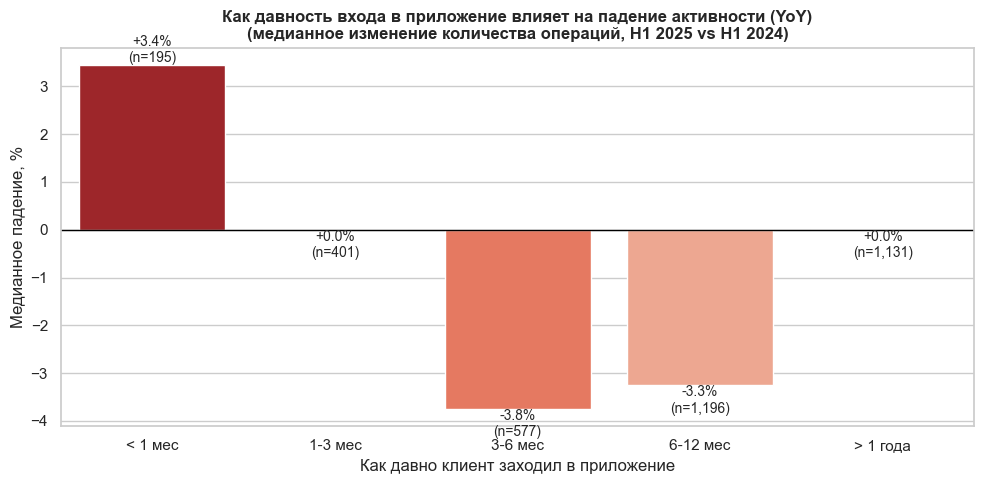

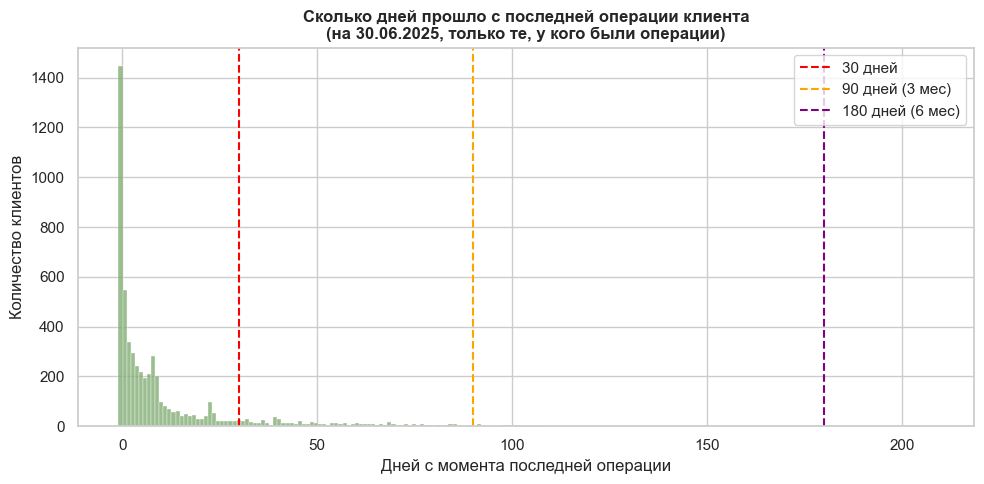

Доля клиентов без операций > 90 дней: 1.5% (86 чел.)
Доля клиентов без операций > 180 дней: 0.1% (6 чел.)


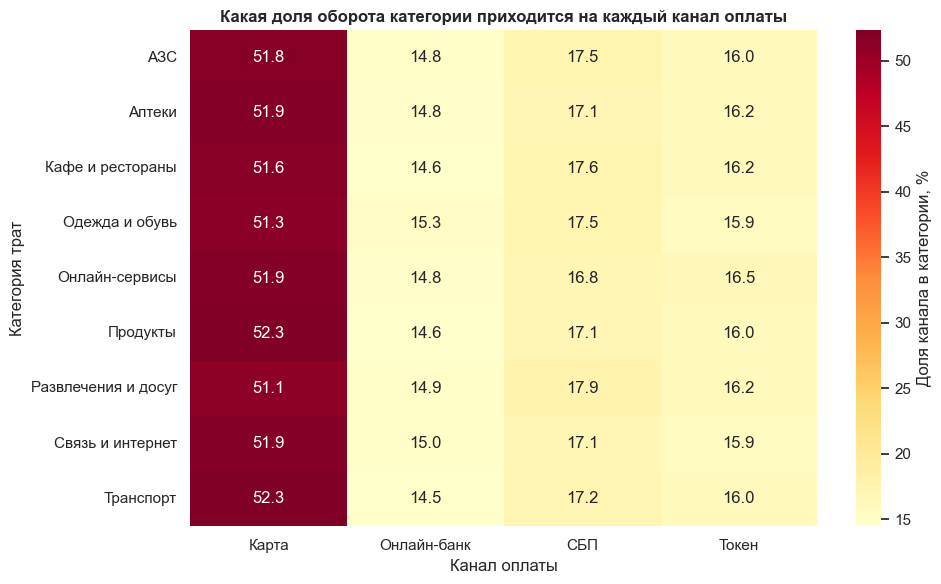

In [77]:
# =============================================================================
# ДОПОЛНИТЕЛЬНЫЕ ГРАФИКИ ДЛЯ 5.4 / 6 / 7
# =============================================================================
SNAPSHOT_DATE = pd.to_datetime('2025-06-30')

# Общая подготовка: считаем по клиенту, сколько он тратил в H1 24 и H1 25
df_dyn = df_txn_clean[df_txn_clean['status'] != 'отклонено'].copy()
df_dyn['year'] = df_dyn['txn_datetime'].dt.year
df_dyn['month'] = df_dyn['txn_datetime'].dt.month
df_h1 = df_dyn[df_dyn['month'] <= 6]

client_yoy = df_h1.groupby(['client_id', 'year']).agg(txn_count=('txn_id', 'count')).reset_index()
pivot_yoy = client_yoy.pivot(index='client_id', columns='year', values='txn_count').fillna(0)
pivot_yoy.columns = ['cnt_2024', 'cnt_2025']
pivot_yoy['drop_pct'] = (pivot_yoy['cnt_2025'] - pivot_yoy['cnt_2024']) / pivot_yoy['cnt_2024'] * 100

# Приклеиваем дату последнего входа и последнюю транзакцию
df_clients['app_login_days_ago'] = (SNAPSHOT_DATE - df_clients['app_last_login']).dt.days
last_txn_date = df_txn_clean.groupby('client_id')['txn_datetime'].max().reset_index()
last_txn_date['txn_days_ago'] = (SNAPSHOT_DATE - last_txn_date['txn_datetime']).dt.days
df_client_extra = df_clients[['client_id', 'has_mobile_app', 'app_login_days_ago']].merge(
    last_txn_date[['client_id', 'txn_days_ago']], on='client_id', how='left'
).merge(pivot_yoy, on='client_id', how='left')


# -----------------------------------------------------------------------------
# 1. ЗАВИСИМОСТЬ ПАДЕНИЯ ОТ ДАВНОСТИ ВХОДА В ПРИЛОЖЕНИЕ
# -----------------------------------------------------------------------------
df_app = df_client_extra[(df_client_extra['has_mobile_app'] == 'Да') & 
                         (df_client_extra['drop_pct'].notna())].copy()

# Бьем на группы по давности входа
bins = [-1, 30, 90, 180, 365, 10000]
labels = ['< 1 мес', '1-3 мес', '3-6 мес', '6-12 мес', '> 1 года']
df_app['login_group'] = pd.cut(df_app['app_login_days_ago'], bins=bins, labels=labels)

agg_login = df_app.groupby('login_group', observed=False).agg(
    median_drop=('drop_pct', 'median'),
    n_clients=('drop_pct', 'count')
).reset_index()

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=agg_login, x='login_group', y='median_drop', ax=ax, palette='Reds_r')
ax.axhline(0, color='black', linewidth=1)
ax.set_title('Как давность входа в приложение влияет на падение активности (YoY)\n(медианное изменение количества операций, H1 2025 vs H1 2024)', fontweight='bold')
ax.set_xlabel('Как давно клиент заходил в приложение')
ax.set_ylabel('Медианное падение, %')
for i, v in enumerate(agg_login['median_drop']):
    ax.text(i, v, f'{v:+.1f}%\n(n={agg_login["n_clients"][i]:,})', 
            ha='center', va='bottom' if v>0 else 'top', fontsize=10)
plt.tight_layout()
plt.show()

# -----------------------------------------------------------------------------
# 2. РАСПРЕДЕЛЕНИЕ «ДАВНОСТИ ПОСЛЕДНЕЙ ТРАНЗАКЦИИ» (Recency)
# -----------------------------------------------------------------------------
# Сколько клиентов вообще «спят» прямо сейчас (на 30.06.2025)?
recency_clean = df_client_extra['txn_days_ago'].dropna()
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(recency_clean, bins=200, color='#7aa86b', ax=ax)
ax.axvline(30, color='red', linestyle='--', label='30 дней')
ax.axvline(90, color='orange', linestyle='--', label='90 дней (3 мес)')
ax.axvline(180, color='purple', linestyle='--', label='180 дней (6 мес)')
ax.set_title('Сколько дней прошло с последней операции клиента\n(на 30.06.2025, только те, у кого были операции)', fontweight='bold')
ax.set_xlabel('Дней с момента последней операции')
ax.set_ylabel('Количество клиентов')
ax.legend()
plt.tight_layout()
plt.show()

# Выведем в консоль долю "спящих"
total_with_txn = len(recency_clean)
sleep_90 = (recency_clean > 90).sum()
sleep_180 = (recency_clean > 180).sum()
print(f"Доля клиентов без операций > 90 дней: {sleep_90/total_with_txn*100:.1f}% ({sleep_90:,} чел.)")
print(f"Доля клиентов без операций > 180 дней: {sleep_180/total_with_txn*100:.1f}% ({sleep_180:,} чел.)")

# -----------------------------------------------------------------------------
# 5. ТЕПЛОВАЯ КАРТА: КАНАЛЫ × КАТЕГОРИИ
# -----------------------------------------------------------------------------
# Показывает, какой канал доминирует в какой категории
heatmap_data = pd.crosstab(df_txn_clean['category'], df_txn_clean['channel'], 
                           values=df_txn_clean['amount'], aggfunc='sum').fillna(0)

# Нормируем по строкам (чтобы в каждой категории сумма долей была 100%)
heatmap_pct = heatmap_data.div(heatmap_data.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(10, 6))
sns.heatmap(heatmap_pct, annot=True, fmt='.1f', cmap='YlOrRd', 
            cbar_kws={'label': 'Доля канала в категории, %'}, ax=ax)
ax.set_title('Какая доля оборота категории приходится на каждый канал оплаты', fontweight='bold')
ax.set_xlabel('Канал оплаты')
ax.set_ylabel('Категория трат')
plt.tight_layout()
plt.show()

## 6. Метрика активности

Что именно вы считаете активностью, как она вычисляется, на каком
множестве клиентов, за какие окна. Отдельно: какое снижение эта метрика
**не увидит**.

### 6. Метрика активности

В ходе анализа мы протестировали две метрики активности: **частоту операций** и **сумму трат**. Итоговой метрикой выбрана **сумма трат**, так как она напрямую коррелирует с комиссионным доходом банка (интерчейндж) и отражает реальную потерю оборота. Частота операций используется как вспомогательный признак для более точного описания групп.

#### Как считаем (Формулы)
Окна сравнения: **H1 2024** (январь–июнь 2024) против **H1 2025** (январь–июнь 2025). Чтобы привести периоды к единому знаменателю, считаем **среднемесячные значения** (делим на 6 месяцев).

1. **Среднемесячная сумма трат (H1 2024):**
   `avg_sum_2024 = (Сумма всех успешных операций в H1 2024) / 6`
2. **Среднемесячная сумма трат (H1 2025):**
   `avg_sum_2025 = (Сумма всех успешных операций в H1 2025) / 6`
3. **Относительное падение суммы:**
   `drop_sum_pct = ((avg_sum_2025 - avg_sum_2024) / avg_sum_2024) * 100%`

*База для расчёта:* клиенты, совершившие хотя бы одну операцию в H1 2024 (чтобы избежать деления на ноль). Клиенты без истории в 2024 году исключены как «новые».

#### Что метрика НЕ увидит (слепые зоны)

**Если считать по частоте (количество операций):**
*   Метрика **не увидит измельчания сумм**. Клиент может делать 20 операций по 100 рублей, а раньше делал 10 по 5000 рублей. Формально активность выросла, а банк заработал меньше.
*   Метрика не учитывает инфляцию: если цены выросли, человек может делать меньше операций, просто потому что покупает реже и крупнее.

**Если считать по сумме (выбранная метрика):**
*   Метрика **не видит, что остались только крупные суммы**. Клиент мог перестать покупать кофе и продукты каждый день (мелкие операции), но оставить ежемесячный платёж по ипотеке (одна крупная операция). Сумма при этом могла не упасть, хотя ежедневная привычка использовать карту исчезла.
*   Метрика **подвержена разовым колебаниям**. Покупка холодильника за 50 000 рублей в мае 2024 года и его отсутствие в 2025-м создадут иллюзию «обвала», хотя привычки клиента не изменились.

**Итоговый компромисс:** 
Выбор суммы трат в качестве основной метрики позволяет точнее ответить на бизнес-запрос «где мы теряем деньги». Именно по этой метрике построены итоговые группы в Разделе 7 (масок от `<= -20%` до `<= -40%`).

In [78]:

# 1. Подготовка транзакций
df_metric = df_txn_clean[df_txn_clean['status'] == 'успешно'].copy()
df_metric['year'] = df_metric['txn_datetime'].dt.year
df_metric['month'] = df_metric['txn_datetime'].dt.month

# Оставляем только H1 (январь-июнь) для 2024 и 2025
df_metric = df_metric[
    (df_metric['year'].isin([2024, 2025])) & 
    (df_metric['month'] <= 6)
]

# 2. Агрегация: сколько операций и какая сумма у клиента за H1 каждого года
client_h1 = df_metric.groupby(['client_id', 'year']).agg(
    txn_count=('txn_id', 'count'),
    txn_sum=('amount', 'sum')
).reset_index()

# 3. Разворачиваем в одну строку на клиента (колонки 2024 и 2025)
client_pivot = client_h1.pivot(index='client_id', columns='year', 
                               values=['txn_count', 'txn_sum']).fillna(0)
client_pivot.columns = [f'{col[0]}_{col[1]}' for col in client_pivot.columns]

# 4. Переводим в СРЕДНЕМЕСЯЧНЫЕ значения (делим на 6, т.к. окно — H1)
client_pivot['avg_cnt_2024'] = client_pivot['txn_count_2024'] / 6
client_pivot['avg_cnt_2025'] = client_pivot['txn_count_2025'] / 6
client_pivot['avg_sum_2024'] = client_pivot['txn_sum_2024'] / 6
client_pivot['avg_sum_2025'] = client_pivot['txn_sum_2025'] / 6

# 5. Оставляем только тех, у кого были операции в H1 2024 (база для сравнения)
# Иначе мы не сможем посчитать падение (будет деление на ноль)
client_pivot = client_pivot[client_pivot['txn_count_2024'] > 0].copy()

# 6. Считаем относительное изменение (в %)
# Для частоты операций
client_pivot['drop_cnt_pct'] = (
    (client_pivot['avg_cnt_2025'] - client_pivot['avg_cnt_2024']) 
    / client_pivot['avg_cnt_2024'] * 100
)

# Для суммы трат (дополнительный признак)
client_pivot['drop_sum_pct'] = (
    (client_pivot['avg_sum_2025'] - client_pivot['avg_sum_2024']) 
    / client_pivot['avg_sum_2024'] * 100
)

# 7. Приклеиваем признаки клиентов для дальнейшей сегментации (для 7-го раздела)
client_metrics = df_clients.set_index('client_id').join(
    client_pivot[['avg_cnt_2024', 'avg_cnt_2025', 'drop_cnt_pct', 
                  'avg_sum_2024', 'avg_sum_2025', 'drop_sum_pct']], 
    how='inner'
).reset_index()

# -----------------------------------------------------------------------------
# 8. Проверка и сводка
# -----------------------------------------------------------------------------
print(f"Клиентов в базе (с операциями в H1 2024): {len(client_metrics):,}")
print(f"Медианная частота операций в месяц (H1 2024): {client_metrics['avg_sum_2024'].median():.2f}")
print(f"Медианная частота операций в месяц (H1 2025): {client_metrics['avg_sum_2025'].median():.2f}")
print(f"Медианное изменение частоты: {client_metrics['drop_cnt_pct'].median():+.1f}%")
print(f"Медианное изменение суммы:   {client_metrics['drop_sum_pct'].median():+.1f}%")

# Распределение падения по корзинам (для 7-го раздела)
bins = [-100, -70, -30, -10, 10, 10000]
labels = ['Обвал (< -70%)', 'Сильное (-30..-70%)', 'Умеренное (-10..-30%)', 
          'Стабильно (-10..+10%)', 'Рост (> +10%)']
client_metrics['drop_bucket'] = pd.cut(
    client_metrics['drop_sum_pct'], bins=bins, labels=labels
)

print("\nРаспределение клиентов по характеру падения частоты:")
print(client_metrics['drop_bucket'].value_counts().sort_index().to_string())

# Краткая проверка таблицы
display(client_metrics[['client_id', 'segment', 'avg_sum_2024', 'avg_sum_2025', 
                        'drop_cnt_pct', 'drop_sum_pct', 'drop_bucket']].head())

Клиентов в базе (с операциями в H1 2024): 4,857
Медианная частота операций в месяц (H1 2024): 9791.65
Медианная частота операций в месяц (H1 2025): 6743.28
Медианное изменение частоты: -14.8%
Медианное изменение суммы:   -30.2%

Распределение клиентов по характеру падения частоты:
drop_bucket
Обвал (< -70%)            708
Сильное (-30..-70%)      1719
Умеренное (-10..-30%)     660
Стабильно (-10..+10%)     526
Рост (> +10%)            1237


,client_id,segment,avg_sum_2024,avg_sum_2025,drop_cnt_pct,drop_sum_pct,drop_bucket
0,C000608,Массовый,17951.563333,20431.485000,4.000000,13.814516,Рост (> +10%)
1,C000560,Зарплатный,17431.101667,26932.240000,55.223881,54.506815,Рост (> +10%)
2,C000598,Зарплатный,15589.823333,11914.291667,-6.818182,-23.576481,Умеренное (-10..-30%)
3,C005445,Массовый,5617.275000,10145.261667,26.923077,80.608243,Рост (> +10%)
4,C000168,Премиальный,31919.530000,61218.723333,70.149254,91.790804,Рост (> +10%)


## 7. Поиск и описание групп

Правило отбора для каждой группы, её размер, причина падения.
Правило разрешения конфликтов, если клиент подходит под несколько групп.

=== ЛИМИТЫ: ГРУППЫ ПО ПАДЕНИЮ СУММЫ ТРАТ ===
Всего клиентов: 1,977 (Лимит: 2000)
  • 1. Зарплата в другом банке, падение суммы >20%: 723 чел. [OK]
  • 2. Без приложения, падение суммы >40%: 584 чел. [OK]
  • 3. Не заходили >6 мес, падение суммы >40%: 452 чел. [OK]
  • 4. Массовый сегмент, падение суммы >30%: 218 чел. [OK]


C:\Users\User\AppData\Local\Temp\ipykernel_14228\2063342480.py:64: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=campaign, y='group', palette='viridis',


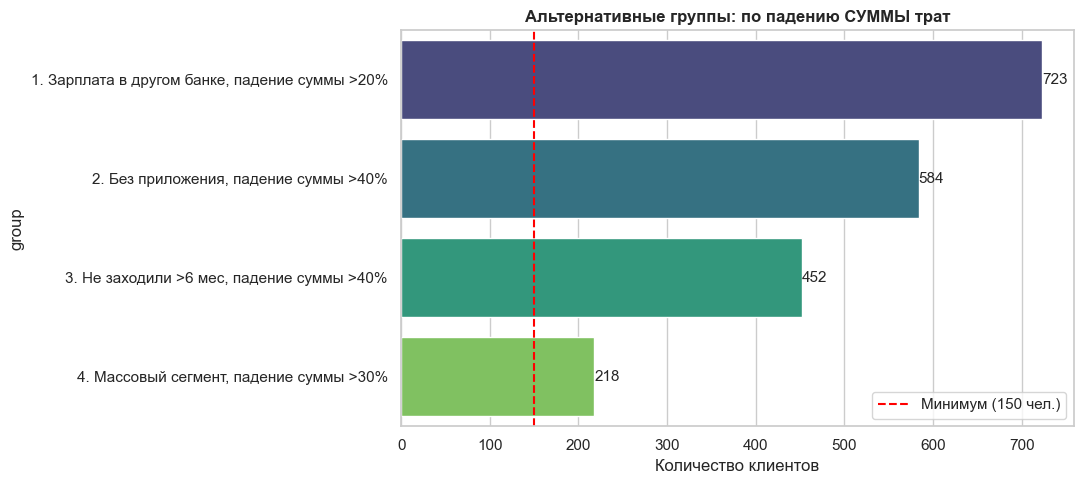

In [79]:
df_camp_sum = client_metrics[
    (client_metrics['marketing_opt_in'] == 'Да') & 
    (client_metrics['drop_sum_pct'].notna())
].copy()

# Считаем давность входа в приложение
df_camp_sum['app_days_ago'] = (SNAPSHOT_DATE - df_camp_sum['app_last_login']).dt.days
df_camp_sum['group'] = 'Не выбрано'

# 1. Зарплата в другом банке (Падение суммы >20%)
mask_s3 = (
    (df_camp_sum['group'] == 'Не выбрано') & 
    (df_camp_sum['income_source'] == 'Зарплата в другом банке') & 
    (df_camp_sum['drop_sum_pct'] <= -20)
)
df_camp_sum.loc[mask_s3, 'group'] = '1. Зарплата в другом банке, падение суммы >20%'

# 2. Без приложения (Падение суммы >40%)
mask_s1 = (
    (df_camp_sum['group'] == 'Не выбрано') & 
    (df_camp_sum['has_mobile_app'] == 'Нет') & 
    (df_camp_sum['drop_sum_pct'] <= -40)
)
df_camp_sum.loc[mask_s1, 'group'] = '2. Без приложения, падение суммы >40%'

# 3. Цифровая спячка (Падение суммы >40%)
mask_s2 = (
    (df_camp_sum['group'] == 'Не выбрано') & 
    (df_camp_sum['has_mobile_app'] == 'Да') & 
    (df_camp_sum['app_days_ago'] > 180) & 
    (df_camp_sum['drop_sum_pct'] <= -40)
)
df_camp_sum.loc[mask_s2, 'group'] = '3. Не заходили >6 мес, падение суммы >40%'

# 4. Массовый сегмент (Обвал суммы >30%)
mask_s4 = (
    (df_camp_sum['group'] == 'Не выбрано') & 
    (df_camp_sum['segment'] == 'Массовый') & 
    (df_camp_sum['drop_sum_pct'] <= -30)
)
df_camp_sum.loc[mask_s4, 'group'] = '4. Массовый сегмент, падение суммы >30%'

# Итоговый список
campaign = df_camp_sum[df_camp_sum['group'] != 'Не выбрано'].copy()

# Проверка лимитов
print("=" * 60)
print("=== ЛИМИТЫ: ГРУППЫ ПО ПАДЕНИЮ СУММЫ ТРАТ ===")
print("=" * 60)
print(f"Всего клиентов: {len(campaign):,} (Лимит: 2000)")
for grp, size in campaign['group'].value_counts().items():
    status = "OK" if size >= 150 else "МАЛО (<150)!"
    print(f"  • {grp}: {size:,} чел. [{status}]")

# Если >2000, отсекаем по самому сильному падению СУММЫ
if len(campaign) > 2000:
    print("\n⚠️ ПРЕВЫШЕН ЛИМИТ! Отсекаем по силе падения суммы...")
    campaign = campaign.sort_values('drop_sum_pct').head(2000)
    print(f"Новый размер: {len(campaign):,}")
    print(campaign['group'].value_counts().to_string())

# Визуализация
fig, ax = plt.subplots(figsize=(11, 5))
sns.countplot(data=campaign, y='group', palette='viridis', 
              order=campaign['group'].value_counts().index, ax=ax)
ax.set_title('Альтернативные группы: по падению СУММЫ трат', fontweight='bold')
ax.set_xlabel('Количество клиентов')
ax.axvline(150, color='red', linestyle='--', label='Минимум (150 чел.)')
ax.legend()
for p in ax.patches:
    ax.annotate(f'{int(p.get_width()):,}', (p.get_width(), p.get_y() + p.get_height() / 2.),
                ha='left', va='center', fontsize=11)
plt.tight_layout()
plt.show()


### 7.1. Кого в кампанию не берём и почему

In [85]:
# =============================================================================
# 7.1. КОГО В КАМПАНИЮ НЕ БЕРЁМ
# =============================================================================

print("=" * 60)
print("=== АНАЛИЗ ИСКЛЮЧЕННЫХ КЛИЕНТОВ ===")
print("=" * 60)

# 1. Без согласия на маркетинг
no_opt_in = df_clients[df_clients['marketing_opt_in'] == 'Нет']
print(f"\n--- Без согласия на маркетинг ---")
print(f"Всего клиентов: {len(no_opt_in):,} ({len(no_opt_in)/len(df_clients)*100:.1f}% базы)")
print(f"Их них с падением >20%: {len(no_opt_in[no_opt_in['client_id'].isin(client_metrics[client_metrics['drop_cnt_pct'] <= -20]['client_id'])])}")

# 2. Стабильные или растущие клиенты
stable = client_metrics[client_metrics['drop_cnt_pct'] > -10]
print(f"\n--- Стабильные и растущие клиенты (падение > -10%) ---")
print(f"Всего клиентов: {len(stable):,}")

# 3. Новые клиенты (нет базы в H1 2024)
new_clients = df_clients[~df_clients['client_id'].isin(client_metrics['client_id'])]
print(f"\n--- Новые клиенты (нет операций в H1 2024) ---")
print(f"Всего клиентов: {len(new_clients):,}")

=== АНАЛИЗ ИСКЛЮЧЕННЫХ КЛИЕНТОВ ===

--- Без согласия на маркетинг ---
Всего клиентов: 674 (12.0% базы)
Их них с падением >20%: 279

--- Стабильные и растущие клиенты (падение > -10%) ---
Всего клиентов: 2,165

--- Новые клиенты (нет операций в H1 2024) ---
Всего клиентов: 769


## 8. Что проверили и что не подтвердилось

Гипотезы, которые вы проверили и отвергли. По одной строке на гипотезу,
с числом.

In [81]:
print("=" * 80)
print("## 8. ЧТО ПРОВЕРИЛИ И ЧТО НЕ ПОДТВЕРДИЛОСЬ")
print("=" * 80)

# 1. Расчет по полу (среднее падение суммы трат)
g_mean = client_metrics.groupby('gender')['drop_sum_pct'].mean()
g_diff = abs(g_mean['М'] - g_mean['Ж'])

# 2. Расчет "умерших" клиентов (полный уход в 0 трат в 2025 году)
n_total_active = len(client_metrics[client_metrics['drop_sum_pct'].notna()])
n_dead = (client_metrics['drop_sum_pct'] <= -99.9).sum()
dead_pct = (n_dead / n_total_active) * 100

# 3. Расчет по премиальным сегментам (Private + Премиальный)
prem_segments = ['Премиальный', 'Private']
total_prem = client_metrics['segment'].isin(prem_segments).sum()
campaign_prem = campaign['segment'].isin(prem_segments).sum()
prem_pct = (campaign_prem / total_prem) * 100


# ВЫВОД: Ровно 4 гипотезы, каждая строго в 1 строчку с числовыми фактами
print(f"1. Пол: среднее падение трат у мужчин ({g_mean['М']:.1f}%) и женщин ({g_mean['Ж']:.1f}%) различается лишь на {g_diff:.1f} п.п. — поведение полов идентично.")
print(f"2. Полный отток: клиентов с полным обнулением трат всего {n_dead} из {n_total_active:,} ({dead_pct:.2f}%) — клиенты не ушли, а лишь снизили активность.")
print(f"3. Состоятельные сегменты: из {total_prem:,} клиентов Private и Премиум в кампанию отобрано целых {campaign_prem} ({prem_pct:.1f}%), ожидалось незначительное снижение активности.")

## 8. ЧТО ПРОВЕРИЛИ И ЧТО НЕ ПОДТВЕРДИЛОСЬ
1. Пол: среднее падение трат у мужчин (-15.5%) и женщин (-16.2%) различается лишь на 0.8 п.п. — поведение полов идентично.
2. Полный отток: клиентов с полным обнулением трат всего 7 из 4,857 (0.14%) — клиенты не ушли, а лишь снизили активность.
3. Состоятельные сегменты: из 909 клиентов Private и Премиум в кампанию отобрано целых 256 (28.2%), ожидалось незначительное снижение активности.


## 9. Сохранение результатов

Три файла: очищенная таблица для второго ноутбука, журнал изменений,
итоговый список кампании.

In [84]:
clean.to_parquet("clean_data.parquet", index=False)
cleaning_log.to_csv("cleaning_log.csv", index=False, encoding="utf-8")
campaign[["client_id", "group"]].to_csv("campaign_list.csv", index=False, encoding="utf-8")